# Ulcerative Colitis & Anti-TNF Non-Response — Bioinformatics / Systems Biology Pipeline

**Working title:** *Multi-Cohort Transcriptomic and Systems Biology Analysis of Ulcerative Colitis and Anti-TNF Non-Response: Prioritizing Druggable Hub Targets for Structure-Based Drug Discovery*

## Part 0 · Dataset verification & cohort-overlap audit

No analysis starts until this part is complete and every dataset is approved.

This part:
1. Downloads the GEO series-matrix file of each **candidate** dataset (metadata + expression).
2. Reports platform, sample count, submitting institute and all sample annotations (diagnosis, inflammation status, treatment, response, time point, patient ID).
3. Audits **overlap between cohorts** in three ways:
   - identical GSM IDs shared between series,
   - shared patient / subject identifiers,
   - near-identical expression profiles (the same array re-deposited under a new ID).

The candidate list below is a starting point to be verified, not an approved list.

All outputs → `MyDrive/UC_AntiTNF/00_dataset_verification/`


In [1]:
# Cell 1 — Mount Google Drive and create the project folders
from google.colab import drive
drive.mount('/content/drive')

import os
PROJECT_DIR = '/content/drive/MyDrive/UC_AntiTNF'
STEP_DIR    = os.path.join(PROJECT_DIR, '00_dataset_verification')
RAW_DIR     = os.path.join(PROJECT_DIR, 'raw_geo')          # shared cache for all later parts
RES_DIR     = os.path.join(STEP_DIR, 'results')
FIG_DIR     = os.path.join(STEP_DIR, 'figures')
for d in (PROJECT_DIR, STEP_DIR, RAW_DIR, RES_DIR, FIG_DIR):
    os.makedirs(d, exist_ok=True)
print('Project folder:', PROJECT_DIR)

Mounted at /content/drive
Project folder: /content/drive/MyDrive/UC_AntiTNF


In [ ]:
# Cell 2 — Candidate datasets (TO BE VERIFIED by this notebook)
# 'role' is the intended use IF verification passes; 'note' records what we expect to find.
CANDIDATES = {
    'GSE87466': dict(role='discovery: UC vs control',             note='colonic mucosa, UC vs normal'),
    'GSE92415': dict(role='validation + golimumab response',      note='colonic mucosa, UC vs normal; golimumab response'),
    'GSE75214': dict(role='validation: UC vs control',            note='colonic mucosa, UC/CD vs control'),
    'GSE16879': dict(role='infliximab response',                  note='UC/CD mucosa before/after infliximab; responders vs non-responders'),
    'GSE12251': dict(role='infliximab response',                  note='UC mucosa before infliximab; responders vs non-responders'),
    'GSE73661': dict(role='infliximab / vedolizumab response',    note='UC mucosa; biologic response'),
    'GSE23597': dict(role='infliximab response',                  note='UC mucosa; infliximab trial'),
}
SIMILARITY_CUT = 0.99   # Spearman r between two samples from DIFFERENT series flagged as possible duplicate
TOP_VAR_PROBES = 5000   # probes used for the expression-similarity audit
print(len(CANDIDATES), 'candidate datasets')

In [ ]:
# Cell 3 — Helpers: download and parse GEO series-matrix files
import re, gzip, io, requests, pandas as pd, numpy as np

def matrix_urls(gse):
    stub = gse[:-3] + 'nnn'
    base = f'https://ftp.ncbi.nlm.nih.gov/geo/series/{stub}/{gse}/matrix/'
    html = requests.get(base, timeout=60).text
    files = sorted(set(re.findall(r'href="(GSE[^"]*series_matrix\.txt\.gz)"', html)))
    return [base + f for f in files]

def download(url):
    path = os.path.join(RAW_DIR, url.split('/')[-1])
    if not os.path.exists(path):
        r = requests.get(url, timeout=600); r.raise_for_status()
        open(path, 'wb').write(r.content)
    return path

def parse_series_matrix(path):
    series, samples, table = {}, {}, []
    in_table = False
    with gzip.open(path, 'rt', encoding='utf-8', errors='replace') as fh:
        for line in fh:
            line = line.rstrip('\n')
            if line.startswith('!series_matrix_table_begin'):
                in_table = True; continue
            if line.startswith('!series_matrix_table_end'):
                break
            if in_table:
                table.append(line); continue
            if not line.startswith('!'):
                continue
            parts = [p.strip().strip('"') for p in line.split('\t')]
            key, vals = parts[0][1:], parts[1:]
            if key.startswith('Series_'):
                series.setdefault(key, []).append(' '.join(vals))
            elif key.startswith('Sample_'):
                samples.setdefault(key, []).append(vals)
    gsm = samples['Sample_geo_accession'][0]
    meta = pd.DataFrame(index=gsm)
    for key, rows in samples.items():
        if key == 'Sample_characteristics_ch1':
            for row in rows:
                for g, v in zip(gsm, row):
                    if ':' in v:
                        k, val = v.split(':', 1)
                        meta.loc[g, 'char_' + k.strip().lower()] = val.strip()
                    elif v:
                        meta.loc[g, 'char_unlabelled'] = v
        else:
            meta[key.replace('Sample_', '')] = rows[0] if len(rows) == 1 else [' | '.join(x) for x in zip(*rows)]
    expr = None
    if len(table) > 1:
        expr = pd.read_csv(io.StringIO('\n'.join(table)), sep='\t', index_col=0)
        expr.columns = [c.strip('"') for c in expr.columns]
        expr = expr.apply(pd.to_numeric, errors='coerce')
    return series, meta, expr


In [ ]:
# Cell 4 — Download and parse every candidate (cached in Drive; first run may take several minutes)
DATA = {}
for gse in CANDIDATES:
    try:
        urls = matrix_urls(gse)
        if not urls:
            print(f'{gse}: no series-matrix file found'); continue
        for url in urls:                       # some series have one file per platform
            series, meta, expr = parse_series_matrix(download(url))
            tag = gse if len(urls) == 1 else f"{gse}|{meta['platform_id'].iloc[0]}"
            DATA[tag] = dict(series=series, meta=meta, expr=expr)
            n_expr = 0 if expr is None else expr.shape[0]
            print(f'{tag}: {len(meta)} samples | platform {meta.platform_id.iloc[0]} | {n_expr} features')
    except Exception as e:
        print(f'{gse}: FAILED — {e}')

In [ ]:
# Cell 5 — Dataset summary table
rows = []
for tag, d in DATA.items():
    s, m = d['series'], d['meta']
    gse = tag.split('|')[0]
    rows.append({
        'dataset': tag,
        'title': s.get('Series_title', [''])[0],
        'platform': m['platform_id'].iloc[0],
        'n_samples': len(m),
        'institute': '; '.join(sorted(set(m.get('contact_institute', pd.Series(['NA'])).astype(str)))),
        'submitted': s.get('Series_submission_date', [''])[0],
        'pubmed': ' '.join(s.get('Series_pubmed_id', [])),
        'intended_role': CANDIDATES[gse]['role'],
    })
summary = pd.DataFrame(rows)
summary.to_csv(os.path.join(RES_DIR, 'T0_dataset_summary.csv'), index=False)
pd.set_option('display.max_colwidth', 80)
display(summary)

In [ ]:
# Cell 6 — Every sample annotation, tabulated per dataset
# This is where the exact numbers come from: diagnosis, inflammation, treatment, response, time point, patient ID.
ann_rows = []
for tag, d in DATA.items():
    m = d['meta']
    keep = [c for c in m.columns if c.startswith('char_') or c in ('source_name_ch1', 'title')]
    m[keep].to_csv(os.path.join(RES_DIR, f'T0_annotations_{tag.replace("|", "_")}.csv'))
    print('=' * 100); print(tag, '—', len(m), 'samples'); print('=' * 100)
    for c in keep:
        if c == 'title': continue
        vc = m[c].fillna('NA').value_counts()
        if len(vc) <= 25:
            print(f'\n[{c}]'); print(vc.to_string())
            for val, n in vc.items():
                ann_rows.append({'dataset': tag, 'field': c, 'value': val, 'n': int(n)})
        else:
            print(f'\n[{c}] {len(vc)} distinct values (likely patient/sample IDs)')
            ann_rows.append({'dataset': tag, 'field': c, 'value': f'<{len(vc)} distinct>', 'n': len(m)})
pd.DataFrame(ann_rows).to_csv(os.path.join(RES_DIR, 'T0_annotation_counts_all.csv'), index=False)

In [ ]:
# Cell 7 — Overlap audit A: identical GSM IDs and shared patient identifiers
from itertools import combinations
gsm_sets = {t: set(d['meta'].index) for t, d in DATA.items()}
shared = []
for a, b in combinations(gsm_sets, 2):
    inter = gsm_sets[a] & gsm_sets[b]
    if inter:
        shared.append({'dataset_A': a, 'dataset_B': b, 'n_shared_GSM': len(inter),
                       'examples': ', '.join(sorted(inter)[:5])})
shared = pd.DataFrame(shared, columns=['dataset_A', 'dataset_B', 'n_shared_GSM', 'examples'])
shared.to_csv(os.path.join(RES_DIR, 'T0_overlap_shared_GSM.csv'), index=False)
print('Shared GSM IDs between series:'); display(shared if len(shared) else 'none')

id_like = re.compile(r'patient|subject|donor|individual|case|\bid\b')
pid = []
for t, d in DATA.items():
    for c in d['meta'].columns:
        if c.startswith('char_') and id_like.search(c):
            for v in d['meta'][c].dropna().astype(str):
                pid.append({'dataset': t, 'field': c, 'patient_id': v.strip()})
pid = pd.DataFrame(pid, columns=['dataset', 'field', 'patient_id'])
dup = pid.groupby('patient_id')['dataset'].nunique()
cross = pid[pid.patient_id.isin(dup[dup > 1].index)].sort_values('patient_id')
cross.to_csv(os.path.join(RES_DIR, 'T0_overlap_shared_patient_ids.csv'), index=False)
print('\nPatient-ID fields found in:', sorted(pid.dataset.unique()) or 'none')
print('Identical patient IDs appearing in more than one series:', cross.patient_id.nunique())
print('(Same ID string in two series is a flag to inspect, not proof: different studies may reuse simple numbering.)')

In [ ]:
# Cell 8 — Overlap audit B: near-identical expression profiles across series (same platform only)
from scipy.stats import rankdata
import matplotlib.pyplot as plt

def ranked(expr, probes):
    x = expr.loc[probes].dropna(axis=1, how='all')
    x = x.apply(lambda col: col.fillna(col.median()))
    return pd.DataFrame(np.apply_along_axis(rankdata, 0, x.values), index=x.index, columns=x.columns)

by_platform = {}
for t, d in DATA.items():
    if d['expr'] is not None and d['expr'].shape[0] > 1000:
        by_platform.setdefault(d['meta'].platform_id.iloc[0], []).append(t)
print('Datasets with expression, grouped by platform:', by_platform)

flags, pair_stats = [], []
for plat, tags in by_platform.items():
    if len(tags) < 2: continue
    common = set.intersection(*[set(DATA[t]['expr'].index) for t in tags])
    pooled = pd.concat([DATA[t]['expr'].loc[list(common)].rank(pct=True) for t in tags], axis=1)
    probes = pooled.var(axis=1).sort_values(ascending=False).index[:TOP_VAR_PROBES]
    R = {t: ranked(DATA[t]['expr'], probes) for t in tags}
    # Reference: highest correlation between DIFFERENT samples within the same series
    for t in tags:
        c = np.corrcoef(R[t].values.T); np.fill_diagonal(c, np.nan)
        pair_stats.append({'platform': plat, 'comparison': f'{t} (within)', 'max_r': np.nanmax(c),
                           'p99.9_r': np.nanpercentile(c, 99.9), 'n_flagged': int((c >= SIMILARITY_CUT).sum() // 2)})
    for a, b in combinations(tags, 2):
        A, B = R[a].values, R[b].values
        A = (A - A.mean(0)) / A.std(0); B = (B - B.mean(0)) / B.std(0)
        c = A.T @ B / A.shape[0]
        hit = np.argwhere(c >= SIMILARITY_CUT)
        for i, j in hit:
            flags.append({'platform': plat, 'dataset_A': a, 'GSM_A': R[a].columns[i],
                          'dataset_B': b, 'GSM_B': R[b].columns[j], 'spearman_r': round(float(c[i, j]), 5)})
        pair_stats.append({'platform': plat, 'comparison': f'{a} vs {b}', 'max_r': float(c.max()),
                           'p99.9_r': float(np.percentile(c, 99.9)), 'n_flagged': len(hit)})
        plt.figure(figsize=(5, 3))
        plt.hist(c.ravel(), bins=100, color='#5D6D7E')
        plt.axvline(SIMILARITY_CUT, ls='--', c='#C0392B')
        plt.title(f'{a} vs {b}: cross-series sample correlation', fontsize=9)
        plt.xlabel('Spearman r'); plt.ylabel('sample pairs'); plt.tight_layout()
        plt.savefig(os.path.join(FIG_DIR, f'S0_similarity_{a}_vs_{b}.png'.replace('|', '_')), dpi=300)
        plt.show()

pair_stats = pd.DataFrame(pair_stats)
flags = pd.DataFrame(flags, columns=['platform', 'dataset_A', 'GSM_A', 'dataset_B', 'GSM_B', 'spearman_r'])
pair_stats.to_csv(os.path.join(RES_DIR, 'T0_overlap_expression_pairwise_stats.csv'), index=False)
flags.to_csv(os.path.join(RES_DIR, 'T0_overlap_expression_flagged_pairs.csv'), index=False)
display(pair_stats.round(4))
print(f'\nCross-series sample pairs with r >= {SIMILARITY_CUT}: {len(flags)}')
print('Interpretation: compare cross-series max_r with the within-series reference.')
print('Cross-series values at or above the within-series maximum suggest the same biological sample.')

In [ ]:
# Cell 9 — Verification report (send these files back before any analysis)
import json, datetime
report = {
    'date': datetime.datetime.now().isoformat(timespec='seconds'),
    'datasets_parsed': list(DATA.keys()),
    'shared_GSM_pairs': int(len(shared)),
    'shared_patient_ids': int(cross.patient_id.nunique()),
    'expression_flagged_pairs': int(len(flags)),
    'similarity_cut': SIMILARITY_CUT,
}
json.dump(report, open(os.path.join(STEP_DIR, 'verification_report.json'), 'w'), indent=2)
print(json.dumps(report, indent=2))
print('\nFiles to send back:')
for f in ['T0_dataset_summary.csv', 'T0_annotation_counts_all.csv', 'T0_overlap_shared_GSM.csv',
          'T0_overlap_shared_patient_ids.csv', 'T0_overlap_expression_pairwise_stats.csv',
          'T0_overlap_expression_flagged_pairs.csv']:
    print('  -', os.path.join(RES_DIR, f))

In [ ]:
# Cell 10 — Package Part 0 outputs into a ZIP and download
import shutil
from google.colab import files
ZIP_BASE = os.path.join(PROJECT_DIR, 'UC_Part0_verification')
shutil.make_archive(ZIP_BASE, 'zip', root_dir=STEP_DIR)
files.download(ZIP_BASE + '.zip')

# Part 1 · Preprocessing, quality control and differential expression

**Approved cohort design (from Part 0 audit)**

| Layer | Role | Dataset | Comparison |
|---|---|---|---|
| L1 — UC vs control | Discovery | GSE92415 (Week 0 + healthy) | UC vs healthy |
| | Validation | GSE75214 (colon) | active UC vs control |
| L2 — anti-TNF response (pre-treatment biopsy) | Discovery | GSE92415 W0, golimumab arm | non-responder vs responder (week 6) |
| | Validation (other drug) | GSE16879 UC, before infliximab | non-responder vs responder |
| | Validation (other drug) | GSE23597 W0, infliximab arms | non-responder vs responder (week 8) |
| | Negative control | GSE92415 W0, placebo arm | non-responder vs responder |

**Excluded after audit:** GSE87466 (subset of GSE92415), GSE12251 (subset of GSE23597), GSE73661 (73 samples shared with GSE75214).

This part is self-contained: it reloads the series-matrix files cached in Drive by Part 0.
Statistics: **limma** (R/Bioconductor; `lmFit` → `eBayes(trend=TRUE, robust=TRUE)`, Benjamini–Hochberg FDR).
Outputs → `MyDrive/UC_AntiTNF/01_preprocessing_DEG/`


In [ ]:
# Cell 1.1 — Mount Drive, folders, extra package
!pip -q install adjustText
from google.colab import drive
drive.mount('/content/drive')

import os
PROJECT_DIR = '/content/drive/MyDrive/UC_AntiTNF'
RAW_DIR  = os.path.join(PROJECT_DIR, 'raw_geo')
P1_DIR   = os.path.join(PROJECT_DIR, '01_preprocessing_DEG')
EXPR_DIR = os.path.join(P1_DIR, 'expression')   # gene-level matrices reused by later parts
RES_DIR  = os.path.join(P1_DIR, 'results')
FIG_DIR  = os.path.join(P1_DIR, 'figures')
QC_DIR   = os.path.join(P1_DIR, 'qc')
TMP_DIR  = '/content/limma_tmp'
for d in (P1_DIR, EXPR_DIR, RES_DIR, FIG_DIR, QC_DIR, TMP_DIR):
    os.makedirs(d, exist_ok=True)
assert os.path.isdir(RAW_DIR), 'Run Part 0 first (series matrices are cached there).'
print('Part 1 folder:', P1_DIR)

In [ ]:
# Cell 1.2 — Pre-specified analysis parameters (fixed BEFORE looking at results)
DATASETS = ['GSE92415', 'GSE75214', 'GSE16879', 'GSE23597']

# L1 (disease) thresholds
L1_FDR, L1_LFC = 0.05, 1.0
# L2 (response) thresholds — response signals in baseline biopsies are expected to be weaker,
# so discovery uses a nominal threshold and genes must REPLICATE in independent infliximab cohorts.
L2_P, L2_LFC = 0.01, 0.5
REPL_P = 0.05            # replication: same direction and P < 0.05 in a validation cohort

LOW_EXPR_QUANTILE = 0.25 # drop genes whose mean expression is in the lowest 25% within a dataset
N_BOOT = 2000            # bootstrap iterations for AUC confidence intervals
SEED = 2026

# Samples to exclude after QC review (fill only with a documented reason), e.g. {'GSM1234567': 'RNA degradation outlier'}
EXCLUDE = {}
print('Parameters set.')

In [ ]:
# Cell 1.3 — R + limma (installs limma once if missing; ~2–4 min the first time)
import subprocess, shutil
assert shutil.which('Rscript'), 'Rscript not found in this runtime.'
chk = subprocess.run(['Rscript', '-e', 'suppressMessages(library(limma)); cat(as.character(packageVersion("limma")))'],
                     capture_output=True, text=True)
if chk.returncode != 0:
    print('Installing limma ...')
    subprocess.run(['Rscript', '-e',
        'if (!requireNamespace("BiocManager", quietly=TRUE)) install.packages("BiocManager", repos="https://cloud.r-project.org"); '
        'BiocManager::install("limma", ask=FALSE, update=FALSE)'], check=True)
    chk = subprocess.run(['Rscript', '-e', 'suppressMessages(library(limma)); cat(as.character(packageVersion("limma")))'],
                         capture_output=True, text=True)
LIMMA_VERSION = chk.stdout.strip()
R_VERSION = subprocess.run(['Rscript', '-e', 'cat(R.version.string)'], capture_output=True, text=True).stdout.strip()
print('limma', LIMMA_VERSION, '|', R_VERSION)

LIMMA_R = os.path.join(TMP_DIR, 'run_limma.R')
open(LIMMA_R, 'w').write('''
suppressMessages(library(limma))
a    <- commandArgs(TRUE)
e    <- as.matrix(read.csv(a[1], row.names = 1, check.names = FALSE))
p    <- read.csv(a[2], row.names = 1, check.names = FALSE, stringsAsFactors = FALSE)
e    <- e[, rownames(p), drop = FALSE]
p$group <- factor(p$group, levels = c(a[4], a[5]))       # reference (control) first, then case
covs <- if (length(a) >= 6 && nchar(a[6]) > 0) strsplit(a[6], ",")[[1]] else character(0)
d    <- model.matrix(as.formula(paste("~", paste(c("group", covs), collapse = " + "))), data = p)
fit  <- eBayes(lmFit(e, d), trend = TRUE, robust = TRUE)
tt   <- topTable(fit, coef = 2, number = Inf, sort.by = "P")
write.csv(tt, a[3])
''')
print('limma script ready.')

In [ ]:
# Cell 1.4 — Helpers: series-matrix parser, platform annotation, log check, probe→gene collapse
import re, gzip, io, requests, numpy as np, pandas as pd

def parse_series_matrix(path):
    samples, table, in_table = {}, [], False
    with gzip.open(path, 'rt', encoding='utf-8', errors='replace') as fh:
        for line in fh:
            line = line.rstrip('\n')
            if line.startswith('!series_matrix_table_begin'): in_table = True; continue
            if line.startswith('!series_matrix_table_end'): break
            if in_table: table.append(line); continue
            if line.startswith('!Sample_'):
                parts = [x.strip().strip('"') for x in line.split('\t')]
                samples.setdefault(parts[0][1:], []).append(parts[1:])
    gsm = samples['Sample_geo_accession'][0]
    meta = pd.DataFrame(index=gsm)
    for key, rows in samples.items():
        if key == 'Sample_characteristics_ch1':
            for row in rows:
                for g, v in zip(gsm, row):
                    if ':' in v:
                        k, val = v.split(':', 1)
                        meta.loc[g, 'char_' + k.strip().lower()] = val.strip()
        else:
            meta[key.replace('Sample_', '')] = rows[0] if len(rows) == 1 else [' | '.join(x) for x in zip(*rows)]
    expr = pd.read_csv(io.StringIO('\n'.join(table)), sep='\t', index_col=0)
    expr.columns = [c.strip('"') for c in expr.columns]
    expr.index = expr.index.astype(str).str.strip('"')
    return meta, expr.apply(pd.to_numeric, errors='coerce')

def load_gse(gse):
    files = sorted(f for f in os.listdir(RAW_DIR) if f.startswith(gse) and f.endswith('series_matrix.txt.gz'))
    assert len(files) == 1, f'{gse}: expected one cached series matrix, found {files}'
    return parse_series_matrix(os.path.join(RAW_DIR, files[0]))

def platform_table(gpl):
    path = os.path.join(RAW_DIR, f'{gpl}_family.soft.gz')
    if not os.path.exists(path):
        url = f'https://ftp.ncbi.nlm.nih.gov/geo/platforms/{gpl[:-3]}nnn/{gpl}/soft/{gpl}_family.soft.gz'
        r = requests.get(url, timeout=900); r.raise_for_status()
        open(path, 'wb').write(r.content)
    rows, inside = [], False
    with gzip.open(path, 'rt', encoding='utf-8', errors='replace') as fh:
        for line in fh:
            if line.startswith('!platform_table_begin'): inside = True; continue
            if line.startswith('!platform_table_end'): break
            if inside: rows.append(line.rstrip('\n'))
    tab = pd.read_csv(io.StringIO('\n'.join(rows)), sep='\t', dtype=str, low_memory=False)
    tab['ID'] = tab['ID'].astype(str).str.strip()
    return tab.set_index('ID')

def probe_to_symbol(tab):
    # Unambiguous probe → symbol map. Probes mapping to >1 gene are dropped (standard, conservative).
    if 'Gene Symbol' in tab.columns:
        s = tab['Gene Symbol'].fillna('').str.strip()
        s = s[(s != '') & (s != '---') & (~s.str.contains('///'))]
        return s
    if 'gene_assignment' in tab.columns:
        out = {}
        for pid, ga in tab['gene_assignment'].fillna('').items():
            if ga in ('', '---'): continue
            syms = {e.split(' // ')[1].strip() for e in ga.split(' /// ') if len(e.split(' // ')) > 1}
            syms.discard('---')
            if len(syms) == 1: out[pid] = syms.pop()
        return pd.Series(out)
    raise ValueError('No gene-symbol column found in platform table.')

def needs_log2(x):
    # GEO2R rule for deciding whether values are on a linear scale
    qx = np.nanquantile(x.values, [0, .25, .5, .75, .99, 1.0])
    return (qx[4] > 100) or (qx[5] - qx[0] > 50 and qx[1] > 0)

def to_gene_level(expr, sym):
    common = expr.index.intersection(sym.index)
    e = expr.loc[common].copy()
    e['__sym'] = sym.loc[common].values
    e['__mean'] = e.drop(columns='__sym').mean(axis=1)
    e = e.sort_values('__mean', ascending=False).drop_duplicates('__sym')   # keep most highly expressed probe per gene
    return e.set_index('__sym').drop(columns='__mean').rename_axis('gene')
print('Helpers ready.')

In [ ]:
# Cell 1.4b — FIX: robust platform annotation download (replaces platform_table / probe_to_symbol from Cell 1.4)
import gzip, io, os, requests, pandas as pd

HDR = {'User-Agent': 'Mozilla/5.0 (research pipeline; UC_AntiTNF)'}

def _get(url, timeout=900):
    r = requests.get(url, headers=HDR, timeout=timeout)
    return r if r.status_code == 200 and len(r.content) > 1000 else None

def _read_table(text):
    rows, inside = [], False
    for line in text.splitlines():
        if line.startswith('!platform_table_begin'): inside = True; continue
        if line.startswith('!platform_table_end'): break
        if inside: rows.append(line)
    if not rows:
        return None
    tab = pd.read_csv(io.StringIO('\n'.join(rows)), sep='\t', dtype=str, low_memory=False)
    tab['ID'] = tab['ID'].astype(str).str.strip()
    return tab.set_index('ID')

def platform_table(gpl):
    cache = os.path.join(RAW_DIR, f'{gpl}_platform_table.tsv.gz')
    if os.path.exists(cache):
        return pd.read_csv(cache, sep='\t', dtype=str, index_col='ID', low_memory=False)
    stub = gpl[:-3] + 'nnn'
    sources = [
        ('GEO annotation file', f'https://ftp.ncbi.nlm.nih.gov/geo/platforms/{stub}/{gpl}/annot/{gpl}.annot.gz', True),
        ('GEO platform record (full table)', f'https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc={gpl}&targ=self&form=text&view=data', False),
        ('GEO family SOFT', f'https://ftp.ncbi.nlm.nih.gov/geo/platforms/{stub}/{gpl}/soft/{gpl}_family.soft.gz', True),
    ]
    for label, url, gz in sources:
        try:
            r = _get(url)
            if r is None:
                print(f'  {gpl}: {label} not available'); continue
            raw = r.content
            if gz:
                if raw[:2] != b'\x1f\x8b':
                    print(f'  {gpl}: {label} returned non-gzip content'); continue
                raw = gzip.decompress(raw)
            tab = _read_table(raw.decode('utf-8', errors='replace'))
            if tab is None or tab.shape[0] < 1000:
                print(f'  {gpl}: {label} has no usable table'); continue
            tab.to_csv(cache, sep='\t')
            print(f'  {gpl}: annotation from {label} — {tab.shape[0]} probes, columns: {list(tab.columns)[:8]}')
            return tab
        except Exception as e:
            print(f'  {gpl}: {label} failed — {e}')
    raise RuntimeError(f'{gpl}: no annotation source worked. Upload {gpl} platform table manually to {RAW_DIR}.')

def probe_to_symbol(tab):
    # Unambiguous probe → symbol map; probes mapping to >1 gene are dropped.
    col = next((c for c in ('Gene Symbol', 'Gene symbol', 'GENE_SYMBOL', 'Symbol') if c in tab.columns), None)
    if col:
        s = tab[col].fillna('').astype(str).str.strip()
        return s[(s != '') & (s != '---') & (~s.str.contains('///'))]
    if 'gene_assignment' in tab.columns:
        out = {}
        for pid, ga in tab['gene_assignment'].fillna('').items():
            if ga in ('', '---'): continue
            syms = {e.split(' // ')[1].strip() for e in ga.split(' /// ') if len(e.split(' // ')) > 1}
            syms.discard('---')
            if len(syms) == 1: out[pid] = syms.pop()
        return pd.Series(out)
    raise ValueError(f'No gene-symbol column found. Columns: {list(tab.columns)}')
print('Annotation helpers replaced.')


In [ ]:
# Cell 1.5 — Load, annotate, log-check and collapse each dataset to gene level
GENE_EXPR, META, PREP_LOG = {}, {}, []
gpl_cache = {}
for gse in DATASETS:
    meta, expr = load_gse(gse)
    gpl = meta['platform_id'].iloc[0]
    if gpl not in gpl_cache:
        gpl_cache[gpl] = probe_to_symbol(platform_table(gpl))
    logged = needs_log2(expr)
    if logged:
        expr = np.log2(expr.where(expr > 0))
    n_map = int(expr.index.isin(gpl_cache[gpl].index).sum())
    print(f'{gse} ({gpl}): {expr.shape[0]} probes, {n_map} mapped to a unique gene symbol')
    if n_map < 0.3 * expr.shape[0]:
        cache = os.path.join(RAW_DIR, f'{gpl}_platform_table.tsv.gz')
        if os.path.exists(cache): os.remove(cache)          # stale/corrupt cache → force fresh download
        gpl_cache[gpl] = probe_to_symbol(platform_table(gpl))
        n_map = int(expr.index.isin(gpl_cache[gpl].index).sum())
        print(f'  re-downloaded annotation: {n_map} probes mapped')
    assert n_map > 0.3 * expr.shape[0], (f'{gse}: probe IDs do not match {gpl} annotation. '
        f'Example expression IDs: {list(expr.index[:3])}; annotation IDs: {list(gpl_cache[gpl].index[:3])}')
    g = to_gene_level(expr, gpl_cache[gpl])
    GENE_EXPR[gse], META[gse] = g, meta
    g.to_csv(os.path.join(EXPR_DIR, f'{gse}_gene_level_all_samples.csv.gz'))
    meta.to_csv(os.path.join(EXPR_DIR, f'{gse}_sample_metadata.csv'))
    PREP_LOG.append({'dataset': gse, 'platform': gpl, 'probes': expr.shape[0],
                     'mapped_unambiguous_probes': int(expr.index.isin(gpl_cache[gpl].index).sum()),
                     'genes': g.shape[0], 'samples': g.shape[1], 'log2_applied': bool(logged),
                     'value_range': f'{np.nanmin(g.values):.2f} – {np.nanmax(g.values):.2f}'})
prep = pd.DataFrame(PREP_LOG)
prep.to_csv(os.path.join(RES_DIR, 'T1_preprocessing_log.csv'), index=False)
display(prep)

In [ ]:
# Cell 1.6 — Sample sheets for each contrast (rules are explicit; counts printed for checking)
def sheet(gse, mask, group, extra=None):
    m = META[gse].loc[mask].copy()
    s = pd.DataFrame({'group': group(m)}, index=m.index)
    if extra: s = s.join(m[extra])
    s = s[~s.index.isin(EXCLUDE)]
    return s.dropna(subset=['group'])

def yesno(series, yes='R', no='NR'):
    return series.map({'Yes': yes, 'No': no})

M = META
SHEETS = {}
# L1 discovery — GSE92415: Week-0 UC biopsies (both arms, one per patient) + healthy
m = M['GSE92415']
SHEETS['L1_disc_GSE92415'] = sheet('GSE92415', m['char_visit'].isin(['Week 0', 'Healthy']),
    lambda d: np.where(d['char_disease'] == 'Healthy', 'Control', 'UC'), ['char_subject'])
# L1 validation — GSE75214: colon only; active UC vs control (Crohn's and inactive UC excluded)
m = M['GSE75214']
SHEETS['L1_val_GSE75214'] = sheet('GSE75214',
    (m['char_tissue'] == 'colon') & (((m['char_disease'] == 'ulcerative colitis') & (m['char_disease activity'] == 'active')) | (m['char_disease'] == 'control')),
    lambda d: np.where(d['char_disease'] == 'control', 'Control', 'UC'))
# L2 discovery — GSE92415: Week-0 golimumab arm, week-6 response
m = M['GSE92415']
SHEETS['L2_disc_GOL_GSE92415'] = sheet('GSE92415', (m['char_visit'] == 'Week 0') & (m['char_treatment'] == 'golimumab'),
    lambda d: yesno(d['char_wk6response']), ['char_subject', 'char_mayo score'])
# L2 negative control — GSE92415: Week-0 placebo arm
SHEETS['L2_placebo_GSE92415'] = sheet('GSE92415', (m['char_visit'] == 'Week 0') & (m['char_treatment'] == 'Placebo'),
    lambda d: yesno(d['char_wk6response']), ['char_subject', 'char_mayo score'])
# L2 validation — GSE16879: UC, before first infliximab
m = M['GSE16879']
SHEETS['L2_val_IFX_GSE16879'] = sheet('GSE16879',
    (m['char_disease'] == 'UC') & (m['char_before or after first infliximab treatment'] == 'Before first infliximab treatment'),
    lambda d: yesno(d['char_response to infliximab']))
# L2 validation — GSE23597: Week-0, infliximab arms (5 and 10 mg/kg), week-8 response; one sample per patient
m = M['GSE23597']
s = sheet('GSE23597', (m['char_time'] == 'W0') & (m['char_dose'] != 'placebo'),
          lambda d: yesno(d['char_wk8 response']), ['char_subject', 'char_dose'])
dups = s[s.duplicated('char_subject', keep=False)]
if len(dups):
    print('GSE23597 duplicated W0 patients (first sample kept):'); display(dups)
SHEETS['L2_val_IFX_GSE23597'] = s.drop_duplicates('char_subject', keep='first')

DATASET_OF = {k: k.split('_')[-1] for k in SHEETS}
counts = pd.DataFrame({k: v['group'].value_counts() for k, v in SHEETS.items()}).T.fillna(0).astype(int)
counts.to_csv(os.path.join(RES_DIR, 'T1_contrast_sample_counts.csv'))
display(counts)
for k, v in SHEETS.items():
    v.to_csv(os.path.join(EXPR_DIR, f'samplesheet_{k}.csv'))

In [ ]:
# Cell 1.7 — Quality control: distributions, PCA, correlation outliers, inferred sex
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 9})

QC_ROWS = []
for gse in DATASETS:
    used = sorted(set().union(*[SHEETS[k].index for k in SHEETS if DATASET_OF[k] == gse]))
    g = GENE_EXPR[gse][used].dropna()
    grp = pd.concat([SHEETS[k]['group'] for k in SHEETS if DATASET_OF[k] == gse])
    grp = grp[~grp.index.duplicated()].reindex(used)
    top = g.loc[g.var(axis=1).sort_values(ascending=False).index[:2000]]

    # (a) distributions
    fig, ax = plt.subplots(figsize=(max(6, len(used) * 0.06), 3))
    ax.boxplot(g.values, showfliers=False, widths=.6); ax.set_xticks([])
    ax.set_title(f'{gse} — expression distributions (n={len(used)})'); ax.set_ylabel('log2 expression')
    fig.tight_layout(); fig.savefig(os.path.join(QC_DIR, f'QC_box_{gse}.png'), dpi=300); plt.close(fig)

    # (b) PCA
    z = (top.T - top.T.mean()) / top.T.std()
    pca = PCA(n_components=2, random_state=SEED).fit(z)
    pc = pd.DataFrame(pca.transform(z), index=top.columns, columns=['PC1', 'PC2']).join(grp)
    fig, ax = plt.subplots(figsize=(4.5, 4))
    sns.scatterplot(data=pc, x='PC1', y='PC2', hue='group', s=28, ax=ax, edgecolor='none')
    ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)'); ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
    ax.set_title(gse); ax.legend(frameon=False, fontsize=7)
    fig.tight_layout(); fig.savefig(os.path.join(QC_DIR, f'QC_PCA_{gse}.png'), dpi=300); plt.show()

    # (c) correlation-based outliers: mean correlation to all other samples < median − 3·MAD
    c = np.corrcoef(top.T.values); np.fill_diagonal(c, np.nan)
    mc = pd.Series(np.nanmean(c, axis=1), index=top.columns)
    mad = (mc - mc.median()).abs().median()
    outl = mc < mc.median() - 3 * 1.4826 * mad

    # (d) inferred sex from XIST vs RPS4Y1 (cohort description + label sanity)
    sex = pd.Series('NA', index=used)
    if {'XIST', 'RPS4Y1'} <= set(g.index):
        d = (g.loc['RPS4Y1'] - g.loc['XIST']).values.reshape(-1, 1)
        km = KMeans(2, n_init=10, random_state=SEED).fit(d)
        male = int(np.argmax(km.cluster_centers_.ravel()))
        sex = pd.Series(np.where(km.labels_ == male, 'M', 'F'), index=used)

    for s in used:
        QC_ROWS.append({'dataset': gse, 'GSM': s, 'group': grp[s], 'mean_corr': round(mc[s], 4),
                        'outlier_flag': bool(outl[s]), 'inferred_sex': sex[s]})
    print(f'{gse}: {len(used)} samples | outlier flags: {int(outl.sum())} | inferred sex F/M: '
          f'{(sex=="F").sum()}/{(sex=="M").sum()}')

qc = pd.DataFrame(QC_ROWS)
qc.to_csv(os.path.join(RES_DIR, 'T1_sample_QC.csv'), index=False)
flagged = qc[qc.outlier_flag]
print('\nFlagged samples (inspect before excluding; add to EXCLUDE in Cell 1.2 only with a documented reason):')
display(flagged if len(flagged) else 'none')

In [ ]:
# Cell 1.8 — Differential expression with limma for all contrasts
DESIGN = {   # contrast: (reference level, case level)
    'L1_disc_GSE92415':     ('Control', 'UC'),
    'L1_val_GSE75214':      ('Control', 'UC'),
    'L2_disc_GOL_GSE92415': ('R', 'NR'),
    'L2_placebo_GSE92415':  ('R', 'NR'),
    'L2_val_IFX_GSE16879':  ('R', 'NR'),
    'L2_val_IFX_GSE23597':  ('R', 'NR'),
}

def run_limma(name, ref, case, covariates=''):
    s = SHEETS[name]
    g = GENE_EXPR[DATASET_OF[name]][s.index].dropna()
    g = g[g.mean(axis=1) > g.mean(axis=1).quantile(LOW_EXPR_QUANTILE)]   # low-expression filter within contrast
    ef, pf, of = (os.path.join(TMP_DIR, f'{name}_{x}.csv') for x in ('expr', 'pheno', 'out'))
    g.to_csv(ef); s[['group']].to_csv(pf)
    r = subprocess.run(['Rscript', LIMMA_R, ef, pf, of, ref, case, covariates], capture_output=True, text=True)
    if r.returncode != 0:
        raise RuntimeError(r.stderr)
    tt = pd.read_csv(of, index_col=0).rename_axis('gene')
    tt.to_csv(os.path.join(RES_DIR, f'DEG_{name}_{case}_vs_{ref}.csv'))
    return tt

DEG = {k: run_limma(k, *v) for k, v in DESIGN.items()}

def sig(name):
    t = DEG[name]
    if name.startswith('L1'):
        return t[(t['adj.P.Val'] < L1_FDR) & (t['logFC'].abs() >= L1_LFC)]
    return t[(t['P.Value'] < L2_P) & (t['logFC'].abs() >= L2_LFC)]

rows = []
for k, t in DEG.items():
    s_ = sig(k)
    rows.append({'contrast': k, 'genes_tested': len(t),
                 'threshold': f'FDR<{L1_FDR}, |logFC|≥{L1_LFC}' if k.startswith('L1') else f'P<{L2_P}, |logFC|≥{L2_LFC}',
                 'n_sig': len(s_), 'up': int((s_.logFC > 0).sum()), 'down': int((s_.logFC < 0).sum()),
                 'n_FDR<0.05': int((t['adj.P.Val'] < 0.05).sum())})
deg_summary = pd.DataFrame(rows)
deg_summary.to_csv(os.path.join(RES_DIR, 'T1_DEG_summary.csv'), index=False)
display(deg_summary)

In [ ]:
# Cell 1.9 — Volcano plots
from adjustText import adjust_text

def volcano(name):
    t = DEG[name].copy()
    ref, case = DESIGN[name]
    l1 = name.startswith('L1')
    ycol = 'adj.P.Val' if l1 else 'P.Value'
    ycut, lcut = (L1_FDR, L1_LFC) if l1 else (L2_P, L2_LFC)
    t['y'] = -np.log10(t[ycol].clip(lower=1e-300))
    up = (t[ycol] < ycut) & (t.logFC >= lcut); dn = (t[ycol] < ycut) & (t.logFC <= -lcut)
    fig, ax = plt.subplots(figsize=(5.2, 4.6))
    ax.scatter(t.loc[~(up | dn), 'logFC'], t.loc[~(up | dn), 'y'], s=4, c='#BDBDBD', lw=0, alpha=.6, label='NS')
    ax.scatter(t.loc[up, 'logFC'], t.loc[up, 'y'], s=6, c='#C0392B', lw=0, alpha=.85, label=f'Up in {case} ({up.sum()})')
    ax.scatter(t.loc[dn, 'logFC'], t.loc[dn, 'y'], s=6, c='#2471A3', lw=0, alpha=.85, label=f'Down in {case} ({dn.sum()})')
    lab = t[up | dn].nsmallest(12, ycol)
    texts = [ax.text(r.logFC, r.y, g, fontsize=7, fontstyle='italic') for g, r in lab.iterrows()]
    if texts: adjust_text(texts, ax=ax, arrowprops=dict(arrowstyle='-', lw=.5, color='k'))
    ax.axhline(-np.log10(ycut), ls='--', lw=.6, c='k')
    for v in (-lcut, lcut): ax.axvline(v, ls='--', lw=.6, c='k')
    ax.set_xlabel(f'log$_2$ fold change ({case} vs {ref})')
    ax.set_ylabel('$-$log$_{10}$ FDR' if l1 else '$-$log$_{10}$ $P$')
    ax.set_title(name.replace('_', ' '), fontsize=9)
    ax.legend(frameon=False, fontsize=7, loc='upper left'); ax.spines[['top', 'right']].set_visible(False)
    fig.tight_layout()
    for ext in ('png', 'pdf'):
        fig.savefig(os.path.join(FIG_DIR, f'Volcano_{name}.{ext}'), dpi=600, bbox_inches='tight')
    plt.show()

for k in DEG: volcano(k)

In [ ]:
# Cell 1.10 — L1 replication: discovery (GSE92415) vs independent validation (GSE75214)
from scipy.stats import pearsonr, hypergeom
d, v = DEG['L1_disc_GSE92415'], DEG['L1_val_GSE75214']
common = d.index.intersection(v.index)
sd, sv = sig('L1_disc_GSE92415'), sig('L1_val_GSE75214')
sd_c, sv_c = sd.index.intersection(common), sv.index.intersection(common)
both = sd_c.intersection(sv_c)
concordant = both[np.sign(d.loc[both, 'logFC']) == np.sign(v.loc[both, 'logFC'])]
r, p = pearsonr(d.loc[common, 'logFC'], v.loc[common, 'logFC'])
p_hyper = hypergeom.sf(len(both) - 1, len(common), len(sd_c), len(sv_c))

L1_CORE = d.loc[concordant, ['logFC', 'adj.P.Val']].join(v.loc[concordant, ['logFC', 'adj.P.Val']], lsuffix='_disc', rsuffix='_val')
L1_CORE = L1_CORE.sort_values('adj.P.Val_disc')
L1_CORE.to_csv(os.path.join(RES_DIR, 'L1_core_UC_DEGs_replicated.csv'))
print(f'Genes tested in both: {len(common)} | sig in discovery: {len(sd_c)} | sig in validation: {len(sv_c)}')
print(f'Sig in both: {len(both)} | same direction: {len(concordant)} (hypergeometric P = {p_hyper:.2e})')
print(f'Genome-wide logFC correlation: r = {r:.3f} (P = {p:.1e})')

fig, ax = plt.subplots(figsize=(4.6, 4.4))
ax.scatter(d.loc[common, 'logFC'], v.loc[common, 'logFC'], s=3, c='#BDBDBD', lw=0)
ax.scatter(d.loc[concordant, 'logFC'], v.loc[concordant, 'logFC'], s=6, c='#8E44AD', lw=0, label=f'Replicated DEGs ({len(concordant)})')
lim = np.nanmax(np.abs(np.r_[d.loc[common, 'logFC'], v.loc[common, 'logFC']])) * 1.05
ax.plot([-lim, lim], [-lim, lim], ls='--', lw=.6, c='k'); ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
ax.set_xlabel('log$_2$FC discovery (GSE92415)'); ax.set_ylabel('log$_2$FC validation (GSE75214)')
ax.set_title(f'UC vs control: r = {r:.2f}', fontsize=9); ax.legend(frameon=False, fontsize=7)
ax.spines[['top', 'right']].set_visible(False); fig.tight_layout()
for ext in ('png', 'pdf'):
    fig.savefig(os.path.join(FIG_DIR, f'L1_replication_scatter.{ext}'), dpi=600, bbox_inches='tight')
plt.show()

In [ ]:
# Cell 1.11 — L2 replication: golimumab discovery → infliximab validation + placebo negative control
from sklearn.metrics import roc_auc_score
from scipy.stats import mannwhitneyu
rng = np.random.default_rng(SEED)

disc = sig('L2_disc_GOL_GSE92415')
UP, DN = disc.index[disc.logFC > 0], disc.index[disc.logFC < 0]   # higher / lower in non-responders
print(f'L2 discovery signature: {len(disc)} genes ({len(UP)} up in NR, {len(DN)} down in NR)')

# (a) gene-level replication
rep = disc[['logFC', 'P.Value']].rename(columns={'logFC': 'logFC_GOL', 'P.Value': 'P_GOL'})
for k in ('L2_val_IFX_GSE16879', 'L2_val_IFX_GSE23597', 'L2_placebo_GSE92415'):
    t = DEG[k].reindex(disc.index)
    tag = k.replace('L2_', '').replace('_GSE', '_')
    rep[f'logFC_{tag}'], rep[f'P_{tag}'] = t['logFC'], t['P.Value']
    rep[f'replicated_{tag}'] = (np.sign(t['logFC']) == np.sign(disc['logFC'])) & (t['P.Value'] < REPL_P)
rep['n_IFX_cohorts_replicated'] = rep[['replicated_val_IFX_16879', 'replicated_val_IFX_23597']].sum(axis=1)
rep = rep.sort_values(['n_IFX_cohorts_replicated', 'P_GOL'], ascending=[False, True])
rep.to_csv(os.path.join(RES_DIR, 'L2_response_signature_replication.csv'))
print('Genes replicated in ≥1 infliximab cohort:', int((rep.n_IFX_cohorts_replicated >= 1).sum()),
      '| in both:', int((rep.n_IFX_cohorts_replicated == 2).sum()))

# (b) signature-score validation: score = mean z(up genes) − mean z(down genes), computed within each cohort
def score(name):
    s = SHEETS[name]; g = GENE_EXPR[DATASET_OF[name]][s.index]
    z = g.sub(g.mean(axis=1), axis=0).div(g.std(axis=1), axis=0)
    u, dn = [x for x in UP if x in z.index], [x for x in DN if x in z.index]
    sc = (z.loc[u].mean() if u else 0) - (z.loc[dn].mean() if dn else 0)
    return pd.DataFrame({'score': sc, 'group': s['group']}), len(u) + len(dn)

def auc_ci(y, x):
    a = roc_auc_score(y, x); boots = []
    idx = np.arange(len(y))
    for _ in range(N_BOOT):
        b = rng.choice(idx, len(idx), replace=True)
        if len(np.unique(y[b])) == 2: boots.append(roc_auc_score(y[b], x[b]))
    return a, np.percentile(boots, 2.5), np.percentile(boots, 97.5)

AUC_ROWS = []
fig, axes = plt.subplots(1, 4, figsize=(11, 3), sharey=False)
for ax, k in zip(axes, ['L2_disc_GOL_GSE92415', 'L2_val_IFX_GSE16879', 'L2_val_IFX_GSE23597', 'L2_placebo_GSE92415']):
    df, n_used = score(k)
    y = (df.group == 'NR').astype(int).values
    a, lo, hi = auc_ci(y, df.score.values)
    p = mannwhitneyu(df.score[df.group == 'NR'], df.score[df.group == 'R']).pvalue
    AUC_ROWS.append({'cohort': k, 'n_R': int((y == 0).sum()), 'n_NR': int(y.sum()), 'genes_used': n_used,
                     'AUC_NR': round(a, 3), 'CI95_low': round(lo, 3), 'CI95_high': round(hi, 3), 'MannWhitney_P': p,
                     'note': 'discovery (optimistic, same data)' if 'disc' in k else ('negative control' if 'placebo' in k else 'independent validation')})
    sns.boxplot(data=df, x='group', y='score', order=['R', 'NR'], hue='group', hue_order=['R', 'NR'], legend=False, palette=['#AED6F1', '#F5B7B1'], width=.5, fliersize=0, ax=ax)
    sns.stripplot(data=df, x='group', y='score', order=['R', 'NR'], color='k', size=3, ax=ax)
    ax.set_title(f"{k.replace('L2_', '').replace('_', ' ')}\nAUC {a:.2f} [{lo:.2f}–{hi:.2f}]", fontsize=8)
    ax.set_xlabel(''); ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
for ext in ('png', 'pdf'):
    fig.savefig(os.path.join(FIG_DIR, f'L2_signature_score_validation.{ext}'), dpi=600, bbox_inches='tight')
plt.show()
auc = pd.DataFrame(AUC_ROWS)
auc.to_csv(os.path.join(RES_DIR, 'T1_L2_signature_AUC.csv'), index=False)
display(auc)
print('Reading guide: discovery AUC is optimistic by construction; independent infliximab AUCs are the evidence;')
print('a specific response signature should be weak in the placebo arm.')

In [ ]:
# Cell 1.12 — Run log + ZIP for review
import json, datetime, shutil, sklearn, scipy
from google.colab import files
log = {
    'date': datetime.datetime.now().isoformat(timespec='seconds'),
    'R': R_VERSION, 'limma': LIMMA_VERSION, 'scikit_learn': sklearn.__version__, 'scipy': scipy.__version__,
    'limma_settings': 'lmFit + eBayes(trend=TRUE, robust=TRUE); BH FDR; ~group',
    'probe_handling': 'unambiguous probe→symbol only; highest-mean probe per gene; lowest 25% mean expression removed per contrast',
    'thresholds': {'L1': f'FDR<{L1_FDR} & |logFC|>={L1_LFC}', 'L2_discovery': f'P<{L2_P} & |logFC|>={L2_LFC}',
                   'L2_replication': f'same direction & P<{REPL_P}'},
    'excluded_samples': EXCLUDE,
    'contrast_counts': {k: v['group'].value_counts().to_dict() for k, v in SHEETS.items()},
}
json.dump(log, open(os.path.join(P1_DIR, 'run_log_part1.json'), 'w'), indent=2, default=str)
print(json.dumps(log, indent=2, default=str))

zip_base = os.path.join(PROJECT_DIR, 'UC_Part1_results')
tmp = '/content/part1_zip'; shutil.rmtree(tmp, ignore_errors=True)
for sub in ('results', 'figures', 'qc'):
    shutil.copytree(os.path.join(P1_DIR, sub), os.path.join(tmp, sub))
shutil.copy(os.path.join(P1_DIR, 'run_log_part1.json'), tmp)
shutil.make_archive(zip_base, 'zip', tmp)
print('ZIP: %.1f MB' % (os.path.getsize(zip_base + '.zip') / 1e6))
files.download(zip_base + '.zip')

# Part 1b · Robustness analyses

Pre-specified checks addressing the main anticipated reviewer concerns before downstream systems-biology analyses:

1. **Within-group outlier detection** — replaces the global correlation rule of Cell 1.7, which penalised the minority group (controls).
2. **Outlier sensitivity analysis** — limma and signature AUCs re-estimated without flagged samples.
3. **Confounding by disease severity**
   - *Discovery cohort:* adjustment for baseline total Mayo score (limma covariate; logistic regression with likelihood-ratio test).
   - *All response cohorts:* adjustment for a transcriptomic **inflammatory-burden score** derived from the replicated L1 core UC genes (signature genes excluded), so that cohorts without clinical scores can also be tested.
4. **Signature decomposition** — overlap of the L2 response signature with the L1 core UC genes; validation of the response-specific subset.
5. **Sex inference** using multiple Y-linked genes (fixes missing calls in GSE75214).

This part is self-contained: it reloads the gene-level matrices, sample sheets and limma results written by Part 1.
Outputs → `MyDrive/UC_AntiTNF/01b_robustness/`


In [ ]:
# Cell 1b.1 — Setup and reload Part 1 outputs
from google.colab import drive
drive.mount('/content/drive')
import os, glob, subprocess, shutil, json, datetime
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 9})

PROJECT_DIR = '/content/drive/MyDrive/UC_AntiTNF'
P1_DIR   = os.path.join(PROJECT_DIR, '01_preprocessing_DEG')
EXPR_DIR = os.path.join(P1_DIR, 'expression')
P1_RES   = os.path.join(P1_DIR, 'results')
P1B_DIR  = os.path.join(PROJECT_DIR, '01b_robustness')
RES_DIR  = os.path.join(P1B_DIR, 'results')
FIG_DIR  = os.path.join(P1B_DIR, 'figures')
TMP_DIR  = '/content/limma_tmp'
for d in (P1B_DIR, RES_DIR, FIG_DIR, TMP_DIR):
    os.makedirs(d, exist_ok=True)

DATASETS  = ['GSE92415', 'GSE75214', 'GSE16879', 'GSE23597']
DESIGN = {
    'L1_disc_GSE92415':     ('Control', 'UC'),
    'L1_val_GSE75214':      ('Control', 'UC'),
    'L2_disc_GOL_GSE92415': ('R', 'NR'),
    'L2_placebo_GSE92415':  ('R', 'NR'),
    'L2_val_IFX_GSE16879':  ('R', 'NR'),
    'L2_val_IFX_GSE23597':  ('R', 'NR'),
}
L2_COHORTS = ['L2_disc_GOL_GSE92415', 'L2_val_IFX_GSE16879', 'L2_val_IFX_GSE23597', 'L2_placebo_GSE92415']
DATASET_OF = {k: k.split('_')[-1] for k in DESIGN}

# Same pre-specified parameters as Part 1
L1_FDR, L1_LFC, L2_P, L2_LFC, REPL_P = 0.05, 1.0, 0.01, 0.5, 0.05
LOW_EXPR_QUANTILE, N_BOOT, SEED = 0.25, 2000, 2026
OUTLIER_MAD_K = 3.0          # within-group: mean correlation < median − 3 × 1.4826 × MAD

GENE_EXPR = {g: pd.read_csv(os.path.join(EXPR_DIR, f'{g}_gene_level_all_samples.csv.gz'), index_col=0) for g in DATASETS}
SHEETS    = {k: pd.read_csv(os.path.join(EXPR_DIR, f'samplesheet_{k}.csv'), index_col=0) for k in DESIGN}
DEG       = {k: pd.read_csv(glob.glob(os.path.join(P1_RES, f'DEG_{k}_*.csv'))[0], index_col=0) for k in DESIGN}
L1_CORE   = pd.read_csv(os.path.join(P1_RES, 'L1_core_UC_DEGs_replicated.csv'), index_col=0)

for k, s in SHEETS.items():
    print(f'{k:24s}', s['group'].value_counts().to_dict())
print('\nL1 core genes:', len(L1_CORE), '| datasets loaded:', list(GENE_EXPR))

In [ ]:
# Cell 1b.2 — limma runner (supports covariates) and shared helpers
assert shutil.which('Rscript'), 'Rscript not found.'
chk = subprocess.run(['Rscript', '-e', 'suppressMessages(library(limma))'], capture_output=True, text=True)
if chk.returncode != 0:
    subprocess.run(['Rscript', '-e',
        'if (!requireNamespace("BiocManager", quietly=TRUE)) install.packages("BiocManager", repos="https://cloud.r-project.org"); '
        'BiocManager::install("limma", ask=FALSE, update=FALSE)'], check=True)

LIMMA_R = os.path.join(TMP_DIR, 'run_limma.R')
open(LIMMA_R, 'w').write('''
suppressMessages(library(limma))
a    <- commandArgs(TRUE)
e    <- as.matrix(read.csv(a[1], row.names = 1, check.names = FALSE))
p    <- read.csv(a[2], row.names = 1, check.names = FALSE, stringsAsFactors = FALSE)
e    <- e[, rownames(p), drop = FALSE]
p$group <- factor(p$group, levels = c(a[4], a[5]))
covs <- if (length(a) >= 6 && nchar(a[6]) > 0) strsplit(a[6], ",")[[1]] else character(0)
d    <- model.matrix(as.formula(paste("~", paste(c("group", covs), collapse = " + "))), data = p)
fit  <- eBayes(lmFit(e, d), trend = TRUE, robust = TRUE)
tt   <- topTable(fit, coef = 2, number = Inf, sort.by = "P")
write.csv(tt, a[3])
''')

def run_limma(name, sheet, covariates=(), tag=''):
    ref, case = DESIGN[name]
    g = GENE_EXPR[DATASET_OF[name]][sheet.index].dropna()
    g = g[g.mean(axis=1) > g.mean(axis=1).quantile(LOW_EXPR_QUANTILE)]
    ef, pf, of = (os.path.join(TMP_DIR, f'{name}{tag}_{x}.csv') for x in ('expr', 'pheno', 'out'))
    g.to_csv(ef); sheet[['group', *covariates]].to_csv(pf)
    r = subprocess.run(['Rscript', LIMMA_R, ef, pf, of, ref, case, ','.join(covariates)], capture_output=True, text=True)
    if r.returncode != 0: raise RuntimeError(r.stderr)
    return pd.read_csv(of, index_col=0).rename_axis('gene')

def sig_genes(tt, layer):
    if layer == 'L1':
        return tt[(tt['adj.P.Val'] < L1_FDR) & (tt['logFC'].abs() >= L1_LFC)]
    return tt[(tt['P.Value'] < L2_P) & (tt['logFC'].abs() >= L2_LFC)]

SIG = sig_genes(DEG['L2_disc_GOL_GSE92415'], 'L2')
UP, DN = list(SIG.index[SIG.logFC > 0]), list(SIG.index[SIG.logFC < 0])
print(f'L2 response signature: {len(SIG)} genes ({len(UP)} higher in NR, {len(DN)} lower in NR)')

def zscore(g):
    return g.sub(g.mean(axis=1), axis=0).div(g.std(axis=1).replace(0, np.nan), axis=0)

def signature_score(name, up, dn, samples=None):
    s = SHEETS[name] if samples is None else SHEETS[name].loc[samples]
    z = zscore(GENE_EXPR[DATASET_OF[name]][s.index])
    u, d = [x for x in up if x in z.index], [x for x in dn if x in z.index]
    sc = (z.loc[u].mean() if u else 0) - (z.loc[d].mean() if d else 0)
    return pd.Series(sc, index=s.index), len(u) + len(d)

from sklearn.metrics import roc_auc_score
rng = np.random.default_rng(SEED)
def auc_ci(y, x):
    y, x = np.asarray(y), np.asarray(x)
    a = roc_auc_score(y, x); boots = []
    for _ in range(N_BOOT):
        b = rng.choice(len(y), len(y), replace=True)
        if len(np.unique(y[b])) == 2: boots.append(roc_auc_score(y[b], x[b]))
    return a, np.percentile(boots, 2.5), np.percentile(boots, 97.5)
print('Helpers ready.')

In [ ]:
# Cell 1b.3 — Within-group outlier detection
OUT_ROWS = []
for gse in DATASETS:
    names = [k for k in DESIGN if DATASET_OF[k] == gse]
    used = sorted(set().union(*[SHEETS[k].index for k in names]))
    g = GENE_EXPR[gse][used].dropna()
    top = g.loc[g.var(axis=1).sort_values(ascending=False).index[:2000]]
    C_ = pd.DataFrame(np.corrcoef(top.T.values), index=top.columns, columns=top.columns)
    for k in names:
        for grp, idx in SHEETS[k].groupby('group').groups.items():
            idx = list(idx)
            sub = C_.loc[idx, idx].values.copy(); np.fill_diagonal(sub, np.nan)
            mc = pd.Series(np.nanmean(sub, axis=1), index=idx)
            mad = 1.4826 * (mc - mc.median()).abs().median()
            thr = mc.median() - OUTLIER_MAD_K * mad
            for s_ in idx:
                OUT_ROWS.append({'dataset': gse, 'contrast': k, 'group': grp, 'GSM': s_,
                                 'mean_within_group_r': round(mc[s_], 4), 'threshold': round(thr, 4),
                                 'outlier': bool(mc[s_] < thr)})
outl = pd.DataFrame(OUT_ROWS)
outl.to_csv(os.path.join(RES_DIR, 'T1b_within_group_outliers_all.csv'), index=False)
FLAGGED = outl[outl.outlier].drop_duplicates(['dataset', 'GSM'])
FLAGGED.to_csv(os.path.join(RES_DIR, 'T1b_within_group_outliers_flagged.csv'), index=False)
print('Samples flagged by the within-group rule:', len(FLAGGED))
display(FLAGGED[['dataset', 'GSM', 'group', 'mean_within_group_r', 'threshold']])
print('\nFlags per contrast:')
display(outl.groupby('contrast')['outlier'].agg(['sum', 'size']).rename(columns={'sum': 'flagged', 'size': 'n'}))

In [ ]:
# Cell 1b.4 — Outlier sensitivity analysis (flagged samples removed; signature kept FIXED for AUCs)
SENS_ROWS = []
flag_set = set(FLAGGED.GSM)
for k in DESIGN:
    drop = [s_ for s_ in SHEETS[k].index if s_ in flag_set]
    if not drop:
        SENS_ROWS.append({'contrast': k, 'n_removed': 0}); continue
    s_new = SHEETS[k].drop(index=drop)
    tt = run_limma(k, s_new, tag='_sens')
    tt.to_csv(os.path.join(RES_DIR, f'DEG_sensitivity_{k}.csv'))
    layer = k[:2]
    a, b = sig_genes(DEG[k], layer), sig_genes(tt, layer)
    common = DEG[k].index.intersection(tt.index)
    jac = len(set(a.index) & set(b.index)) / max(1, len(set(a.index) | set(b.index)))
    SENS_ROWS.append({'contrast': k, 'n_removed': len(drop), 'removed': ', '.join(drop),
                      'logFC_r_all_genes': round(np.corrcoef(DEG[k].loc[common, 'logFC'], tt.loc[common, 'logFC'])[0, 1], 4),
                      'n_sig_original': len(a), 'n_sig_sensitivity': len(b), 'jaccard_sig': round(jac, 3)})
sens = pd.DataFrame(SENS_ROWS)

# Signature AUCs with and without flagged samples
AUC_SENS = []
for k in L2_COHORTS:
    for label, samples in (('all samples', SHEETS[k].index),
                           ('outliers removed', [s_ for s_ in SHEETS[k].index if s_ not in flag_set])):
        sc, _ = signature_score(k, UP, DN, samples)
        y = (SHEETS[k].loc[samples, 'group'] == 'NR').astype(int)
        a, lo, hi = auc_ci(y, sc)
        AUC_SENS.append({'cohort': k, 'analysis': label, 'n': len(samples), 'AUC_NR': round(a, 3),
                         'CI95': f'{lo:.2f}–{hi:.2f}'})
auc_sens = pd.DataFrame(AUC_SENS)
sens.to_csv(os.path.join(RES_DIR, 'T1b_outlier_sensitivity_DEG.csv'), index=False)
auc_sens.to_csv(os.path.join(RES_DIR, 'T1b_outlier_sensitivity_AUC.csv'), index=False)
display(sens); display(auc_sens)

In [ ]:
# Cell 1b.5 — Severity confounding (1): baseline Mayo score in the golimumab discovery cohort
import statsmodels.api as sm
from scipy.stats import spearmanr, mannwhitneyu, chi2

import warnings
def logit_lrt(y, X_base, X_full):
    # Likelihood-ratio test for adding predictors to a logistic model (standardised predictors)
    try:
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')
            m0 = sm.Logit(y, sm.add_constant(X_base)).fit(disp=0, maxiter=200)
            m1 = sm.Logit(y, sm.add_constant(X_full)).fit(disp=0, maxiter=200)
        lr = 2 * (m1.llf - m0.llf); df = X_full.shape[1] - X_base.shape[1]
        return m1, chi2.sf(lr, df)
    except Exception as e:
        print('  logistic model failed:', e); return None, np.nan

def or_summary(m1, term):
    # Odds ratio per SD with 95% CI; flags (quasi-)complete separation instead of reporting absurd ORs
    b = m1.params[term]; ci = m1.conf_int().loc[term]
    if abs(b) > 8 or not np.isfinite(ci).all() or (ci[1] - ci[0]) > 16:
        return 'unstable (separation)', 'NA'
    return round(float(np.exp(b)), 2), f'{np.exp(ci[0]):.2f}–{np.exp(ci[1]):.2f}'

MAYO_ROWS = []
for k in ('L2_disc_GOL_GSE92415', 'L2_placebo_GSE92415'):
    s = SHEETS[k].copy()
    s['mayo'] = pd.to_numeric(s['char_mayo score'], errors='coerce')
    s = s.dropna(subset=['mayo'])
    sc, _ = signature_score(k, UP, DN, s.index)
    s['sig_score'] = sc
    y = (s.group == 'NR').astype(int)
    rho, p_rho = spearmanr(s.sig_score, s.mayo)
    p_mayo = mannwhitneyu(s.mayo[y == 1], s.mayo[y == 0]).pvalue
    Z = (s[['mayo', 'sig_score']] - s[['mayo', 'sig_score']].mean()) / s[['mayo', 'sig_score']].std()
    m1, p_lrt = logit_lrt(y, Z[['mayo']], Z[['mayo', 'sig_score']])
    row = {'cohort': k, 'n': len(s), 'mayo_median_R': s.mayo[y == 0].median(), 'mayo_median_NR': s.mayo[y == 1].median(),
           'mayo_R_vs_NR_P': p_mayo, 'spearman_score_vs_mayo': round(rho, 3), 'spearman_P': p_rho,
           'AUC_mayo_alone': round(roc_auc_score(y, s.mayo), 3), 'AUC_signature_alone': round(roc_auc_score(y, s.sig_score), 3)}
    if m1 is not None:
        or_, ci_ = or_summary(m1, 'sig_score')
        row.update({'OR_signature_per_SD_adj_mayo': or_, 'OR_CI95': ci_, 'LRT_P_signature_beyond_mayo': p_lrt})
    MAYO_ROWS.append(row)

    fig, ax = plt.subplots(figsize=(4, 3.6))
    sns.scatterplot(data=s.assign(response=s.group), x='mayo', y='sig_score', hue='response',
                    hue_order=['R', 'NR'], palette=['#2471A3', '#C0392B'], s=30, ax=ax)
    ax.set_xlabel('Baseline total Mayo score'); ax.set_ylabel('Response signature score')
    ax.set_title(f"{k.replace('_', ' ')}\nSpearman ρ = {rho:.2f} (P = {p_rho:.2g})", fontsize=8)
    ax.spines[['top', 'right']].set_visible(False); fig.tight_layout()
    for ext in ('png', 'pdf'):
        fig.savefig(os.path.join(FIG_DIR, f'S1b_signature_vs_mayo_{k}.{ext}'), dpi=600, bbox_inches='tight')
    plt.show()
mayo_tab = pd.DataFrame(MAYO_ROWS)
mayo_tab.to_csv(os.path.join(RES_DIR, 'T1b_mayo_adjustment_logistic.csv'), index=False)
display(mayo_tab.T)

# Gene-level: limma with Mayo as covariate in the discovery cohort
s = SHEETS['L2_disc_GOL_GSE92415'].copy()
s['mayo'] = pd.to_numeric(s['char_mayo score'], errors='coerce')
s = s.dropna(subset=['mayo'])
tt_adj = run_limma('L2_disc_GOL_GSE92415', s, covariates=('mayo',), tag='_mayo')
tt_adj.to_csv(os.path.join(RES_DIR, 'DEG_L2_disc_GOL_GSE92415_NR_vs_R_adjusted_mayo.csv'))
cmp = SIG[['logFC', 'P.Value']].join(tt_adj[['logFC', 'P.Value']], lsuffix='_unadjusted', rsuffix='_mayo_adjusted')
cmp['retained_same_direction_P<0.05'] = (np.sign(cmp.logFC_unadjusted) == np.sign(cmp.logFC_mayo_adjusted)) & (cmp['P.Value_mayo_adjusted'] < 0.05)
cmp['attenuation_%'] = (1 - cmp.logFC_mayo_adjusted / cmp.logFC_unadjusted) * 100
cmp.to_csv(os.path.join(RES_DIR, 'T1b_signature_genes_mayo_adjusted.csv'))
print(f"Signature genes retained after Mayo adjustment (same direction, P<0.05): "
      f"{int(cmp['retained_same_direction_P<0.05'].sum())}/{len(cmp)} | median logFC attenuation: {cmp['attenuation_%'].median():.1f}%")

In [ ]:
# Cell 1b.6 — Severity confounding (2): transcriptomic inflammatory-burden score in ALL response cohorts
# Inflammatory burden = mean z-score of replicated L1 core UC-upregulated genes, EXCLUDING signature genes.
INFL_GENES = [g_ for g_ in L1_CORE.index[L1_CORE.logFC_disc > 0] if g_ not in set(SIG.index)]
print('Inflammatory-burden genes:', len(INFL_GENES))

INF_ROWS, panels = [], []
for k in L2_COHORTS:
    s = SHEETS[k]
    sig_sc, _ = signature_score(k, UP, DN)
    inf_sc, n_inf = signature_score(k, INFL_GENES, [])
    y = (s.group == 'NR').astype(int)
    X = pd.DataFrame({'inflammation': inf_sc, 'signature': sig_sc})
    Z = (X - X.mean()) / X.std()
    m1, p_lrt = logit_lrt(y, Z[['inflammation']], Z[['inflammation', 'signature']])
    rho, p_rho = spearmanr(X.inflammation, X.signature)
    row = {'cohort': k, 'n_R': int((y == 0).sum()), 'n_NR': int(y.sum()), 'inflammation_genes_used': n_inf,
           'spearman_signature_vs_inflammation': round(rho, 3), 'spearman_P': p_rho,
           'AUC_inflammation_alone': round(roc_auc_score(y, X.inflammation), 3),
           'AUC_signature_alone': round(roc_auc_score(y, X.signature), 3)}
    if m1 is not None:
        or_, ci_ = or_summary(m1, 'signature')
        row.update({'OR_signature_per_SD_adj_inflammation': or_, 'OR_CI95': ci_, 'LRT_P_signature_beyond_inflammation': p_lrt})
    INF_ROWS.append(row)
    panels.append((k, X.assign(response=s.group), rho))
inf_tab = pd.DataFrame(INF_ROWS)
inf_tab.to_csv(os.path.join(RES_DIR, 'T1b_inflammation_adjustment_logistic.csv'), index=False)
display(inf_tab.T)

fig, axes = plt.subplots(1, 4, figsize=(12, 3.2))
for ax, (k, df, rho) in zip(axes, panels):
    sns.scatterplot(data=df, x='inflammation', y='signature', hue='response', hue_order=['R', 'NR'],
                    palette=['#2471A3', '#C0392B'], s=22, ax=ax, legend=(ax is axes[0]))
    ax.set_title(f"{k.replace('L2_', '').replace('_', ' ')}\nρ = {rho:.2f}", fontsize=8)
    ax.set_xlabel('Inflammatory-burden score'); ax.set_ylabel('Response signature score' if ax is axes[0] else '')
    ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
for ext in ('png', 'pdf'):
    fig.savefig(os.path.join(FIG_DIR, f'S1b_signature_vs_inflammation.{ext}'), dpi=600, bbox_inches='tight')
plt.show()
print('Small validation cohorts (n = 24 and 31) give wide CIs; interpret ORs/LRTs as supportive, not definitive.')

In [ ]:
# Cell 1b.7 — Signature decomposition: overlap with L1 core UC genes; response-specific subset
from scipy.stats import hypergeom
universe = DEG['L2_disc_GOL_GSE92415'].index.intersection(DEG['L1_disc_GSE92415'].index)
core = set(L1_CORE.index) & set(universe)
sig_u = set(SIG.index) & set(universe)
shared = sorted(sig_u & core)
p_h = hypergeom.sf(len(shared) - 1, len(universe), len(core), len(sig_u))
print(f'Signature genes: {len(sig_u)} | also L1 core UC genes: {len(shared)} '
      f'({100*len(shared)/max(1,len(sig_u)):.0f}%; expected {len(sig_u)*len(core)/len(universe):.1f}; hypergeometric P = {p_h:.2e})')

decomp = SIG[['logFC', 'P.Value']].copy()
decomp['class'] = np.where(decomp.index.isin(shared), 'inflammation-shared (L1 core)', 'response-specific')
decomp = decomp.join(L1_CORE[['logFC_disc', 'logFC_val']], how='left')
decomp.to_csv(os.path.join(RES_DIR, 'T1b_signature_decomposition.csv'))
display(decomp['class'].value_counts())

SUB_ROWS = []
spec = decomp[decomp['class'] == 'response-specific']
sUP, sDN = list(spec.index[spec.logFC > 0]), list(spec.index[spec.logFC < 0])
for label, (u, d) in {'full signature': (UP, DN), 'response-specific subset': (sUP, sDN)}.items():
    for k in L2_COHORTS:
        sc, n = signature_score(k, u, d)
        y = (SHEETS[k].group == 'NR').astype(int)
        a, lo, hi = auc_ci(y, sc)
        SUB_ROWS.append({'gene_set': label, 'cohort': k, 'genes_used': n, 'AUC_NR': round(a, 3), 'CI95': f'{lo:.2f}–{hi:.2f}'})
sub = pd.DataFrame(SUB_ROWS)
sub.to_csv(os.path.join(RES_DIR, 'T1b_signature_subset_AUC.csv'), index=False)
display(sub.pivot(index='cohort', columns='gene_set', values='AUC_NR').loc[L2_COHORTS])

In [ ]:
# Cell 1b.8 — Sex inference with multiple Y-linked genes (cohort description; label sanity)
from sklearn.cluster import KMeans
from scipy.stats import fisher_exact
Y_GENES = ['RPS4Y1', 'DDX3Y', 'KDM5D', 'UTY', 'EIF1AY', 'USP9Y', 'ZFY']
SEX_ROWS = []
for gse in DATASETS:
    used = sorted(set().union(*[SHEETS[k].index for k in DESIGN if DATASET_OF[k] == gse]))
    g = GENE_EXPR[gse][used]
    yg = [x for x in Y_GENES if x in g.index]
    if not yg:
        print(f'{gse}: no Y-linked genes available'); continue
    d = g.loc[yg].mean() - (g.loc['XIST'] if 'XIST' in g.index else 0)
    km = KMeans(2, n_init=10, random_state=SEED).fit(d.values.reshape(-1, 1))
    male = int(np.argmax(km.cluster_centers_.ravel()))
    sex = pd.Series(np.where(km.labels_ == male, 'M', 'F'), index=used)
    sep = abs(np.diff(km.cluster_centers_.ravel())[0]) / d.std()
    print(f'{gse}: genes {yg + (["XIST"] if "XIST" in g.index else [])} | F/M = {(sex=="F").sum()}/{(sex=="M").sum()} | cluster separation = {sep:.1f} SD')
    for k in [k for k in DESIGN if DATASET_OF[k] == gse]:
        t = pd.crosstab(SHEETS[k].group, sex.reindex(SHEETS[k].index))
        p = fisher_exact(t.values)[1] if t.shape == (2, 2) else np.nan
        SEX_ROWS.append({'contrast': k, **{f'{gr}_F/M': f"{t.loc[gr].get('F', 0)}/{t.loc[gr].get('M', 0)}" for gr in t.index},
                         'Fisher_P_sex_imbalance': p})
    sex.rename('inferred_sex').to_csv(os.path.join(RES_DIR, f'T1b_inferred_sex_{gse}.csv'))
sex_tab = pd.DataFrame(SEX_ROWS)
sex_tab.to_csv(os.path.join(RES_DIR, 'T1b_sex_balance_by_contrast.csv'), index=False)
display(sex_tab)

In [ ]:
# Cell 1b.9 — Summary, run log and ZIP for review
import statsmodels, sklearn, scipy
from google.colab import files
summary = {
    'date': datetime.datetime.now().isoformat(timespec='seconds'),
    'outliers_within_group_flagged': FLAGGED[['dataset', 'GSM', 'group']].to_dict('records'),
    'signature_size': len(SIG),
    'signature_inflammation_shared': int(len(shared)),
    'signature_response_specific': int(len(spec)),
    'mayo_adjusted_genes_retained': int(cmp['retained_same_direction_P<0.05'].sum()),
    'software': {'statsmodels': statsmodels.__version__, 'scikit_learn': sklearn.__version__, 'scipy': scipy.__version__},
    'parameters': {'outlier_rule': f'within-group mean r < median - {OUTLIER_MAD_K}*1.4826*MAD (top-2000 variable genes)',
                   'inflammatory_burden': 'mean z of replicated L1 core UC-up genes excluding signature genes',
                   'logistic': 'standardised predictors; likelihood-ratio test for signature beyond covariate'},
}
json.dump(summary, open(os.path.join(P1B_DIR, 'run_log_part1b.json'), 'w'), indent=2, default=str)
print(json.dumps(summary, indent=2, default=str))

zip_base = os.path.join(PROJECT_DIR, 'UC_Part1b_results')
shutil.make_archive(zip_base, 'zip', root_dir=P1B_DIR)
print('ZIP: %.1f MB' % (os.path.getsize(zip_base + '.zip') / 1e6))
files.download(zip_base + '.zip')

# Part 2 · Independent contribution, immune deconvolution and pathway enrichment

**2A — Does the response-specific subset carry information beyond inflammatory burden?**
The 23 response-specific signature genes (signature genes outside the L1 core) are tested against the transcriptomic inflammatory-burden score
(i) within each cohort, (ii) in the two independent infliximab cohorts pooled with cohort-stratified logistic regression (greater power),
and (iii) against an empirical null of 1,000 random gene sets of the same size and direction balance drawn from non-core, non-signature genes.

**2B — Immune/stromal cell deconvolution (MCP-counter).** Ten cell populations estimated per sample; compared between non-responders and responders
in every response cohort and correlated with signature scores.

**2C — Pathway enrichment.** Over-representation analysis (ORA; tested-gene background) for the L1 core genes and the response signature;
pre-ranked GSEA (limma moderated t) for every contrast, with cross-cohort concordance of Hallmark pathways.

Outputs → `MyDrive/UC_AntiTNF/02_independence_deconvolution_enrichment/`


In [ ]:
# Cell 2.1 — Setup and reload Part 1 / Part 1b outputs
from google.colab import drive
drive.mount('/content/drive')
!pip -q install gseapy
import os, glob, subprocess, shutil, json, datetime, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 9})

PROJECT_DIR = '/content/drive/MyDrive/UC_AntiTNF'
P1_DIR   = os.path.join(PROJECT_DIR, '01_preprocessing_DEG')
EXPR_DIR = os.path.join(P1_DIR, 'expression')
P1_RES   = os.path.join(P1_DIR, 'results')
P1B_RES  = os.path.join(PROJECT_DIR, '01b_robustness', 'results')
P2_DIR   = os.path.join(PROJECT_DIR, '02_independence_deconvolution_enrichment')
RES_DIR  = os.path.join(P2_DIR, 'results'); FIG_DIR = os.path.join(P2_DIR, 'figures')
TMP_DIR  = '/content/p2_tmp'
for d in (P2_DIR, RES_DIR, FIG_DIR, TMP_DIR): os.makedirs(d, exist_ok=True)

DATASETS = ['GSE92415', 'GSE75214', 'GSE16879', 'GSE23597']
CONTRASTS = ['L1_disc_GSE92415', 'L1_val_GSE75214', 'L2_disc_GOL_GSE92415',
             'L2_placebo_GSE92415', 'L2_val_IFX_GSE16879', 'L2_val_IFX_GSE23597']
L2_COHORTS = ['L2_disc_GOL_GSE92415', 'L2_val_IFX_GSE16879', 'L2_val_IFX_GSE23597', 'L2_placebo_GSE92415']
IFX = ['L2_val_IFX_GSE16879', 'L2_val_IFX_GSE23597']
DATASET_OF = {k: k.split('_')[-1] for k in CONTRASTS}
SEED, N_PERM_SETS, N_GSEA_PERM = 2026, 1000, 1000
L2_P, L2_LFC = 0.01, 0.5

GENE_EXPR = {g: pd.read_csv(os.path.join(EXPR_DIR, f'{g}_gene_level_all_samples.csv.gz'), index_col=0) for g in DATASETS}
SHEETS    = {k: pd.read_csv(os.path.join(EXPR_DIR, f'samplesheet_{k}.csv'), index_col=0) for k in CONTRASTS}
DEG       = {k: pd.read_csv(glob.glob(os.path.join(P1_RES, f'DEG_{k}_*.csv'))[0], index_col=0) for k in CONTRASTS}
L1_CORE   = pd.read_csv(os.path.join(P1_RES, 'L1_core_UC_DEGs_replicated.csv'), index_col=0)
DECOMP    = pd.read_csv(os.path.join(P1B_RES, 'T1b_signature_decomposition.csv'), index_col=0)

SIG  = DECOMP
UP   = list(SIG.index[SIG.logFC > 0]);  DN  = list(SIG.index[SIG.logFC < 0])
SPEC = SIG[SIG['class'] == 'response-specific']
sUP  = list(SPEC.index[SPEC.logFC > 0]); sDN = list(SPEC.index[SPEC.logFC < 0])
INFL = [g for g in L1_CORE.index[L1_CORE.logFC_disc > 0] if g not in set(SIG.index)]
print(f'Signature {len(SIG)} genes | response-specific {len(SPEC)} ({len(sUP)} up / {len(sDN)} down in NR) | inflammatory-burden genes {len(INFL)}')

In [ ]:
# Cell 2.2 — Shared scoring / statistics helpers
import statsmodels.api as sm
from scipy.stats import chi2, spearmanr, mannwhitneyu
from sklearn.metrics import roc_auc_score
rng = np.random.default_rng(SEED)

def zscore(g):
    return g.sub(g.mean(axis=1), axis=0).div(g.std(axis=1).replace(0, np.nan), axis=0)

Z_CACHE = {k: zscore(GENE_EXPR[DATASET_OF[k]][SHEETS[k].index]) for k in L2_COHORTS}

def score(k, up, dn):
    z = Z_CACHE[k]
    u, d = [x for x in up if x in z.index], [x for x in dn if x in z.index]
    return (z.loc[u].mean() if u else 0) - (z.loc[d].mean() if d else 0)

def y_of(k):
    return (SHEETS[k].group == 'NR').astype(int)

def fit_logit(y, X):
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        return sm.Logit(y, sm.add_constant(X, has_constant='add')).fit(disp=0, maxiter=200)

def lrt(y, Xb, Xf):
    m0, m1 = fit_logit(y, Xb), fit_logit(y, Xf)
    stat = 2 * (m1.llf - m0.llf)
    return m1, stat, chi2.sf(stat, Xf.shape[1] - Xb.shape[1])

def std(s):
    return (s - s.mean()) / s.std()

def or_text(m, term):
    b, ci = m.params[term], m.conf_int().loc[term]
    if abs(b) > 8 or (ci[1] - ci[0]) > 16: return 'unstable (separation)'
    return f'{np.exp(b):.2f} [{np.exp(ci[0]):.2f}–{np.exp(ci[1]):.2f}]'
print('Helpers ready.')

In [ ]:
# Cell 2.3 — 2A: response-specific subset vs inflammatory burden (per cohort and pooled infliximab)
ROWS = []
def cohort_frame(k):
    return pd.DataFrame({'y': y_of(k), 'infl': std(score(k, INFL, [])), 'spec': std(score(k, sUP, sDN)),
                         'full': std(score(k, UP, DN)), 'cohort': k})

for k in L2_COHORTS:
    f = cohort_frame(k)
    m1, stat, p = lrt(f.y, f[['infl']], f[['infl', 'spec']])
    rho, prho = spearmanr(f.infl, f.spec)
    ROWS.append({'analysis': k, 'n_R': int((f.y == 0).sum()), 'n_NR': int(f.y.sum()),
                 'rho_spec_vs_infl': round(rho, 3), 'AUC_infl': round(roc_auc_score(f.y, f.infl), 3),
                 'AUC_spec': round(roc_auc_score(f.y, f.spec), 3),
                 'OR_spec_adj_infl': or_text(m1, 'spec'), 'LRT_chi2': round(stat, 2), 'LRT_P': p})

# Pooled independent infliximab cohorts: cohort-stratified (cohort indicator), scores standardised within cohort
pool = pd.concat([cohort_frame(k) for k in IFX])
pool['cohort_2'] = (pool.cohort == IFX[1]).astype(int)
m1, stat_obs, p_pool = lrt(pool.y, pool[['cohort_2', 'infl']], pool[['cohort_2', 'infl', 'spec']])
ROWS.append({'analysis': 'POOLED infliximab (GSE16879 + GSE23597), cohort-stratified',
             'n_R': int((pool.y == 0).sum()), 'n_NR': int(pool.y.sum()),
             'rho_spec_vs_infl': round(spearmanr(pool.infl, pool.spec)[0], 3),
             'AUC_infl': round(roc_auc_score(pool.y, pool.infl), 3), 'AUC_spec': round(roc_auc_score(pool.y, pool.spec), 3),
             'OR_spec_adj_infl': or_text(m1, 'spec'), 'LRT_chi2': round(stat_obs, 2), 'LRT_P': p_pool})
# Same pooled test for the full signature (for comparison)
mF, statF, pF = lrt(pool.y, pool[['cohort_2', 'infl']], pool[['cohort_2', 'infl', 'full']])
ROWS.append({'analysis': 'POOLED infliximab — FULL signature (comparison)', 'n_R': int((pool.y == 0).sum()), 'n_NR': int(pool.y.sum()),
             'rho_spec_vs_infl': round(spearmanr(pool.infl, pool.full)[0], 3), 'AUC_infl': round(roc_auc_score(pool.y, pool.infl), 3),
             'AUC_spec': round(roc_auc_score(pool.y, pool.full), 3), 'OR_spec_adj_infl': or_text(mF, 'full'),
             'LRT_chi2': round(statF, 2), 'LRT_P': pF})
indep = pd.DataFrame(ROWS)
indep.to_csv(os.path.join(RES_DIR, 'T2A_response_specific_vs_inflammation.csv'), index=False)
display(indep)

# Empirical null: random gene sets (same n up / n down) from genes outside L1 core and signature, present in both IFX cohorts
pool_genes = sorted(set(Z_CACHE[IFX[0]].index) & set(Z_CACHE[IFX[1]].index) - set(L1_CORE.index) - set(SIG.index))
null_stats = []
for _ in range(N_PERM_SETS):
    pick = rng.choice(pool_genes, len(sUP) + len(sDN), replace=False)
    ru, rd = list(pick[:len(sUP)]), list(pick[len(sUP):])
    rp = pd.concat([pd.DataFrame({'y': y_of(k), 'infl': std(score(k, INFL, [])), 'rand': std(score(k, ru, rd)),
                                  'cohort_2': int(k == IFX[1])}) for k in IFX])
    try:
        _, st, _ = lrt(rp.y, rp[['cohort_2', 'infl']], rp[['cohort_2', 'infl', 'rand']])
        null_stats.append(st)
    except Exception:
        continue
null_stats = np.array(null_stats)
p_emp = (1 + (null_stats >= stat_obs).sum()) / (1 + len(null_stats))
pd.Series(null_stats).to_csv(os.path.join(RES_DIR, 'T2A_null_LRT_random_gene_sets.csv'), index=False)
print(f'Pooled infliximab: observed LRT χ² = {stat_obs:.2f} (parametric P = {p_pool:.3g}); '
      f'empirical P vs {len(null_stats)} random gene sets = {p_emp:.3g}')

fig, ax = plt.subplots(figsize=(4.4, 3.2))
ax.hist(null_stats, bins=40, color='#BDBDBD')
ax.axvline(stat_obs, color='#C0392B', lw=1.5, label=f'response-specific set (P_emp = {p_emp:.3f})')
ax.set_xlabel('LRT χ² beyond inflammatory burden (pooled infliximab)'); ax.set_ylabel('random gene sets')
ax.legend(frameon=False, fontsize=7); ax.spines[['top', 'right']].set_visible(False); fig.tight_layout()
for ext in ('png', 'pdf'): fig.savefig(os.path.join(FIG_DIR, f'F2A_null_distribution.{ext}'), dpi=600, bbox_inches='tight')
plt.show()

In [ ]:
# Cell 2.4 — 2B: install MCP-counter (R) once
chk = subprocess.run(['Rscript', '-e', 'suppressMessages(library(MCPcounter))'], capture_output=True, text=True)
if chk.returncode != 0:
    print('Installing MCPcounter from GitHub (ebecht/MCPcounter) ...')
    r = subprocess.run(['Rscript', '-e',
        'if (!requireNamespace("remotes", quietly=TRUE)) install.packages("remotes", repos="https://cloud.r-project.org"); '
        'remotes::install_github("ebecht/MCPcounter", ref="master", subdir="Source", upgrade="never")'],
        capture_output=True, text=True)
    print(r.stdout[-1500:], r.stderr[-1500:])
ver = subprocess.run(['Rscript', '-e', 'cat(as.character(packageVersion("MCPcounter")))'], capture_output=True, text=True)
MCP_VERSION = ver.stdout.strip(); print('MCPcounter', MCP_VERSION)

MCP_R = os.path.join(TMP_DIR, 'run_mcp.R')
open(MCP_R, 'w').write('''
suppressMessages(library(MCPcounter))
a <- commandArgs(TRUE)
e <- as.matrix(read.csv(a[1], row.names = 1, check.names = FALSE))
r <- MCPcounter.estimate(e, featuresType = "HUGO_symbols")
write.csv(t(r), a[2])
''')

In [ ]:
# Cell 2.5 — 2B: deconvolution per dataset; NR vs R comparison; correlation with signature scores
from statsmodels.stats.multitest import multipletests
MCP = {}
for gse in DATASETS:
    used = sorted(set().union(*[SHEETS[k].index for k in CONTRASTS if DATASET_OF[k] == gse]))
    ef, of = os.path.join(TMP_DIR, f'{gse}_expr.csv'), os.path.join(TMP_DIR, f'{gse}_mcp.csv')
    GENE_EXPR[gse][used].to_csv(ef)
    r = subprocess.run(['Rscript', MCP_R, ef, of], capture_output=True, text=True)
    if r.returncode != 0: raise RuntimeError(r.stderr)
    MCP[gse] = pd.read_csv(of, index_col=0)
    MCP[gse].to_csv(os.path.join(RES_DIR, f'T2B_MCPcounter_scores_{gse}.csv'))
CELLS = list(MCP[DATASETS[0]].columns)
print('Cell populations:', CELLS)

DEC_ROWS = []
for k in CONTRASTS:
    s, m = SHEETS[k], MCP[DATASET_OF[k]]
    ref, case = ('Control', 'UC') if k.startswith('L1') else ('R', 'NR')
    for c in CELLS:
        a, b = m.loc[s.index[s.group == case], c], m.loc[s.index[s.group == ref], c]
        DEC_ROWS.append({'contrast': k, 'cell': c, f'median_case': a.median(), 'median_ref': b.median(),
                         'log2_ratio': np.log2((a.median() + 1e-3) / (b.median() + 1e-3)),
                         'P': mannwhitneyu(a, b).pvalue,
                         'AUC_case': roc_auc_score((s.group == case).astype(int), m.loc[s.index, c])})
dec = pd.DataFrame(DEC_ROWS)
dec['FDR'] = dec.groupby('contrast')['P'].transform(lambda p: multipletests(p, method='fdr_bh')[1])
dec.to_csv(os.path.join(RES_DIR, 'T2B_cell_scores_case_vs_reference.csv'), index=False)

# Heatmap: AUC (case vs reference) per cell population and contrast, * FDR<0.05, + P<0.05
piv = dec.pivot(index='cell', columns='contrast', values='AUC_case')[CONTRASTS]
ann = dec.assign(mark=np.where(dec.FDR < 0.05, '*', np.where(dec.P < 0.05, '+', ''))).pivot(index='cell', columns='contrast', values='mark')[CONTRASTS]
fig, ax = plt.subplots(figsize=(7.5, 4.2))
sns.heatmap(piv, cmap='RdBu_r', center=0.5, vmin=0.2, vmax=0.8, annot=piv.round(2).astype(str) + ann, fmt='',
            cbar_kws={'label': 'AUC (UC or NR vs reference)'}, ax=ax, annot_kws={'fontsize': 7})
ax.set_xticklabels([c.replace('_GSE', '\nGSE').replace('_', ' ') for c in CONTRASTS], rotation=0, fontsize=7)
ax.set_ylabel(''); ax.set_xlabel(''); ax.set_title('MCP-counter cell-population scores (* FDR<0.05, + P<0.05)', fontsize=9)
fig.tight_layout()
for ext in ('png', 'pdf'): fig.savefig(os.path.join(FIG_DIR, f'F2B_deconvolution_heatmap.{ext}'), dpi=600, bbox_inches='tight')
plt.show()

# Correlation of signature scores with cell populations in response cohorts
COR_ROWS = []
for k in L2_COHORTS:
    m = MCP[DATASET_OF[k]].loc[SHEETS[k].index]
    for lab, (u, d) in {'full signature': (UP, DN), 'response-specific': (sUP, sDN), 'inflammatory burden': (INFL, [])}.items():
        sc = score(k, u, d)
        for c in CELLS:
            rho, p = spearmanr(sc, m[c]); COR_ROWS.append({'cohort': k, 'score': lab, 'cell': c, 'rho': rho, 'P': p})
cor = pd.DataFrame(COR_ROWS)
cor.to_csv(os.path.join(RES_DIR, 'T2B_signature_vs_cell_correlations.csv'), index=False)
display(cor[cor.score == 'response-specific'].pivot(index='cell', columns='cohort', values='rho').round(2)[L2_COHORTS])

In [ ]:
# Cell 2.6 — 2C: gene-set libraries (Enrichr, downloaded once and cached for reproducibility)
import gseapy as gp, pickle
LIBS = ['MSigDB_Hallmark_2020', 'GO_Biological_Process_2023', 'KEGG_2021_Human', 'Reactome_2022']
LIB_CACHE = os.path.join(P2_DIR, 'gene_set_libraries.pkl')
if os.path.exists(LIB_CACHE):
    GENESETS = pickle.load(open(LIB_CACHE, 'rb'))
else:
    GENESETS = {lib: gp.get_library(name=lib, organism='Human') for lib in LIBS}
    pickle.dump(GENESETS, open(LIB_CACHE, 'wb'))
for lib, gs in GENESETS.items(): print(f'{lib}: {len(gs)} gene sets')
GSEAPY_VERSION = gp.__version__

In [ ]:
# Cell 2.7 — 2C: over-representation analysis (background = genes tested in the corresponding contrast)
def ora(genes, background, label):
    out = []
    for lib, gs in GENESETS.items():
        try:
            e = gp.enrich(gene_list=list(genes), gene_sets=gs, background=list(background), outdir=None, cutoff=1.0, verbose=False)
            r = e.results.copy(); r['library'] = lib; out.append(r)
        except Exception as ex:
            print(f'  {label} / {lib}: {ex}')
    res = pd.concat(out, ignore_index=True) if out else pd.DataFrame()
    if len(res): res = res.sort_values('Adjusted P-value')
    res.to_csv(os.path.join(RES_DIR, f'T2C_ORA_{label}.csv'), index=False)
    return res

bg_L1 = DEG['L1_disc_GSE92415'].index.intersection(DEG['L1_val_GSE75214'].index)
bg_L2 = DEG['L2_disc_GOL_GSE92415'].index
ORA = {
    'L1_core_up':        ora(L1_CORE.index[L1_CORE.logFC_disc > 0], bg_L1, 'L1_core_up'),
    'L1_core_down':      ora(L1_CORE.index[L1_CORE.logFC_disc < 0], bg_L1, 'L1_core_down'),
    'L2_signature_up':   ora(UP, bg_L2, 'L2_signature_up_in_NR'),
    'L2_response_specific': ora(SPEC.index, bg_L2, 'L2_response_specific'),
}
for k, r in ORA.items():
    print(f'\n{k}: {int((r["Adjusted P-value"] < 0.05).sum()) if len(r) else 0} terms FDR<0.05')
    if len(r): display(r[['library', 'Term', 'Overlap', 'Adjusted P-value', 'Genes']].head(8))

def ora_dotplot(res, label, n=15):
    d = res[res['Adjusted P-value'] < 0.05].head(n).copy()
    if d.empty: print(f'{label}: no FDR<0.05 terms to plot'); return
    d['k'] = d['Overlap'].str.split('/').str[0].astype(int)
    d['GeneRatio'] = d['k'] / d['Overlap'].str.split('/').str[1].astype(int)
    d['-log10FDR'] = -np.log10(d['Adjusted P-value'])
    d['Term_short'] = d['Term'].str.replace(r'\s*\(GO:\d+\)', '', regex=True).str.slice(0, 60)
    fig, ax = plt.subplots(figsize=(6.2, 0.3 * len(d) + 1.2))
    sc = ax.scatter(d['GeneRatio'], d['Term_short'], s=d['k'] * 12, c=d['-log10FDR'], cmap='viridis')
    ax.invert_yaxis(); ax.set_xlabel('Gene ratio (overlap / set size)')
    plt.colorbar(sc, ax=ax, label='−log10 FDR'); ax.set_title(label.replace('_', ' '), fontsize=9)
    fig.tight_layout()
    for ext in ('png', 'pdf'): fig.savefig(os.path.join(FIG_DIR, f'F2C_ORA_{label}.{ext}'), dpi=600, bbox_inches='tight')
    plt.show()

for k, r in ORA.items():
    if len(r): ora_dotplot(r, k)

In [ ]:
# Cell 2.8 — 2C: pre-ranked GSEA (limma moderated t) for all contrasts; Hallmark concordance across cohorts
GSEA = {}
for k in CONTRASTS:
    rnk = DEG[k]['t'].dropna().sort_values(ascending=False)
    rnk = rnk[~rnk.index.duplicated()]
    res_all = []
    for lib in ('MSigDB_Hallmark_2020', 'Reactome_2022'):
        pre = gp.prerank(rnk=rnk, gene_sets=GENESETS[lib], permutation_num=N_GSEA_PERM, min_size=15, max_size=500,
                         seed=SEED, threads=4, outdir=None, verbose=False)
        r = pre.res2d.copy(); r['library'] = lib
        for c in ('ES', 'NES', 'NOM p-val', 'FDR q-val', 'FWER p-val'):
            if c in r.columns: r[c] = pd.to_numeric(r[c], errors='coerce')
        res_all.append(r)
    GSEA[k] = pd.concat(res_all, ignore_index=True).sort_values('FDR q-val')
    GSEA[k].to_csv(os.path.join(RES_DIR, f'T2C_GSEA_{k}.csv'), index=False)
    print(f'{k}: Hallmark FDR<0.05 = {int(((GSEA[k].library == "MSigDB_Hallmark_2020") & (GSEA[k]["FDR q-val"] < 0.05)).sum())}')

# Hallmark NES heatmap across response cohorts (and L1 for context)
H = {k: GSEA[k][GSEA[k].library == 'MSigDB_Hallmark_2020'].set_index('Term') for k in CONTRASTS}
nes = pd.DataFrame({k: H[k]['NES'] for k in CONTRASTS})
fdr = pd.DataFrame({k: H[k]['FDR q-val'] for k in CONTRASTS})
keep = fdr[['L2_disc_GOL_GSE92415'] + IFX].lt(0.05).any(axis=1)
nes_k, fdr_k = nes[keep], fdr[keep]
order = nes_k['L2_disc_GOL_GSE92415'].sort_values(ascending=False).index
nes_k, fdr_k = nes_k.loc[order], fdr_k.loc[order]
nes.to_csv(os.path.join(RES_DIR, 'T2C_Hallmark_NES_all_contrasts.csv')); fdr.to_csv(os.path.join(RES_DIR, 'T2C_Hallmark_FDR_all_contrasts.csv'))
if len(nes_k):
    mark = np.where(fdr_k < 0.05, '*', '')
    fig, ax = plt.subplots(figsize=(7.5, 0.28 * len(nes_k) + 1.6))
    sns.heatmap(nes_k, cmap='RdBu_r', center=0, vmin=-3, vmax=3, annot=nes_k.round(1).astype(str) + mark, fmt='',
                annot_kws={'fontsize': 6.5}, cbar_kws={'label': 'NES'}, ax=ax)
    ax.set_xticklabels([c.replace('_GSE', '\nGSE').replace('_', ' ') for c in CONTRASTS], rotation=0, fontsize=7)
    ax.set_yticklabels([t.get_text().replace('HALLMARK_', '') for t in ax.get_yticklabels()], fontsize=7)
    ax.set_title('Hallmark GSEA (rows: FDR<0.05 in ≥1 anti-TNF cohort; * FDR<0.05)', fontsize=9); ax.set_xlabel('')
    fig.tight_layout()
    for ext in ('png', 'pdf'): fig.savefig(os.path.join(FIG_DIR, f'F2C_Hallmark_NES_heatmap.{ext}'), dpi=600, bbox_inches='tight')
    plt.show()

# Concordance: anti-TNF cohorts vs placebo (NES correlation over all Hallmark sets)
conc = nes[L2_COHORTS].corr(method='spearman').round(2)
conc.to_csv(os.path.join(RES_DIR, 'T2C_Hallmark_NES_concordance_L2.csv'))
display(conc)

In [ ]:
# Cell 2.9 — Run log + ZIP
import statsmodels, sklearn, scipy
from google.colab import files
log = {
    'date': datetime.datetime.now().isoformat(timespec='seconds'),
    'software': {'gseapy': GSEAPY_VERSION, 'MCPcounter': MCP_VERSION, 'statsmodels': statsmodels.__version__,
                 'scikit_learn': sklearn.__version__, 'scipy': scipy.__version__},
    'independence_test': {'pooled_IFX_LRT_chi2': float(stat_obs), 'parametric_P': float(p_pool),
                          'empirical_P': float(p_emp), 'n_random_sets': int(len(null_stats))},
    'parameters': {'random_sets': 'same n up/down; genes outside L1 core and signature; present in both IFX cohorts',
                   'ORA': 'gseapy.enrich, background = tested genes; libraries: ' + ', '.join(LIBS),
                   'GSEA': f'gseapy.prerank on limma t; {N_GSEA_PERM} permutations; set size 15–500; seed {SEED}',
                   'deconvolution': 'MCP-counter (HUGO symbols); Mann–Whitney, BH within contrast'},
}
json.dump(log, open(os.path.join(P2_DIR, 'run_log_part2.json'), 'w'), indent=2, default=str)
print(json.dumps(log, indent=2, default=str))
tmp = '/content/p2_zip'; shutil.rmtree(tmp, ignore_errors=True)
shutil.copytree(RES_DIR, os.path.join(tmp, 'results')); shutil.copytree(FIG_DIR, os.path.join(tmp, 'figures'))
shutil.copy(os.path.join(P2_DIR, 'run_log_part2.json'), tmp)
zip_base = os.path.join(PROJECT_DIR, 'UC_Part2_results')
shutil.make_archive(zip_base, 'zip', tmp)
print('ZIP: %.1f MB' % (os.path.getsize(zip_base + '.zip') / 1e6))
files.download(zip_base + '.zip')

# Part 3 · Weighted gene co-expression network analysis (WGCNA)

**Aim.** Move from individual genes to co-expression modules, and identify modules whose activity is associated with anti-TNF non-response
**specifically** (not with placebo outcome) and **beyond the general inflammatory burden**.

**Design (pre-specified).**
- **Network construction (unsupervised):** all Week-0 UC biopsies of GSE92415 (golimumab + placebo arms; n = 87; response labels not used).
  5,000 most variable expressed genes (MAD); signed network, biweight midcorrelation; soft-threshold power = lowest power with scale-free R² ≥ 0.80.
- **Module–trait association:** golimumab arm (non-response, Mayo score), placebo arm (negative control), MCP-counter neutrophil / monocytic scores
  (Part 2), inflammatory-burden score (Part 1b).
- **Module preservation:** WGCNA `modulePreservation` (Zsummary) in GSE75214 (UC), GSE16879 (UC) and GSE23597 (all biopsies).
- **Validation of module–response association:** module scores in the two independent infliximab cohorts (per cohort and pooled, with and without
  adjustment for inflammatory burden).
- **Candidate anti-TNF-specific module** must satisfy all of: (a) golimumab NR association P < 0.05; (b) same direction in pooled infliximab, P < 0.05;
  (c) no association in placebo (P ≥ 0.05); (d) preserved (Zsummary > 2) in both infliximab datasets. All modules are reported regardless.

Outputs → `MyDrive/UC_AntiTNF/03_WGCNA/`


In [ ]:
# Cell 3.1 — Setup and reload previous outputs
from google.colab import drive
drive.mount('/content/drive')
!pip -q install gseapy
import os, glob, subprocess, shutil, json, datetime, warnings, pickle
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 9})

PROJECT_DIR = '/content/drive/MyDrive/UC_AntiTNF'
P1_DIR   = os.path.join(PROJECT_DIR, '01_preprocessing_DEG'); EXPR_DIR = os.path.join(P1_DIR, 'expression'); P1_RES = os.path.join(P1_DIR, 'results')
P1B_RES  = os.path.join(PROJECT_DIR, '01b_robustness', 'results')
P2_DIR   = os.path.join(PROJECT_DIR, '02_independence_deconvolution_enrichment'); P2_RES = os.path.join(P2_DIR, 'results')
P3_DIR   = os.path.join(PROJECT_DIR, '03_WGCNA'); RES_DIR = os.path.join(P3_DIR, 'results'); FIG_DIR = os.path.join(P3_DIR, 'figures')
TMP_DIR  = '/content/p3_tmp'
for d in (P3_DIR, RES_DIR, FIG_DIR, TMP_DIR): os.makedirs(d, exist_ok=True)

DATASETS = ['GSE92415', 'GSE75214', 'GSE16879', 'GSE23597']
L2_COHORTS = ['L2_disc_GOL_GSE92415', 'L2_val_IFX_GSE16879', 'L2_val_IFX_GSE23597', 'L2_placebo_GSE92415']
IFX = ['L2_val_IFX_GSE16879', 'L2_val_IFX_GSE23597']
DATASET_OF = {k: k.split('_')[-1] for k in L2_COHORTS + ['L1_val_GSE75214']}
SEED, N_GENES, MIN_MODULE, MERGE_CUT, N_PRES_PERM = 2026, 5000, 30, 0.25, 50

GENE_EXPR = {g: pd.read_csv(os.path.join(EXPR_DIR, f'{g}_gene_level_all_samples.csv.gz'), index_col=0) for g in DATASETS}
META      = {g: pd.read_csv(os.path.join(EXPR_DIR, f'{g}_sample_metadata.csv'), index_col=0) for g in DATASETS}
SHEETS    = {k: pd.read_csv(os.path.join(EXPR_DIR, f'samplesheet_{k}.csv'), index_col=0) for k in L2_COHORTS + ['L1_val_GSE75214']}
L1_CORE   = pd.read_csv(os.path.join(P1_RES, 'L1_core_UC_DEGs_replicated.csv'), index_col=0)
SIG       = pd.read_csv(os.path.join(P1B_RES, 'T1b_signature_decomposition.csv'), index_col=0)
MCP92     = pd.read_csv(os.path.join(P2_RES, 'T2B_MCPcounter_scores_GSE92415.csv'), index_col=0)
GENESETS  = pickle.load(open(os.path.join(P2_DIR, 'gene_set_libraries.pkl'), 'rb'))
INFL      = [g for g in L1_CORE.index[L1_CORE.logFC_disc > 0] if g not in set(SIG.index)]

NET_SAMPLES = list(SHEETS['L2_disc_GOL_GSE92415'].index) + list(SHEETS['L2_placebo_GSE92415'].index)
print('Network samples (GSE92415 Week-0 UC):', len(NET_SAMPLES))

In [ ]:
# Cell 3.2 — Install WGCNA (R/Bioconductor) once — can take 10–15 min on first run
chk = subprocess.run(['Rscript', '-e', 'suppressMessages(library(WGCNA))'], capture_output=True, text=True)
if chk.returncode != 0:
    print('Installing WGCNA and dependencies ...')
    r = subprocess.run(['Rscript', '-e',
        'options(Ncpus = 2); if (!requireNamespace("BiocManager", quietly=TRUE)) install.packages("BiocManager", repos="https://cloud.r-project.org"); '
        'BiocManager::install(c("WGCNA"), ask=FALSE, update=FALSE)'], capture_output=True, text=True)
    print(r.stdout[-1200:], r.stderr[-1200:])
WGCNA_VERSION = subprocess.run(['Rscript', '-e', 'cat(as.character(packageVersion("WGCNA")))'], capture_output=True, text=True).stdout.strip()
print('WGCNA', WGCNA_VERSION)

In [ ]:
# Cell 3.3 — Network input: 5,000 most variable expressed genes in Week-0 UC biopsies (GSE92415)
X = GENE_EXPR['GSE92415'][NET_SAMPLES].dropna()
X = X[X.mean(axis=1) > X.mean(axis=1).quantile(0.25)]
mad = (X.sub(X.median(axis=1), axis=0)).abs().median(axis=1)
NET_GENES = list(mad.sort_values(ascending=False).index[:N_GENES])
X = X.loc[NET_GENES]
X.to_csv(os.path.join(TMP_DIR, 'net_expr.csv'))
print('Network matrix:', X.shape, '| signature genes included:', len(set(SIG.index) & set(NET_GENES)), '/', len(SIG))

In [ ]:
# Cell 3.4 — WGCNA network construction (signed, bicor) in R
WG_R = os.path.join(TMP_DIR, 'run_wgcna.R')
open(WG_R, 'w').write(r'''
suppressMessages(library(WGCNA)); options(stringsAsFactors = FALSE); enableWGCNAThreads(2)
a  <- commandArgs(TRUE)
e  <- t(as.matrix(read.csv(a[1], row.names = 1, check.names = FALSE)))      # samples x genes
gsg <- goodSamplesGenes(e, verbose = 0); e <- e[gsg$goodSamples, gsg$goodGenes]
powers <- c(1:10, seq(12, 20, 2))
sft <- pickSoftThreshold(e, powerVector = powers, networkType = "signed", corFnc = "bicor",
                         corOptions = list(maxPOutliers = 0.05), verbose = 0)
fi <- sft$fitIndices; fi$signed_R2 <- -sign(fi$slope) * fi$SFT.R.sq
write.csv(fi, a[2], row.names = FALSE)
pw <- fi$Power[which(fi$signed_R2 >= 0.80)[1]]
pw_rule <- "lowest power with signed R2 >= 0.80"
if (is.na(pw)) { pw <- 12; pw_rule <- "WGCNA FAQ default for signed networks (>40 samples): 12" }
net <- blockwiseModules(e, power = pw, networkType = "signed", TOMType = "signed", corType = "bicor", maxPOutliers = 0.05,
                        minModuleSize = as.integer(a[7]), mergeCutHeight = as.numeric(a[8]), deepSplit = 2,
                        pamRespectsDendro = FALSE, numericLabels = FALSE, maxBlockSize = 6000,
                        randomSeed = 2026, saveTOMs = FALSE, verbose = 0)
write.csv(data.frame(gene = colnames(e), module = net$colors), a[3], row.names = FALSE)
MEs <- orderMEs(net$MEs); write.csv(MEs, a[4])
kme <- signedKME(e, MEs, corFnc = "bicor", corOptions = "maxPOutliers = 0.05"); write.csv(kme, a[5])
png(a[6], width = 2600, height = 1400, res = 300)
plotDendroAndColors(net$dendrograms[[1]], net$colors[net$blockGenes[[1]]], "Module", dendroLabels = FALSE,
                    hang = 0.03, addGuide = TRUE, guideHang = 0.05, main = "")
invisible(dev.off())
writeLines(c(as.character(pw), pw_rule), a[9])
''')
out = {k: os.path.join(RES_DIR, f) for k, f in
       {'sft': 'T3_soft_threshold.csv', 'mod': 'T3_module_assignment.csv', 'me': 'T3_module_eigengenes_GSE92415.csv',
        'kme': 'T3_kME_GSE92415.csv', 'pw': 'T3_power.txt'}.items()}
dendro = os.path.join(FIG_DIR, 'F3_dendrogram_modules.png')
r = subprocess.run(['Rscript', WG_R, os.path.join(TMP_DIR, 'net_expr.csv'), out['sft'], out['mod'], out['me'], out['kme'],
                    dendro, str(MIN_MODULE), str(MERGE_CUT), out['pw']], capture_output=True, text=True)
if r.returncode != 0: raise RuntimeError(r.stderr[-3000:])
POWER, POWER_RULE = open(out['pw']).read().split('\n')[:2]
MOD = pd.read_csv(out['mod']).set_index('gene')['module']
ME  = pd.read_csv(out['me'], index_col=0); ME.columns = [c.replace('ME', '', 1) for c in ME.columns]
KME = pd.read_csv(out['kme'], index_col=0); KME.columns = [c.replace('kME', '', 1) for c in KME.columns]
MODULES = [m for m in ME.columns if m != 'grey']
print(f'Soft-threshold power = {POWER} ({POWER_RULE})')
print('Module sizes:'); display(MOD.value_counts().rename('n_genes').to_frame().T)

sft = pd.read_csv(out['sft'])
fig, ax = plt.subplots(1, 2, figsize=(8, 3.2))
ax[0].plot(sft.Power, sft.signed_R2, 'o-', c='#2E5597'); ax[0].axhline(0.8, ls='--', c='#C0392B', lw=.8)
ax[0].set_xlabel('Soft-threshold power'); ax[0].set_ylabel('Scale-free fit (signed R²)')
ax[1].plot(sft.Power, sft['mean.k.'], 'o-', c='#2E5597'); ax[1].set_xlabel('Soft-threshold power'); ax[1].set_ylabel('Mean connectivity')
for a_ in ax: a_.axvline(int(POWER), ls=':', c='k', lw=.8); a_.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
for ext in ('png', 'pdf'): fig.savefig(os.path.join(FIG_DIR, f'F3_soft_threshold.{ext}'), dpi=600, bbox_inches='tight')
plt.show()

In [ ]:
# Cell 3.5 — Module–trait associations in the discovery dataset (golimumab arm, placebo arm, cell scores, inflammation)
import statsmodels.api as sm
from scipy.stats import spearmanr, mannwhitneyu, chi2
from sklearn.metrics import roc_auc_score

def zscore(g): return g.sub(g.mean(axis=1), axis=0).div(g.std(axis=1).replace(0, np.nan), axis=0)
def std(s): return (s - s.mean()) / s.std()
def mean_z(gse, samples, genes):
    z = zscore(GENE_EXPR[gse][samples]); g = [x for x in genes if x in z.index]
    return z.loc[g].mean(), len(g)
def fit_logit(y, Xm):
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        return sm.Logit(y, sm.add_constant(Xm, has_constant='add')).fit(disp=0, maxiter=200)
def lrt(y, Xb, Xf):
    m0, m1 = fit_logit(y, Xb), fit_logit(y, Xf); st = 2 * (m1.llf - m0.llf)
    return st, chi2.sf(st, Xf.shape[1] - Xb.shape[1])

TR = []
for arm in ('L2_disc_GOL_GSE92415', 'L2_placebo_GSE92415'):
    s = SHEETS[arm]; y = (s.group == 'NR').astype(int)
    infl, _ = mean_z('GSE92415', list(s.index), INFL)
    mayo = pd.to_numeric(s['char_mayo score'], errors='coerce')
    for m in MODULES:
        me = ME.loc[s.index, m]
        st, p_lrt = lrt(y, pd.DataFrame({'infl': std(infl)}), pd.DataFrame({'infl': std(infl), 'me': std(me)}))
        TR.append({'module': m, 'arm': arm, 'AUC_NR': roc_auc_score(y, me), 'P_NR': mannwhitneyu(me[y == 1], me[y == 0]).pvalue,
                   'LRT_P_beyond_infl': p_lrt, 'rho_mayo': spearmanr(me, mayo, nan_policy='omit')[0]})
tr = pd.DataFrame(TR)

ALLW0 = NET_SAMPLES
infl_all, _ = mean_z('GSE92415', ALLW0, INFL)
CELL = []
for m in MODULES:
    me = ME.loc[ALLW0, m]
    row = {'module': m, 'rho_inflammation': spearmanr(me, infl_all)[0]}
    for c in ('Neutrophils', 'Monocytic lineage', 'Fibroblasts', 'Endothelial cells', 'T cells', 'B lineage'):
        if c in MCP92.columns: row[f'rho_{c}'] = spearmanr(me, MCP92.loc[ALLW0, c])[0]
    CELL.append(row)
cell = pd.DataFrame(CELL).set_index('module')

gol = tr[tr.arm == 'L2_disc_GOL_GSE92415'].set_index('module'); plc = tr[tr.arm == 'L2_placebo_GSE92415'].set_index('module')
MT = pd.DataFrame({'AUC_NR_golimumab': gol.AUC_NR, 'P_NR_golimumab': gol.P_NR, 'LRT_P_beyond_infl_golimumab': gol.LRT_P_beyond_infl,
                   'AUC_NR_placebo': plc.AUC_NR, 'P_NR_placebo': plc.P_NR, 'rho_mayo_golimumab': gol.rho_mayo}).join(cell)
MT['n_genes'] = MOD.value_counts().reindex(MT.index)
MT.to_csv(os.path.join(RES_DIR, 'T3_module_trait_discovery.csv'))
display(MT.round(3).sort_values('P_NR_golimumab'))

In [ ]:
# Cell 3.6 — Module preservation (Zsummary) in independent datasets (WGCNA modulePreservation)
PRES_SETS = {
    'GSE75214_UC':  list(SHEETS['L1_val_GSE75214'].index[SHEETS['L1_val_GSE75214'].group == 'UC']),
    'GSE16879_UC':  list(META['GSE16879'].index[META['GSE16879']['char_disease'] == 'UC']),
    'GSE23597_all': list(GENE_EXPR['GSE23597'].columns),
}
files_ = {'ref': os.path.join(TMP_DIR, 'net_expr.csv')}
for name, smp in PRES_SETS.items():
    gse = name.split('_')[0]
    E_ = GENE_EXPR[gse][smp]; E_ = E_.loc[[g for g in NET_GENES if g in E_.index]].dropna()
    files_[name] = os.path.join(TMP_DIR, f'pres_{name}.csv'); E_.to_csv(files_[name])
    print(f'{name}: {E_.shape[1]} samples, {E_.shape[0]}/{len(NET_GENES)} network genes present')
MOD.to_csv(os.path.join(TMP_DIR, 'modules.csv'))

PRES_R = os.path.join(TMP_DIR, 'run_pres.R')
open(PRES_R, 'w').write(r'''
suppressMessages(library(WGCNA)); options(stringsAsFactors = FALSE); enableWGCNAThreads(2)
a <- commandArgs(TRUE); nperm <- as.integer(a[1]); outdir <- a[2]; mods <- read.csv(a[3], row.names = 1)
fs <- a[4:length(a)]; nm <- gsub("^pres_|\\.csv$", "", basename(fs)); nm[1] <- "ref"
multi <- lapply(fs, function(f) list(data = t(as.matrix(read.csv(f, row.names = 1, check.names = FALSE)))))
names(multi) <- nm
keep <- intersect(colnames(multi$ref$data), rownames(mods)); multi$ref$data <- multi$ref$data[, keep]
col <- mods[keep, 1]
mp <- modulePreservation(multi, list(ref = col), referenceNetworks = 1, nPermutations = nperm, randomSeed = 2026,
                         networkType = "signed", corFnc = "bicor", maxModuleSize = 400, quickCor = 0, verbose = 0)
for (i in 2:length(nm)) {
  z  <- mp$preservation$Z[[1]][[i]]; ob <- mp$preservation$observed[[1]][[i]]
  write.csv(data.frame(module = rownames(z), moduleSize = z$moduleSize, Zsummary = z$Zsummary.pres,
                       medianRank = ob$medianRank.pres), file.path(outdir, paste0("T3_preservation_", nm[i], ".csv")), row.names = FALSE)
}
''')
r = subprocess.run(['Rscript', PRES_R, str(N_PRES_PERM), RES_DIR, os.path.join(TMP_DIR, 'modules.csv'),
                    files_['ref'], *[files_[n] for n in PRES_SETS]], capture_output=True, text=True)
if r.returncode != 0: raise RuntimeError(r.stderr[-3000:])
PRES = pd.DataFrame({n: pd.read_csv(os.path.join(RES_DIR, f'T3_preservation_{n}.csv')).set_index('module')['Zsummary'] for n in PRES_SETS})
PRES = PRES.drop(index=[i for i in PRES.index if i in ('gold', 'grey')], errors='ignore')
display(PRES.round(1))

fig, ax = plt.subplots(figsize=(6.5, 3.4))
PRES.loc[MODULES].plot.bar(ax=ax, width=.8, color=['#5D6D7E', '#2E86C1', '#C0392B'])
ax.axhline(2, ls='--', c='k', lw=.7); ax.axhline(10, ls=':', c='k', lw=.7)
ax.set_ylabel('Zsummary (preservation)'); ax.set_xlabel(''); ax.legend(frameon=False, fontsize=7)
ax.set_title('Module preservation (Z > 2 moderate, Z > 10 strong)', fontsize=9); ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
for ext in ('png', 'pdf'): fig.savefig(os.path.join(FIG_DIR, f'F3_module_preservation.{ext}'), dpi=600, bbox_inches='tight')
plt.show()

In [ ]:
# Cell 3.7 — Module–response validation in independent infliximab cohorts (module score = mean z of module genes)
VAL = []
pool = []
for k in IFX + ['L2_placebo_GSE92415']:
    s = SHEETS[k]; gse = DATASET_OF[k]; y = (s.group == 'NR').astype(int)
    infl, _ = mean_z(gse, list(s.index), INFL)
    for m in MODULES:
        sc, n = mean_z(gse, list(s.index), list(MOD.index[MOD == m]))
        VAL.append({'module': m, 'cohort': k, 'genes_used': n, 'AUC_NR': roc_auc_score(y, sc),
                    'P_NR': mannwhitneyu(sc[y == 1], sc[y == 0]).pvalue})
        if k in IFX:
            pool.append(pd.DataFrame({'module': m, 'y': y, 'score': std(sc), 'infl': std(infl), 'cohort_2': int(k == IFX[1])}))
val = pd.DataFrame(VAL)
pool = pd.concat(pool)
PL = []
for m in MODULES:
    d = pool[pool.module == m]
    st0, p0 = lrt(d.y, d[['cohort_2']], d[['cohort_2', 'score']])
    st1, p1 = lrt(d.y, d[['cohort_2', 'infl']], d[['cohort_2', 'infl', 'score']])
    PL.append({'module': m, 'AUC_pooled_IFX': roc_auc_score(d.y, d.score), 'P_pooled_IFX': p0, 'P_pooled_IFX_beyond_infl': p1})
pl = pd.DataFrame(PL).set_index('module')
VT = val.pivot(index='module', columns='cohort', values='AUC_NR').add_prefix('AUC_').join(
     val.pivot(index='module', columns='cohort', values='P_NR').add_prefix('P_')).join(pl)
VT.to_csv(os.path.join(RES_DIR, 'T3_module_response_validation.csv'))
display(VT.round(3).sort_values('P_pooled_IFX'))

In [ ]:
# Cell 3.8 — Pre-specified candidate selection, module annotation (overlaps + enrichment) and integrated heatmap
from scipy.stats import hypergeom
import gseapy as gp
SUM = MT.join(VT).join(PRES.add_prefix('Z_'))
gol_dir = np.sign(SUM.AUC_NR_golimumab - 0.5); ifx_dir = np.sign(SUM.AUC_pooled_IFX - 0.5)
SUM['crit_a_golimumab'] = SUM.P_NR_golimumab < 0.05
SUM['crit_b_pooled_IFX_same_dir'] = (SUM.P_pooled_IFX < 0.05) & (gol_dir == ifx_dir)
SUM['crit_c_placebo_null'] = SUM.P_NR_placebo >= 0.05
SUM['crit_d_preserved_IFX'] = (SUM['Z_GSE16879_UC'] > 2) & (SUM['Z_GSE23597_all'] > 2)
SUM['CANDIDATE_antiTNF_specific'] = SUM[['crit_a_golimumab', 'crit_b_pooled_IFX_same_dir', 'crit_c_placebo_null', 'crit_d_preserved_IFX']].all(axis=1)
SUM['also_beyond_inflammation'] = SUM.CANDIDATE_antiTNF_specific & (SUM.P_pooled_IFX_beyond_infl < 0.05)

# Overlaps (hypergeometric; universe = network genes)
U = set(NET_GENES)
H = GENESETS['MSigDB_Hallmark_2020']
REF_SETS = {'signature': set(SIG.index), 'response_specific': set(SIG.index[SIG['class'] == 'response-specific']),
            'L1_core_up': set(L1_CORE.index[L1_CORE.logFC_disc > 0]),
            'Complement': set(H.get('Complement', [])), 'Coagulation': set(H.get('Coagulation', [])),
            'IL2_STAT5': set(H.get('IL-2/STAT5 Signaling', [])), 'TNFa_NFkB': set(H.get('TNF-alpha Signaling via NF-kB', []))}
for m in MODULES:
    G = set(MOD.index[MOD == m])
    for nm, S in REF_SETS.items():
        S_ = S & U; k = len(G & S_)
        SUM.loc[m, f'overlap_{nm}'] = k
        SUM.loc[m, f'P_overlap_{nm}'] = hypergeom.sf(k - 1, len(U), len(S_), len(G)) if k else 1.0
SUM.to_csv(os.path.join(RES_DIR, 'T3_module_summary_all_criteria.csv'))
print('Candidate anti-TNF-specific modules:', list(SUM.index[SUM.CANDIDATE_antiTNF_specific]) or 'none')
print('...of which also beyond inflammatory burden:', list(SUM.index[SUM.also_beyond_inflammation]) or 'none')
display(SUM[['n_genes', 'AUC_NR_golimumab', 'P_NR_golimumab', 'AUC_pooled_IFX', 'P_pooled_IFX', 'P_NR_placebo',
             'Z_GSE16879_UC', 'Z_GSE23597_all', 'CANDIDATE_antiTNF_specific', 'P_pooled_IFX_beyond_infl']].round(3)
        .sort_values('P_NR_golimumab'))

# Module enrichment (Hallmark + GO BP; background = network genes)
ENR = []
for m in MODULES:
    for lib in ('MSigDB_Hallmark_2020', 'GO_Biological_Process_2023'):
        try:
            e = gp.enrich(gene_list=list(MOD.index[MOD == m]), gene_sets=GENESETS[lib], background=NET_GENES, outdir=None, cutoff=1.0, verbose=False)
            r_ = e.results.copy(); r_['module'] = m; r_['library'] = lib; ENR.append(r_)
        except Exception as ex:
            print(m, lib, ex)
ENR = pd.concat(ENR).sort_values('Adjusted P-value')
ENR.to_csv(os.path.join(RES_DIR, 'T3_module_enrichment.csv'), index=False)
top_terms = ENR[ENR['Adjusted P-value'] < 0.05].groupby('module').head(3).groupby('module')['Term'].apply(lambda t: '; '.join(t.str.replace(r'\s*\(GO:\d+\)', '', regex=True)))
SUM['top_enriched_terms'] = top_terms
SUM.to_csv(os.path.join(RES_DIR, 'T3_module_summary_all_criteria.csv'))

# Integrated heatmap
cols = {'AUC_NR_golimumab': 'NR golimumab (AUC)', 'AUC_L2_val_IFX_GSE16879': 'NR IFX GSE16879 (AUC)',
        'AUC_L2_val_IFX_GSE23597': 'NR IFX GSE23597 (AUC)', 'AUC_NR_placebo': 'NR placebo (AUC)'}
hm = SUM[list(cols)].rename(columns=cols) - 0.5
hm2 = SUM[['rho_Neutrophils', 'rho_Monocytic lineage', 'rho_inflammation', 'rho_mayo_golimumab']].rename(
      columns={'rho_Neutrophils': 'Neutrophils (ρ)', 'rho_Monocytic lineage': 'Monocytic (ρ)', 'rho_inflammation': 'Inflammatory burden (ρ)', 'rho_mayo_golimumab': 'Mayo (ρ)'})
order = SUM.sort_values('AUC_NR_golimumab', ascending=False).index
fig, axes = plt.subplots(1, 2, figsize=(10, 0.32 * len(order) + 1.8), gridspec_kw={'width_ratios': [4, 4]})
sns.heatmap(hm.loc[order], cmap='RdBu_r', center=0, vmin=-0.3, vmax=0.3, annot=(hm.loc[order] + 0.5).round(2), fmt='', ax=axes[0],
            cbar_kws={'label': 'AUC − 0.5'}, annot_kws={'fontsize': 7})
sns.heatmap(hm2.loc[order], cmap='PuOr_r', center=0, vmin=-1, vmax=1, annot=hm2.loc[order].round(2), fmt='', ax=axes[1],
            cbar_kws={'label': 'Spearman ρ'}, annot_kws={'fontsize': 7}, yticklabels=False)
labels = [f"{m}{' ★' if SUM.loc[m, 'CANDIDATE_antiTNF_specific'] else ''} (n={int(SUM.loc[m, 'n_genes'])})" for m in order]
axes[0].set_yticklabels(labels, rotation=0, fontsize=7); axes[0].set_ylabel('')
for a_ in axes: a_.set_xticklabels(a_.get_xticklabels(), rotation=35, ha='right', fontsize=7)
fig.suptitle('WGCNA modules: response association, cell-type and inflammation correlations (★ pre-specified anti-TNF-specific candidate)', fontsize=9)
fig.tight_layout()
for ext in ('png', 'pdf'): fig.savefig(os.path.join(FIG_DIR, f'F3_module_trait_heatmap.{ext}'), dpi=600, bbox_inches='tight')
plt.show()

In [ ]:
# Cell 3.9 — Hub genes of response-associated modules (kME vs gene significance) for network analysis in Part 4
# Modules reported: pre-specified candidates; if none qualify, the modules with P_NR_golimumab < 0.05 AND pooled-IFX P < 0.05 (same direction),
# clearly labelled as 'response-associated (not placebo-specific)'.
cand = list(SUM.index[SUM.CANDIDATE_antiTNF_specific])
label = 'pre-specified anti-TNF-specific candidate'
if not cand:
    cand = list(SUM.index[SUM.crit_a_golimumab & SUM.crit_b_pooled_IFX_same_dir])
    label = 'response-associated (does not meet all pre-specified criteria)'
print('Modules for hub analysis:', cand, '|', label)

gol = SHEETS['L2_disc_GOL_GSE92415']; y = (gol.group == 'NR').astype(int)
Xg = GENE_EXPR['GSE92415'].loc[NET_GENES, gol.index]
GS = Xg.apply(lambda r: spearmanr(r, y)[0], axis=1)
GSp = Xg.apply(lambda r: spearmanr(r, y)[1], axis=1)
DEG16 = pd.read_csv(glob.glob(os.path.join(P1_RES, 'DEG_L2_val_IFX_GSE16879_*.csv'))[0], index_col=0)
DEG23 = pd.read_csv(glob.glob(os.path.join(P1_RES, 'DEG_L2_val_IFX_GSE23597_*.csv'))[0], index_col=0)
HUBS = []
for m in cand:
    genes = list(MOD.index[MOD == m])
    d = pd.DataFrame({'module': m, 'kME': KME.loc[genes, m], 'GS_NR_golimumab': GS[genes], 'GS_P': GSp[genes],
                      'logFC_IFX16879': DEG16['logFC'].reindex(genes), 'P_IFX16879': DEG16['P.Value'].reindex(genes),
                      'logFC_IFX23597': DEG23['logFC'].reindex(genes), 'P_IFX23597': DEG23['P.Value'].reindex(genes),
                      'in_signature': [g in set(SIG.index) for g in genes]})
    d['hub'] = (d.kME >= 0.8)
    HUBS.append(d.sort_values('kME', ascending=False))
    fig, ax = plt.subplots(figsize=(4, 3.6))
    ax.scatter(d.kME, d.GS_NR_golimumab.abs(), s=8, c=np.where(d.hub, '#C0392B', '#BDBDBD'), lw=0)
    rr, pp = spearmanr(d.kME, d.GS_NR_golimumab.abs())
    ax.set_xlabel(f'Module membership (kME, {m})'); ax.set_ylabel('|Gene significance| for NR (golimumab)')
    ax.set_title(f'{m} module (n = {len(genes)}): ρ = {rr:.2f}, P = {pp:.1e}', fontsize=8); ax.spines[['top', 'right']].set_visible(False)
    fig.tight_layout()
    for ext in ('png', 'pdf'): fig.savefig(os.path.join(FIG_DIR, f'F3_kME_vs_GS_{m}.{ext}'), dpi=600, bbox_inches='tight')
    plt.show()
if HUBS:
    HUBS = pd.concat(HUBS); HUBS.to_csv(os.path.join(RES_DIR, 'T3_hub_genes_response_modules.csv'))
    display(HUBS[HUBS.hub].round(3).head(40))
json.dump({'modules_for_part4': cand, 'label': label}, open(os.path.join(RES_DIR, 'T3_modules_for_part4.json'), 'w'), indent=2)

In [ ]:
# Cell 3.10 — Run log + ZIP
import sklearn, scipy, statsmodels
from google.colab import files
log = {'date': datetime.datetime.now().isoformat(timespec='seconds'),
       'software': {'WGCNA': WGCNA_VERSION, 'gseapy': gp.__version__, 'statsmodels': statsmodels.__version__, 'scipy': scipy.__version__},
       'network': {'dataset': 'GSE92415 Week-0 UC (golimumab + placebo arms)', 'n_samples': len(NET_SAMPLES), 'n_genes': N_GENES,
                   'gene_selection': 'expressed (mean > 25th pct) then top MAD', 'type': 'signed, bicor (maxPOutliers 0.05)',
                   'power': POWER, 'power_rule': POWER_RULE, 'minModuleSize': MIN_MODULE, 'mergeCutHeight': MERGE_CUT, 'deepSplit': 2},
       'preservation': {'sets': {k: len(v) for k, v in PRES_SETS.items()}, 'nPermutations': N_PRES_PERM, 'maxModuleSize': 400},
       'n_modules': len(MODULES), 'candidates': list(SUM.index[SUM.CANDIDATE_antiTNF_specific]),
       'candidates_beyond_inflammation': list(SUM.index[SUM.also_beyond_inflammation])}
json.dump(log, open(os.path.join(P3_DIR, 'run_log_part3.json'), 'w'), indent=2, default=str)
print(json.dumps(log, indent=2, default=str))
tmp = '/content/p3_zip'; shutil.rmtree(tmp, ignore_errors=True)
shutil.copytree(RES_DIR, os.path.join(tmp, 'results')); shutil.copytree(FIG_DIR, os.path.join(tmp, 'figures'))
shutil.copy(os.path.join(P3_DIR, 'run_log_part3.json'), tmp)
zip_base = os.path.join(PROJECT_DIR, 'UC_Part3_results'); shutil.make_archive(zip_base, 'zip', tmp)
print('ZIP: %.1f MB' % (os.path.getsize(zip_base + '.zip') / 1e6))
files.download(zip_base + '.zip')

# Part 4b · PPI centrality, druggability annotation and target prioritisation

**Input.** (i) The 56 black-module hub genes replicated in both infliximab cohorts (primary list); (ii) the STRING network exported at
high confidence (combined score ≥ 0.700), `string_interactions_short_56_nodes.tsv`; (iii) remaining L2 signature genes, annotated as a secondary list.

**Network centrality.** Degree, betweenness, closeness and MCC (maximal clique centrality, as in cytoHubba) in three networks:
(A) high confidence ≥ 0.700 (primary); (B) the same network restricted to edges with experimental or curated-database evidence
(removes co-expression/text-mining circularity with WGCNA); consensus = number of networks in which a protein ranks in the top 10.

**Druggability (queried live; responses cached in Drive with query date).**
UniProt (accession, keywords → protein class) · ChEMBL (target, potent bioactivity records pChEMBL ≥ 6, mechanism-of-action drugs and max phase) ·
DGIdb v5 (drug–gene interactions) · RCSB PDB (experimental structures; best resolution) · AlphaFold DB (mean pLDDT).

**Pre-specified tiers for small-molecule docking**
- **T1** — small-molecule drug with known mechanism at the target (ChEMBL max phase ≥ 2)
- **T2** — chemically tractable: ≥ 20 potent ChEMBL activity records **and** an experimental structure
- **T3** — structurally enabled protein class (GPCR, kinase/enzyme, ion channel, transporter) with experimental structure or AlphaFold pLDDT ≥ 70, but little potent chemistry
- **T4** — not suited to small-molecule docking (secreted cytokines/chemokines, adaptors, no tractable class) — discussed biologically only

Within tier, targets are ordered by a biology score (mean percentile of kME, |gene significance| in golimumab, mean infliximab log₂FC, PPI consensus).

Outputs → `MyDrive/UC_AntiTNF/04_targets/`


In [ ]:
# Cell 4b.0 — Write the STRING high-confidence network (56-gene list, score ≥ 0.700) into Drive
from google.colab import drive
drive.mount('/content/drive')
import os, base64, gzip, hashlib
STR_DIR = '/content/drive/MyDrive/UC_AntiTNF/04_STRING'; os.makedirs(STR_DIR, exist_ok=True)
DATA = "H4sIAPycw2oC/42Y3W7iSBCFr/Fr7D3qrurfS+IJ2Sgkg0hG2jtEwJsgBTwCIk3efrur205jN4tnJA9x4KP6VNWp8vy1rzcVH/kr0JUvj6fDdv+23G7C3fTnavv2/lof3ut6s6z3y/X7od7Vx3pXjd6qfbX89/O4rfej3+9fH7W/cdqul+u6Xq8/D4dqv65G7+7t7ldfo3Vd/fl9qI70fveyOmx31f60+vj4Wm6qU3XYbffVZrndu5er9cm/a7M6rV5Xx2q52u/r0+pUbUarz1O986+Wp+rPyX3ExenQu1f68HFdH6qixMmCj6bl7YLfjaxianz79Dxn/g8yYNp2boKxlsGINX/HUsafxgKlu2pUEVpKfx3ARKG51S3RcO6uYHngM38FUJ7NeBPwfBjakYXFCGbaeIjyYYIxKZ5xwkMRgs7rEcK8oodiJr5CJTxUsAgt/ylnZggTmZI8ZXKZBiuDzkY3wWa0yGE7WqCXmvkQUaRSc0MqcVOU5YWowSou2LWomRVBEemvGvwXWiaK8odRo5fZAroABCZ69aYY4yzVwtr4SnNN6cRAvJ/xm2FEjAeOHDCNKMZncmwkj8Ry8siHIYXBs4RFRQUpalDQ0VXATsu7BUwGcV3GZHp4EE1xaaDDG9nKaYYQkQMzaaQomsNLHVrMBuLsfra4GZQi1FKBTZmNFmPlpR1r7Zi3N/ObbI6YFADXcuTLzcmpYh9o6ixjIjbbWTluv7PQF7uQqi1/Bd4KXFcX5ePLI4zmi58P/fCMtLLXFFLxVAaFohWEZBAuWRTpy9N0cj9X+eA6VOGU0GcJA4oSQoFpKjCpGnKmrbLYXltx3TSBN5uxUTYisznLIjs502iTJrDKF6y1osHmmivP7TQXQDspvBeMLdeR6a7Djo/cKu+iSR0oio54IV6w4U4RqDllA+WasqZRVocpI1RE5pTNI7vdoKBFkg0IjMjcLMgh01lAAJ9zBJHMASTX0lIWcRrOyjnkp9/5TSaUtuKsZM/GlyaTFabhZv0wS+75oWSiHQaWalc01L/LhyFIdNPpzBFEE3qzz7idw0foUnV3M+/qiNKg7SkurTAmrVimEgGEIa7WRTx5JtRw0CuhIgRsKFgw1GDCY5/46JkzNulZtdtOdD9cTdPkWwLjmwHDWHTLB4RCC9z5bPJrEFVxk+YqiZRLTm3rhPXl+rK47TlBrM+uFzq7Oxs0QrWDJkwEUXgxH59+TPLi9U7OAVPLbuer+y6aslAEo8r0ajSma9uF5q1bkccAKwi2uJ8/XPh056bba+VZ+5M1sTgMlYFQ/wGbny15cG+2YGNVypJVGRWhmRRdQPZS1CIBo1UFZN9P88Sun4JoFkCLVPGStUQzhNjbgbiSbRnR7gsmEJ9/ls84CImsk3XbUVJ/H3uQkChd/Z9NPdYO6GapLOKORv9gfivrpsfdbPdzGvSWHodM20lMBSPFhp5bLXPsnqxKtbGH/cfJSp2ZI4ZOvEI0WrREHbc0Ij6VUxhElM4G0rmvZaMqkM0ZzgqC5e0zfPyKfSLNjXSn5GGlAp2wzWA2P2PzDhs4xY26mE8fpq4MnmclTLoHF852WLfGvK3AWWuF/dU1hKAnWYwPgsGqch0brOlKxzJa14WG2GO0YCMrog65zSqc+5oTGJbuKySKdvMvci+kMENOU+jclcazpWc2qztroRbxThHxl6LX16JHhun/QOjQIqIgh8hSyREuU8csTAKFtBtQyXFsIzf04OBO1H6DGfIN50049s89nk4lrlVclEh5gwWFnfVhCvN/yYq2YxpB3+SQCwPFf3Ia6LOJEwAA"
raw = gzip.decompress(base64.b64decode(DATA))
open(os.path.join(STR_DIR, 'string_interactions_short_56_nodes.tsv'), 'wb').write(raw)
print('Written:', os.path.join(STR_DIR, 'string_interactions_short_56_nodes.tsv'), '| lines:', raw.count(b'\n'), '| md5:', hashlib.md5(raw).hexdigest())

In [2]:
# Cell 4b.1 — Setup; locate the STRING high-confidence TSV (upload if not yet in Drive)
from google.colab import drive, files
drive.mount('/content/drive')
import os, re, json, time, math, glob, shutil, datetime
import numpy as np, pandas as pd, requests, networkx as nx
import matplotlib.pyplot as plt
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 9})

PROJECT_DIR = '/content/drive/MyDrive/UC_AntiTNF'
P1B_RES = os.path.join(PROJECT_DIR, '01b_robustness', 'results')
P3_RES  = os.path.join(PROJECT_DIR, '03_WGCNA', 'results')
STR_DIR = os.path.join(PROJECT_DIR, '04_STRING'); os.makedirs(STR_DIR, exist_ok=True)
P4_DIR  = os.path.join(PROJECT_DIR, '04_targets'); RES_DIR = os.path.join(P4_DIR, 'results'); FIG_DIR = os.path.join(P4_DIR, 'figures')
CACHE   = os.path.join(P4_DIR, 'api_cache');
for d in (P4_DIR, RES_DIR, FIG_DIR, CACHE): os.makedirs(d, exist_ok=True)
QUERY_DATE = datetime.date.today().isoformat()

TSV = os.path.join(STR_DIR, 'string_interactions_short_56_nodes.tsv')
if not os.path.exists(TSV):
    print('Upload string_interactions_short_56_nodes.tsv (high confidence ≥ 0.700 export) ...')
    up = files.upload()
    name = [k for k in up if k.endswith('.tsv')][0]
    open(TSV, 'wb').write(up[name])
EDGES = pd.read_csv(TSV, sep='\t').rename(columns={'#node1': 'node1'})
print('STRING edges:', len(EDGES), '| min combined score:', EDGES.combined_score.min())
assert EDGES.combined_score.min() >= 0.699, 'This file is not the high-confidence (≥0.700) export.'

HUBS = pd.read_csv(os.path.join(P3_RES, 'T3_hub_genes_response_modules.csv'), index_col=0)
SIG  = pd.read_csv(os.path.join(P1B_RES, 'T1b_signature_decomposition.csv'), index_col=0)
h = HUBS[HUBS.hub].copy()
rep = lambda d: (np.sign(d.logFC_IFX16879) == np.sign(d.GS_NR_golimumab)) & (np.sign(d.logFC_IFX23597) == np.sign(d.GS_NR_golimumab)) \
                & (d.P_IFX16879 < 0.05) & (d.P_IFX23597 < 0.05)
bad = re.compile(r'^(LOC|LINC|IGKV|IGLV|IGHV|HIST)|-AS1$|\d+P\d+$')
PRIMARY = sorted(g for g in h.index[rep(h)] if not bad.search(g))
SECONDARY = sorted(g for g in SIG.index if g not in PRIMARY and not bad.search(g))
print(f'Primary targets (replicated black-module hubs): {len(PRIMARY)} | secondary (other signature genes): {len(SECONDARY)}')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
STRING edges: 55 | min combined score: 0.701
Primary targets (replicated black-module hubs): 56 | secondary (other signature genes): 32


In [3]:
# Cell 4b.2 — Network centrality: (A) high confidence; (B) experimental/database evidence only
def mcc(G):
    s = {n: 0 for n in G}
    for c in nx.find_cliques(G):
        for n in c: s[n] += math.factorial(len(c) - 1)
    return s

def centrality(edges, nodes, tag):
    G = nx.from_pandas_edgelist(edges, 'node1', 'node2'); G.add_nodes_from(nodes)
    r = pd.DataFrame({'degree': dict(G.degree()), 'betweenness': nx.betweenness_centrality(G),
                      'closeness': nx.closeness_centrality(G), 'MCC': mcc(G)})
    r['mean_rank'] = r.rank(ascending=False, method='min').mean(axis=1)
    r['top10'] = r['mean_rank'].rank(method='min') <= 10
    print(f'{tag}: {G.number_of_edges()} edges, {sum(1 for n in G if G.degree(n) > 0)} connected nodes, '
          f'{nx.number_connected_components(G.subgraph([n for n in G if G.degree(n) > 0]))} components')
    return r.add_suffix(f'_{tag}')

A = centrality(EDGES, PRIMARY, 'HC')
B = centrality(EDGES[(EDGES.experimentally_determined_interaction > 0) | (EDGES.database_annotated > 0)], PRIMARY, 'EXPDB')
CENT = A.join(B)
CENT['PPI_consensus'] = CENT[['top10_HC', 'top10_EXPDB']].sum(axis=1)
CENT.to_csv(os.path.join(RES_DIR, 'T4_PPI_centrality.csv'))
display(CENT.sort_values(['PPI_consensus', 'mean_rank_HC'], ascending=[False, True]).round(3).head(15))

HC: 55 edges, 35 connected nodes, 4 components
EXPDB: 28 edges, 28 connected nodes, 6 components


,degree_HC,betweenness_HC,closeness_HC,MCC_HC,mean_rank_HC,top10_HC,degree_EXPDB,betweenness_EXPDB,closeness_EXPDB,MCC_EXPDB,mean_rank_EXPDB,top10_EXPDB,PPI_consensus
IL1B,12,0.069,0.259,30,1.25,True,3,0.047,0.117,3,3.25,True,2
TLR2,9,0.075,0.259,22,1.50,True,5,0.052,0.112,5,2.00,True,2
CXCL8,8,0.050,0.237,14,3.25,True,6,0.049,0.110,6,2.00,True,2
S100A9,4,0.038,0.194,5,7.25,True,4,0.024,0.094,5,4.00,True,2
C5AR1,4,0.023,0.194,5,8.00,True,3,0.014,0.087,3,5.75,True,2
CXCR2,4,0.012,0.212,7,8.00,True,2,0.005,0.086,2,8.25,True,2
CD86,6,0.040,0.237,11,4.00,True,1,0.000,0.018,1,15.50,False,1
TLR8,6,0.028,0.230,15,4.75,True,2,0.000,0.085,2,9.25,False,1
FCER1G,5,0.029,0.173,5,10.00,True,1,0.000,0.018,1,15.50,False,1
TLR1,3,0.000,0.200,6,11.50,True,2,0.000,0.085,2,9.25,False,1


In [11]:
# Cell 4b.3 — API helpers with on-disk cache. ChEMBL target ID is taken from the UniProt cross-reference
# (the ChEMBL accession filter endpoint is unreliable, HTTP 500); failed nested look-ups are never cached.
S = requests.Session(); S.headers.update({'User-Agent': 'UC-antiTNF-research/1.0', 'Accept': 'application/json'})
LOG = []

import glob
def pdb(acc):
    q = {'query': {'type': 'group', 'logical_operator': 'and', 'nodes': [
            {'type': 'terminal', 'service': 'text', 'parameters': {'attribute': 'rcsb_polymer_entity_container_identifiers.reference_sequence_identifiers.database_accession', 'operator': 'exact_match', 'value': acc}},
            {'type': 'terminal', 'service': 'text', 'parameters': {'attribute': 'rcsb_polymer_entity_container_identifiers.reference_sequence_identifiers.database_name', 'operator': 'exact_match', 'value': 'UniProt'}}]},
         'return_type': 'entry',
         'request_options': {'results_content_type': ['experimental'], 'paginate': {'start': 0, 'rows': 10},
                             'sort': [{'sort_by': 'rcsb_entry_info.resolution_combined', 'direction': 'asc'}]}}
    r = S.post('https://search.rcsb.org/rcsbsearch/v2/query', json=q, timeout=60)
    if r.status_code == 204: return {'n_entries': 0, 'top_entries': []}
    r.raise_for_status(); d = r.json()
    return {'n_entries': d.get('total_count', 0), 'top_entries': [x['identifier'] for x in d.get('result_set', [])]}

def alphafold(acc):
    d = get(f'https://alphafold.ebi.ac.uk/api/prediction/{acc}')
    e = d[0] if isinstance(d, list) and d else {}
    return {'af_id': e.get('entryId'), 'mean_pLDDT': e.get('globalMetricValue')}

DGI_Q = '''query($names:[String!]!){ genes(names:$names){ nodes{ name interactions{ drug{ name conceptId approved }
           interactionScore interactionTypes{ type } sources{ sourceDbName } } } } }'''
def dgidb(genes):
    r = S.post('https://dgidb.org/api/graphql', json={'query': DGI_Q, 'variables': {'names': genes}}, timeout=120)
    r.raise_for_status(); d = r.json()
    if 'errors' in d: raise RuntimeError(str(d['errors'])[:300])
    return d['data']['genes']['nodes']
import glob

def cached(key, fn, tries=5):
    path = os.path.join(CACHE, re.sub(r'[^A-Za-z0-9_.-]', '_', key) + '.json')
    if os.path.exists(path): return json.load(open(path))
    err = None
    for attempt in range(tries):
        try:
            out = fn(); json.dump(out, open(path, 'w')); time.sleep(0.3); return out
        except Exception as e:
            err = f'{type(e).__name__}: {str(e)[:200]}'; time.sleep(3 * (attempt + 1))
    LOG.append({'key': key, 'error': err}); return None

def get(url, **kw):
    r = S.get(url, timeout=150, **kw); r.raise_for_status(); return r.json()

def uniprot(gene):
    q = f'(gene_exact:{gene}) AND (organism_id:9606) AND (reviewed:true)'
    d = get('https://rest.uniprot.org/uniprotkb/search',
            params={'query': q, 'fields': 'accession,protein_name,keyword,ec,xref_chembl', 'format': 'json', 'size': 1})
    if not d.get('results'): return {}
    e = d['results'][0]
    rec = e.get('proteinDescription', {}).get('recommendedName', {})
    return {'accession': e['primaryAccession'], 'protein_name': rec.get('fullName', {}).get('value', ''),
            'keywords': [k.get('name') for k in e.get('keywords', [])], 'ec': [x.get('value') for x in rec.get('ecNumbers', [])],
            'chembl_xref': [x['id'] for x in e.get('uniProtKBCrossReferences', []) if x.get('database') == 'ChEMBL']}

class NestedLookupFailed(Exception): pass

def chembl_for(acc, tid_hint):
    tid = (tid_hint or [None])[0]
    if not tid:   # fallbacks only if UniProt has no ChEMBL cross-reference
        try:
            t = get('https://www.ebi.ac.uk/chembl/api/data/target/search.json', params={'q': acc, 'limit': 5})
            ts = [x for x in t.get('targets', []) if x.get('organism') == 'Homo sapiens' and x.get('target_type') == 'SINGLE PROTEIN']
            tid = ts[0]['target_chembl_id'] if ts else None
        except Exception:
            tid = None
    if not tid: return {}
    act = get('https://www.ebi.ac.uk/chembl/api/data/activity.json', params={'target_chembl_id': tid, 'pchembl_value__gte': 6, 'limit': 1})
    mech = get('https://www.ebi.ac.uk/chembl/api/data/mechanism.json', params={'target_chembl_id': tid, 'limit': 100})
    mechs = []
    for m in mech.get('mechanisms', []):
        mid = m.get('molecule_chembl_id')
        mol = cached(f'chembl_mol_{mid}', lambda: get(f'https://www.ebi.ac.uk/chembl/api/data/molecule/{mid}.json'))
        if mol is None: raise NestedLookupFailed(mid)   # do not cache an incomplete target record
        mechs.append({'molecule_chembl_id': mid, 'pref_name': mol.get('pref_name'), 'molecule_type': mol.get('molecule_type'),
                      'max_phase': mol.get('max_phase'), 'action_type': m.get('action_type'), 'mechanism': m.get('mechanism_of_action')})
    return {'target_chembl_id': tid, 'n_potent_activities': act.get('page_meta', {}).get('total_count', 0), 'mechanisms': mechs}

# Cache hygiene: UniProt records must be re-queried (they now carry the ChEMBL cross-reference);
# ChEMBL target records containing an unresolved molecule are removed so they are re-queried.
removed = 0
for f in glob.glob(os.path.join(CACHE, 'uniprot_*.json')):
    d = json.load(open(f))
    if d and 'chembl_xref' not in d: os.remove(f); removed += 1
for f in glob.glob(os.path.join(CACHE, 'chembl_*.json')):
    if os.path.basename(f).startswith('chembl_mol_'): continue
    d = json.load(open(f))
    if d and any(m.get('molecule_type') is None and m.get('pref_name') is None for m in d.get('mechanisms', [])):
        os.remove(f); removed += 1
LOG.clear()
print(f'API helpers ready; cache cleaned ({removed} files re-queried).')

def _try(fn, tries=4):
    for k in range(tries):
        try: return fn()
        except Exception: time.sleep(4 * (k + 1))
    return None

def chembl_for(acc, tid_hint):
    tid = (tid_hint or [None])[0]
    if not tid:
        t = _try(lambda: get('https://www.ebi.ac.uk/chembl/api/data/target/search.json', params={'q': acc, 'limit': 5})) or {}
        ts = [x for x in t.get('targets', []) if x.get('organism') == 'Homo sapiens' and x.get('target_type') == 'SINGLE PROTEIN']
        tid = ts[0]['target_chembl_id'] if ts else None
    if not tid: return {}
    incomplete = []
    act = _try(lambda: get('https://www.ebi.ac.uk/chembl/api/data/activity.json',
                           params={'target_chembl_id': tid, 'pchembl_value__gte': 6, 'limit': 1, 'only': 'activity_id'}))
    n_act = act.get('page_meta', {}).get('total_count') if act else None
    if n_act is None: incomplete.append('activity_count')
    mech = _try(lambda: get('https://www.ebi.ac.uk/chembl/api/data/mechanism.json', params={'target_chembl_id': tid, 'limit': 100}))
    mechs = []
    if mech is None: incomplete.append('mechanisms')
    else:
        for m in mech.get('mechanisms', []):
            mid = m.get('molecule_chembl_id')
            mol = cached(f'chembl_mol_{mid}', lambda: get(f'https://www.ebi.ac.uk/chembl/api/data/molecule/{mid}.json'))
            if mol is None: incomplete.append(f'molecule {mid}'); mol = {}
            mechs.append({'molecule_chembl_id': mid, 'pref_name': mol.get('pref_name'), 'molecule_type': mol.get('molecule_type'),
                          'max_phase': mol.get('max_phase'), 'action_type': m.get('action_type'), 'mechanism': m.get('mechanism_of_action')})
    return {'target_chembl_id': tid, 'n_potent_activities': n_act, 'mechanisms': mechs, 'incomplete': incomplete}

# re-query records flagged incomplete in a previous run
for f in glob.glob(os.path.join(CACHE, 'chembl_*.json')):
    if os.path.basename(f).startswith('chembl_mol_'): continue
    d = json.load(open(f))
    if d and d.get('incomplete'): os.remove(f)
LOG.clear()


# Patched annotation loop used by Cell 4b.4 (same output structure as before)
def annotate(g):
    u = cached(f'uniprot_{g}', lambda: uniprot(g)) or {}
    acc = u.get('accession')
    if not acc: return {'uniprot': u, 'chembl': {}, 'pdb': {}, 'af': {}}
    return {'uniprot': u,
            'chembl': cached(f'chembl_{acc}', lambda: chembl_for(acc, u.get('chembl_xref'))) or {},
            'pdb': cached(f'pdb_{acc}', lambda: pdb(acc)) or {},
            'af': cached(f'af_{acc}', lambda: alphafold(acc)) or {}}


API helpers ready; cache cleaned (1 files re-queried).


In [12]:
# Cell 4b.4 — Query all databases (first run: a few minutes; afterwards read from cache)
ALL = PRIMARY + SECONDARY
ANN = {}
for i, g in enumerate(ALL, 1):
    ANN[g] = annotate(g)
    if i % 10 == 0: print(f'  {i}/{len(ALL)} genes annotated')
DGI = {}
for chunk in [ALL[i:i + 25] for i in range(0, len(ALL), 25)]:
    nodes = cached('dgidb_' + '_'.join(chunk)[:150], lambda: dgidb(chunk)) or []
    for n in nodes: DGI[n['name']] = n.get('interactions', [])
print('Done. API errors:', len(LOG), '| genes without ChEMBL record:', [g for g in ALL if ANN[g]['uniprot'].get('accession') and not ANN[g]['chembl']])
print('If errors remain (server-side), simply re-run this cell: only failed queries are repeated.')
if LOG: display(pd.DataFrame(LOG))

  10/88 genes annotated
  20/88 genes annotated
  30/88 genes annotated
  40/88 genes annotated
  50/88 genes annotated
  60/88 genes annotated
  70/88 genes annotated
  80/88 genes annotated
Done. API errors: 0 | genes without ChEMBL record: ['ADGRE2', 'CD300A', 'CEBPB', 'CLEC2B', 'CMTM2', 'CST7', 'FCER1G', 'FCGR1B', 'FCGR2C', 'FCN1', 'G0S2', 'GBP5', 'GLT1D1', 'IL18RAP', 'LILRA2', 'LILRB2', 'LILRB3', 'MNDA', 'NCF2', 'PROK2', 'SOCS3', 'STEAP4', 'TAGAP', 'THEMIS2', 'TMEM71', 'TNFAIP6', 'VNN2', 'AQP9', 'ARSD', 'CCDC183', 'CCL4', 'CXCL3', 'FANK1', 'FOXQ1', 'HOXB13', 'ITLN1', 'KIAA1324', 'LYPD8', 'MST1L', 'NUPR1', 'PHLDA1', 'PLA1A', 'QPRT', 'RAP1GAP', 'TNFSF15']
If errors remain (server-side), simply re-run this cell: only failed queries are repeated.


In [13]:
# Cell 4b.5 — Protein class, druggability tier, biology score and final ranking
def protein_class(kws, ec):
    k = ' | '.join(kws or []).lower()
    if 'g-protein coupled receptor' in k: return 'GPCR'
    if 'kinase' in k: return 'Kinase'
    if 'ion channel' in k: return 'Ion channel'
    if ec or any(x in k for x in ('hydrolase', 'oxidoreductase', 'transferase', 'lyase', 'isomerase', 'ligase', 'protease')): return 'Enzyme'
    if 'transport' in k: return 'Transporter'
    if 'cytokine' in k or 'chemotaxis' in k and 'secreted' in k: return 'Cytokine/chemokine'
    if 'secreted' in k: return 'Secreted protein'
    if 'receptor' in k: return 'Receptor (non-GPCR)'
    if 'transcription' in k: return 'Transcription factor'
    return 'Other'

ROWS, DGI_ROWS, MECH_ROWS = [], [], []
for g in ALL:
    a = ANN[g]; u, ch, pb, af = a['uniprot'], a['chembl'], a['pdb'], a['af']
    cls = protein_class(u.get('keywords'), u.get('ec'))
    mechs = ch.get('mechanisms', []) if ch else []
    sm = [m for m in mechs if (m.get('molecule_type') or '').lower() == 'small molecule']
    sm_phase = max([m['max_phase'] for m in sm if m.get('max_phase') is not None] or [0])
    ab = [m for m in mechs if (m.get('molecule_type') or '').lower() in ('antibody', 'protein')]
    for m in mechs: MECH_ROWS.append({'gene': g, **m})
    di = DGI.get(g, [])
    for x in di:
        DGI_ROWS.append({'gene': g, 'drug': x['drug']['name'], 'approved': x['drug'].get('approved'),
                         'interaction_types': ';'.join(t['type'] for t in x.get('interactionTypes', []) if t.get('type')),
                         'score': x.get('interactionScore'), 'sources': ';'.join(s['sourceDbName'] for s in x.get('sources', []))})
    n_act, n_pdb, plddt = (ch or {}).get('n_potent_activities') or 0, (pb or {}).get('n_entries', 0) or 0, (af or {}).get('mean_pLDDT')
    structured_class = cls in ('GPCR', 'Kinase', 'Enzyme', 'Ion channel', 'Transporter')
    if sm and float(sm_phase) >= 2: tier = 'T1'
    elif n_act >= 20 and n_pdb > 0: tier = 'T2'
    elif structured_class and (n_pdb > 0 or (plddt or 0) >= 70): tier = 'T3'
    else: tier = 'T4'
    ROWS.append({'gene': g, 'list': 'primary (replicated black-module hub)' if g in PRIMARY else 'secondary (signature)',
                 'uniprot': u.get('accession'), 'protein_name': u.get('protein_name'), 'protein_class': cls,
                 'chembl_target': (ch or {}).get('target_chembl_id'), 'chembl_potent_activity_records': n_act,
                 'small_molecule_drugs_mechanism': '; '.join(sorted({f"{m['pref_name']} (phase {m['max_phase']})" for m in sm if m.get('pref_name')})),
                 'biologic_drugs_mechanism': '; '.join(sorted({f"{m['pref_name']} (phase {m['max_phase']})" for m in ab if m.get('pref_name')})),
                 'max_phase_small_molecule': sm_phase, 'DGIdb_interactions': len(di),
                 'DGIdb_approved_drugs': len({x['drug']['name'] for x in di if x['drug'].get('approved')}),
                 'PDB_entries': n_pdb, 'PDB_best_resolution_top10': ', '.join((pb or {}).get('top_entries', [])),
                 'AlphaFold_mean_pLDDT': plddt, 'tier': tier,
                 'chembl_incomplete': ', '.join((ch or {}).get('incomplete', []) or [])})
T = pd.DataFrame(ROWS).set_index('gene')

# biology evidence (primary list only; secondary genes are annotated but not ranked on module evidence)
ev = h.loc[[g for g in PRIMARY if g in h.index], ['kME', 'GS_NR_golimumab', 'logFC_IFX16879', 'P_IFX16879', 'logFC_IFX23597', 'P_IFX23597', 'in_signature']]
ev['mean_IFX_log2FC'] = ev[['logFC_IFX16879', 'logFC_IFX23597']].mean(axis=1)
T = T.join(ev).join(CENT[['degree_HC', 'mean_rank_HC', 'degree_EXPDB', 'PPI_consensus']])
pct = lambda s: s.rank(pct=True)
prim = T['list'].str.startswith('primary')
T.loc[prim, 'biology_score'] = pd.concat([pct(T.loc[prim, 'kME']), pct(T.loc[prim, 'GS_NR_golimumab'].abs()),
                                          pct(T.loc[prim, 'mean_IFX_log2FC']), pct(T.loc[prim, 'PPI_consensus'] + 1e-3 * T.loc[prim, 'degree_HC'].fillna(0))], axis=1).mean(axis=1)
T = T.sort_values(['list', 'tier', 'biology_score'], ascending=[True, True, False])
T['rank_within_list'] = T.groupby('list').cumcount() + 1
display(T[['list', 'tier', 'protein_class', 'biology_score', 'PPI_consensus', 'chembl_potent_activity_records', 'max_phase_small_molecule',
           'small_molecule_drugs_mechanism', 'PDB_entries', 'AlphaFold_mean_pLDDT']].round(2).head(30))
print(T.groupby(['list', 'tier']).size().unstack(fill_value=0))

,list,tier,protein_class,biology_score,PPI_consensus,chembl_potent_activity_records,max_phase_small_molecule,small_molecule_drugs_mechanism,PDB_entries,AlphaFold_mean_pLDDT
gene,,,,,,,,,,
CXCR2,primary (replicated black-module hub),T1,Receptor (non-GPCR),0.90,2.0,1082,3.0,DANIRIXIN (phase 2.0); ELUBRIXIN (phase 2.0); ...,18,79.56
TLR2,primary (replicated black-module hub),T1,Receptor (non-GPCR),0.87,2.0,158,2.0,VB-201 (phase 2.0),7,87.94
C5AR1,primary (replicated black-module hub),T1,Receptor (non-GPCR),0.69,2.0,787,4.0,AVACOPAN (phase 4.0),21,85.75
BCL2A1,primary (replicated black-module hub),T1,Other,0.68,0.0,102,3.0,OBATOCLAX MESYLATE (phase 3.0),26,87.31
TLR8,primary (replicated black-module hub),T1,Receptor (non-GPCR),0.53,1.0,7126,2.0,AFIMETORAN (phase 2.0); ENPATORAN (phase 2.0);...,39,86.12
HCK,primary (replicated black-module hub),T1,Kinase,0.49,0.0,465,4.0,BOSUTINIB (phase 4.0),42,83.12
HSD11B1,primary (replicated black-module hub),T1,Enzyme,0.47,0.0,4193,2.0,ABT-384 (phase 2.0); AZD-4017 (phase 2.0); BI-...,42,94.75
CCR1,primary (replicated black-module hub),T1,Receptor (non-GPCR),0.44,0.0,942,2.0,AZD4818 (phase 2.0); BMS-817399 (phase 2.0); C...,3,83.19
AKR1B1,primary (replicated black-module hub),T1,Enzyme,0.21,0.0,694,4.0,CAFICRESTAT (phase 3.0); EPALRESTAT (phase 4.0...,177,98.31


tier                                   T1  T2  T3  T4
list                                                 
primary (replicated black-module hub)   9  12   8  27
secondary (signature)                   2   4   9  17


/tmp/ipykernel_1732/873565579.py:2: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  P = T[prim].copy()


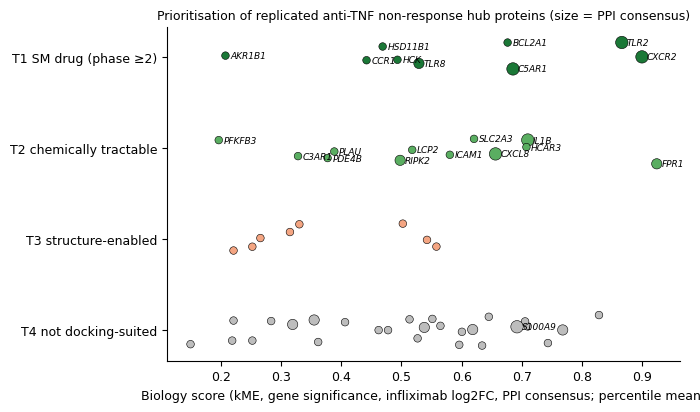

In [14]:
# Cell 4b.6 — Figure: biology score vs tier for primary targets
P = T[prim].copy()
tier_y = {'T1': 3, 'T2': 2, 'T3': 1, 'T4': 0}
colors = {'T1': '#1B7837', 'T2': '#5AAE61', 'T3': '#F4A582', 'T4': '#BDBDBD'}
rng = np.random.default_rng(1)
fig, ax = plt.subplots(figsize=(7, 4.2))
for t, d in P.groupby('tier'):
    y = tier_y[t] + rng.uniform(-0.18, 0.18, len(d))
    ax.scatter(d.biology_score, y, s=30 + 25 * d.PPI_consensus.fillna(0), c=colors[t], edgecolor='k', lw=.4, label=t)
    for (g, r), yy in zip(d.iterrows(), y):
        if t in ('T1', 'T2') or r.PPI_consensus >= 2: ax.text(r.biology_score + 0.008, yy, g, fontsize=6.5, fontstyle='italic', va='center')
ax.set_yticks([0, 1, 2, 3]); ax.set_yticklabels(['T4 not docking-suited', 'T3 structure-enabled', 'T2 chemically tractable', 'T1 SM drug (phase ≥2)'])
ax.set_xlabel('Biology score (kME, gene significance, infliximab log2FC, PPI consensus; percentile mean)')
ax.set_title('Prioritisation of replicated anti-TNF non-response hub proteins (size = PPI consensus)', fontsize=9)
ax.spines[['top', 'right']].set_visible(False); fig.tight_layout()
for ext in ('png', 'pdf'): fig.savefig(os.path.join(FIG_DIR, f'F4_target_prioritisation.{ext}'), dpi=600, bbox_inches='tight')
plt.show()

In [15]:
# Cell 4b.7 — Excel deliverable for the chemoinformatics team + run log + ZIP
xlsx = os.path.join(RES_DIR, 'UC_antiTNF_target_prioritisation.xlsx')
methods = pd.DataFrame({'item': [
    'Query date', 'Primary list', 'Secondary list', 'PPI network', 'Centrality', 'Tier T1', 'Tier T2', 'Tier T3', 'Tier T4',
    'Biology score', 'Caveat'],
    'description': [QUERY_DATE,
    'Black WGCNA module hubs (kME ≥ 0.8) up-regulated in non-responders in BOTH infliximab cohorts (P < 0.05, same direction as golimumab)',
    'Remaining golimumab-derived response-signature genes (annotated only)',
    'STRING (Homo sapiens), combined score ≥ 0.700; sensitivity: experimental + curated-database edges only',
    'Degree, betweenness, closeness, MCC; consensus = number of networks with top-10 mean rank',
    'Small-molecule drug with mechanism at target, ChEMBL max phase ≥ 2',
    '≥ 20 ChEMBL activity records with pChEMBL ≥ 6 and ≥ 1 experimental PDB structure',
    'GPCR/kinase/enzyme/ion channel/transporter with PDB structure or AlphaFold mean pLDDT ≥ 70',
    'Not suited to small-molecule docking (e.g., cytokines, adaptors); discussed biologically',
    'Mean percentile of kME, |gene significance (golimumab NR)|, mean infliximab log2FC, PPI consensus',
    'Associations are correlational; docking/MD outputs are hypotheses requiring experimental validation']})
with pd.ExcelWriter(xlsx, engine='openpyxl') as w:
    T.reset_index().to_excel(w, sheet_name='Ranked_targets', index=False)
    CENT.reset_index().rename(columns={'index': 'gene'}).to_excel(w, sheet_name='PPI_centrality', index=False)
    pd.DataFrame(MECH_ROWS).to_excel(w, sheet_name='ChEMBL_mechanisms', index=False)
    pd.DataFrame(DGI_ROWS).to_excel(w, sheet_name='DGIdb_interactions', index=False)
    methods.to_excel(w, sheet_name='Methods_notes', index=False)
T.to_csv(os.path.join(RES_DIR, 'T4_ranked_targets.csv'))
log = {'date': datetime.datetime.now().isoformat(timespec='seconds'), 'query_date': QUERY_DATE, 'n_primary': len(PRIMARY),
       'n_secondary': len(SECONDARY), 'api_errors': LOG, 'tiers_primary': T[T['list'].str.startswith('primary')].tier.value_counts().to_dict(),
       'networkx': nx.__version__}
json.dump(log, open(os.path.join(P4_DIR, 'run_log_part4b.json'), 'w'), indent=2, default=str)
tmp = '/content/p4_zip'; shutil.rmtree(tmp, ignore_errors=True)
shutil.copytree(RES_DIR, os.path.join(tmp, 'results')); shutil.copytree(FIG_DIR, os.path.join(tmp, 'figures'))
shutil.copy(os.path.join(P4_DIR, 'run_log_part4b.json'), tmp)
zip_base = os.path.join(PROJECT_DIR, 'UC_Part4b_results'); shutil.make_archive(zip_base, 'zip', tmp)
print(json.dumps(log, indent=2, default=str)); files.download(zip_base + '.zip')

{
  "date": "2026-10-05T18:31:43",
  "query_date": "2026-10-05",
  "n_primary": 56,
  "n_secondary": 32,
  "api_errors": [],
  "tiers_primary": {
    "T4": 27,
    "T2": 12,
    "T1": 9,
    "T3": 8
  },
  "networkx": "3.7"
}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:
# ============================================================================
# Cell R.0 — Collect every figure and results table for the Results section
# Walks the project folder, excludes the large caches, writes one zip + a
# manifest, and downloads it. Safe to re-run.
# ============================================================================
import os, re, shutil, hashlib, pandas as pd
from google.colab import files

try:
    PROJECT_DIR
except NameError:
    from google.colab import drive
    drive.mount('/content/drive', force_remount=False)
    PROJECT_DIR = '/content/drive/MyDrive/UC_AntiTNF'

OUT_NAME  = 'UC_AllResults_for_writeup'
STAGE     = '/content/_uc_bundle'

# what to take
KEEP_EXT  = {'.csv', '.tsv', '.json', '.txt', '.xlsx', '.png', '.pdf', '.svg'}
# what to skip: raw GEO cache, expression matrices, annotation caches, old zips
SKIP_DIR  = re.compile(r'(^|/)(raw_geo|expression|\.ipynb_checkpoints|__pycache__)(/|$)')
SKIP_FILE = re.compile(r'^(UC_Part\d\w*_(results|verification)\.zip|GPL\d+.*|GSE\d+_series_matrix.*)$')
MAX_MB    = 60          # skip any single file larger than this (nothing we need is)

if os.path.isdir(STAGE): shutil.rmtree(STAGE)
os.makedirs(STAGE)

rows, skipped = [], []
for root, dirs, fnames in os.walk(PROJECT_DIR):
    rel_root = os.path.relpath(root, PROJECT_DIR)
    if SKIP_DIR.search(rel_root.replace(os.sep, '/')):
        dirs[:] = []
        continue
    dirs[:] = [d for d in dirs if not SKIP_DIR.search(d)]
    for fn in fnames:
        ext = os.path.splitext(fn)[1].lower()
        src = os.path.join(root, fn)
        rel = os.path.normpath(os.path.join(rel_root, fn)) if rel_root != '.' else fn
        if ext not in KEEP_EXT or SKIP_FILE.match(fn):
            skipped.append(rel); continue
        mb = os.path.getsize(src) / 1e6
        if mb > MAX_MB:
            skipped.append(f'{rel}  [{mb:.0f} MB — too large]'); continue
        dst = os.path.join(STAGE, rel)
        os.makedirs(os.path.dirname(dst), exist_ok=True)
        shutil.copy2(src, dst)
        rows.append({'path': rel.replace(os.sep, '/'), 'kind':
                     'figure' if ext in ('.png', '.pdf', '.svg') else 'table/record',
                     'size_KB': round(mb * 1000, 1),
                     'md5': hashlib.md5(open(src, 'rb').read()).hexdigest()[:8]})

man = pd.DataFrame(rows).sort_values('path')
man.to_csv(os.path.join(STAGE, 'MANIFEST.csv'), index=False)

zip_path = shutil.make_archive(os.path.join('/content', OUT_NAME), 'zip', STAGE)
total_mb = os.path.getsize(zip_path) / 1e6

print(f'Collected {len(man)} files  '
      f'({(man.kind == "figure").sum()} figures, {(man.kind != "figure").sum()} tables/records)')
print(f'Archive: {os.path.basename(zip_path)}  —  {total_mb:.1f} MB\n')
print('--- per folder ---')
print(man.assign(folder=man.path.str.rsplit('/', n=1).str[0])
         .groupby('folder').agg(n=('path', 'size'), MB=('size_KB', lambda s: round(s.sum()/1000, 1)))
         .to_string())
if skipped:
    print(f'\n--- skipped {len(skipped)} items (caches / oversized) ---')
    for s in skipped[:15]: print(' ', s)
    if len(skipped) > 15: print(f'  … and {len(skipped)-15} more')

shutil.copy2(zip_path, os.path.join(PROJECT_DIR, os.path.basename(zip_path)))  # keep a copy on Drive
files.download(zip_path)

Mounted at /content/drive
Collected 572 files  (60 figures, 512 tables/records)
Archive: UC_AllResults_for_writeup.zip  —  24.5 MB

--- per folder ---
                                                    n    MB
folder                                                     
00_dataset_verification                             1   0.0
00_dataset_verification/figures                     5   0.3
00_dataset_verification/results                    13   0.1
01_preprocessing_DEG                                1   0.0
01_preprocessing_DEG/figures                       16   5.7
01_preprocessing_DEG/qc                             8   0.5
01_preprocessing_DEG/results                       13  10.7
01b_robustness                                      1   0.0
01b_robustness/figures                              6   0.8
01b_robustness/results                             21  12.5
02_independence_deconvolution_enrichment            1   0.0
02_independence_deconvolution_enrichment/figures   14   3.9
02_indepe

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [2]:
# ============================================================================
# Cell 0.FIX — Restore the Part 0 (dataset verification) records on Drive
#
# WHY: the copy of 00_dataset_verification on Drive was overwritten on
# 2026-10-05 00:14 by a re-run of the Part 0 cells in a fresh runtime, where
# the in-memory DATASETS dict was empty. The loops ran zero times and wrote
# EMPTY tables over the real ones. The authentic outputs of the original run
# (2026-10-04 22:55) are embedded below and are restored by this cell.
#
# Nothing is downloaded and nothing needs uploading. Safe to re-run.
# ============================================================================
import os, io, gzip, base64, tarfile, json, shutil, datetime

try:
    PROJECT_DIR
except NameError:
    from google.colab import drive
    drive.mount('/content/drive', force_remount=False)
    PROJECT_DIR = '/content/drive/MyDrive/UC_AntiTNF'

STEP_DIR = os.path.join(PROJECT_DIR, '00_dataset_verification')
EXPECTED_MD5 = 'df46f9f36ef59ad94002ef8988e2369c'

BLOB = (
"H4sIAAy+xGoC/+1d65LbRnbWbz0FSj8Su4IZ9f2iOKnII69WXtur0qWcVCrFwpCYEdYkyALAkcapfajNg+wzpXEjAeKgDzgzUsUx"
"UWWPyP6+06f7fN19GmjMnD89f/pvr6NPf4yjRZw9+iwXqa+xn4Qwtf93+T0ljPJHwadHX+Da5kWUueof/T4vxoJVkazif6HaUiq4"
"puScPH50un4n102cJVfJPCqSdTrL4s06K87/kq/Thx7/yjP+hSCPqGSKSKYFd3MBFVKJRwH5kuM/W68LHw4r/41e//04CJ4soiJ+"
"8ix4wtxMfEbJGRHvGHsm5TNKnoQNIMrjIp9toiyPFw77n+5rV/Dy7XdGC6UqWP3ZMkFl57OWjIrOZ6qMtt3PjEnaxXOlup8Zl1Y/"
"cR//q3Il/xBl8WL28u2Pzpkky50vpFuwcVKO02KWLMoio6uy+NMmi/O81PjVMrq+rnA1mRFR05NVsoyypLidzbdFafXc2sd//f8+"
"/s9P6/9p/e+s/8qy0/r/O7rctLhdFvnTd2QWpem6qBOB+Xqbutk+Wi7P5/nN513/qaSss/5T4ca/0kqf1v8vcTUre3iVxMtFeBMt"
"t3GYPm6X9TBfb7N5PEujVTybf6BhkeT5Ng4uk/Umvw0pMXvo3K2/s3x7+Zd4XoTfuKJgkeRFks6LfwWArix2FcefCrdYhz+4xbeI"
"F6EiXth35Y88uYlDpr3As7OQURgRvl/O48zJ/CYOLtbLxLUo+Or9xdehGTEZ/rTOVtFyaDC6jsNvBPc2s+6v0FW0TtviKkHCetbw"
"PbRraV5aClbb+TqPANSu/22v+wc4rDOoYiMMlygsiw+3TXd0HcziqFiVvX/tLK22q+jStdiOol4vo3l8uQ4lH4WM1lV3vfA28SbJ"
"kyL8OY5/cQliHVy4VIVagqWj1X/8Rbl5c7NOXX/8R5yHhnkAP61DQzzlo7Wsott1kM/XWRzqkHtKTcjUeKkNGRsvPffWq0Jqx0sp"
"cd0+XsxDH5eGeryU+QpF6Gmt9BXSUHoKWcjHS0ldWG1mBmP322rQBlfZehUkqdthrOJFUI3UZN6M1WB9FUTzaqC9vwiaTUqoxZFG"
"k6VTy9DkxYudSUmnmdymHk+TdOgr40cbPvR2Z7bjL1XTzKbVLAz4Ol+nRbZeOuOL5CZZbN1UTelRNg/dvIdFPPqdppu9zcEU72pU"
"cLHzdrsK9SG5nZ+3+xl9Xs/oodUj2IsXoRorazqhmTwgcrb+kP5jHrSfRxyq2+221WHdASHlHEO2Ogm5xaBpszhXXla3FgbxueiF"
"YtkssXW8nL7TdXpWT8ZuAxxEV4X7/1WS5UUVzORT4hayYL8m1WF5gJou4ys3sXyOqi5ezIOj6mEPUQ/ec3S8mledIXhYSXJ0iMjD"
"VDSh5+5c0zG1mDsr7ohOe4hK7tWUqf31uVpSqvlIoemHqgnvuDtWBSxl6i4h8NsZbnUshUtfVYuXYAelnQVJ85Gy9xehMGO8ZrGi"
"h4bbLDso1p1+LXNypaZBy/xeyqlmiyDabJbJPLpcxkNvmjCvJ0jrW1QRit7d+nMMoMjdjcO9UN7lHwiuzZJqqf1z8POfzJu3r//4"
"47Og7Pa7MV1sm5WmIjb7LZPlmw+r8NBsv3RHrZ5BDOr8hmrV3XI2OViFrXffxXZx2xkjQbpdXcZZ+I02Xt7Hchv61cevw59Jm5BB"
"hSrkZLRQzFx5k6ND5ZI1ezmw1G1+6Cj34s9Nn4FUE4rRMua2pqOFNqTj/ghPITe+QuYz62NS5SsknkI2ZDoRbOflvdSg+ODy8c2t"
"20wmaRGnUTqP2+/Cm8WvM/ef+BhKcycDr/7w76FQd63b1cvFnciQJI5qsvnYG2pHGtgso3mTfB3NL7m1gcORVm3343Sxdlv+jZtb"
"8u3l7k4Gm4plzeo2BUvb3e8ELDkCC0Wnu7kcJAvtnFQ9a0XmWhc3vsfWy7AzdR3PyudI1dLoQrO6fvrL9eyj81pjYLnHSgy7qW8a"
"VmA+1bCZVdM+new1JzWDTGbUVdjJ7rsayhxkagsah9Rk+2aS+Y77Di6P8b50RxzToa4CfoT7pX1+RPdMMS+7rWVDdNw6HAoBldb8"
"kGuosPE95IeGy/rLhV1IsMCEXIEFnAxt7W7vi15CMRgKLqMJeneotfQhys4zAwAnfRvSeiGlgsTpyfHp/Mfp/Mfp/Mfp+u2d/2iO"
"ArhFZrWKstuHOPkx6fwnKw979s9/SEVO5z+/6PmPIimWVRJTXK2zVZjO8mi1WbpVP0ldmlFsizh0yccqKcpjGhv3L/ej2lst4sUs"
"Wy/j/cGHl3EaB/sTl8EmW18lyyS9Lp+C9fYdSZzXtxejhRNh+1wsDz4mxYdgtV6UD7Li5W15ly2Pb+Ks/HfzGA14zPXy9Q+UU2nK"
"cxbh91Ga53EavPmHF+HbeBMwGzDidvjMCre8GB669Gm+djZvn5X3sG/y9hbn/hHwhctxXG1xlvxanYqq3HctnW+XURZ0bwG+bA88"
"BEkaAEcqLm8Pb6qu3vz0HOyjZ0EzIuuOef3+zdv3r96dvb0I9rvb6jZTp7muNd3mvojnARVNc7nm0kWlPNmTLOpm/FOwO6Cxa8X+"
"MduPjaPXo1F0bexHqn7ouYqKdXYbXK4/xsv2oeDeVcWECKkV4Z/e/xBvb+LU5Ys3Aa2iIkNmjJGMmY6bQFjq25Gtg/f2rbmlGaUL"
"/J6ma4HU5Z6T7xvw/TatZUWsa5mVSjMedtjdvq3vNj4PXmfxIqkV/KYV0NvkOo2KbVZJ6dWe/66tHVZV6xPrR//77TJgsvTKKcNq"
"QgSXY17VtwfefXCBvrpy+4pS4Tfxwtn/tVLHV1FaJGd//5v4+//os3K0X2dJ+nV7JyVwPX94O+FQNYN4DMdtfeBoJxFt9j38Z+cS"
"oY1EtHFZoey15WnP227L6l3Kd3tHynmufZTRvZsRNPNcfTyhH/l40Tn/sOtvt9vqdfjz7XVAWemkiwUVwlBhA04Jt1RqsOdP+f8p"
"//+/mv+f3v/63eb/ZTa0jDazsZdl7rwh8Of/THKh+u9/McrI6fz3F7l2GX+7+3selq9WPd99/rb6/G2Yb+IoW0XpLHu8yzz3Kf/b"
"HxnnjNjquzp9Lr8TLt12SzZ1U4qHZAGS8pMoIQBJYyQKkAxGYgDJYiQ+JCmCkQRAohhJAiSGkRRA4hhJAySBkQBFKImRAEUoTBEU"
"UITCFEEBRShMERRQhMIUQQFFaEwRFFCExhRBAUVoTBEUUITGFEEBRWhMERRQhMYUQYeKkATrPQYoQmMyYoAiNCYjNlSEW9QwEgdI"
"aE2QIjDBMgnUhJIUQMJUzoaK4BKNkwFImMrZUBHcYjVxAtSEDQ1OARI2NDgwR2is9zigCImNJy4AEjaeOKAIdM3lgCLQNZdDisC0"
"xyFFoL0HKAJdcwWgCItpTwCKsJiMBDBHoKu7ABRhMe0JYI4waEcAq4ZB3VPAtIySgFXDoL0HKAJNcwQ0R2DjSUKKwMaTBFYNg8VJ"
"QopASZAisJErIUWgHQEpAu0IYI6w2BwhgTkCzSwlpAjUPSCzNFjvKQKoHNOeAuYINIdVkCKw3lOQIrAZVgGrBpr4KkgRqHuQIrC5"
"XEFzBOoepAi0JmCOQPNyDcwRaF6uAUWgebkGFIHm5RrYa6DZsobmCKz3NJBHoDsADa0aaJuAOQLdNmhAEegOQANzBJpZGmCvgeYR"
"BlIENp4MkFmiyYcB5gh022AARaCru4EUgcnIALtPdIY1gCLQNMcAikDTHAMpAhOsBeYINM2xQB6BZiwWUgQ2NCwwR6B5hAVWDTTN"
"scCqgaYEFlg10IzFAqsGuhJC9yzR9Qm6Z4lNYYxAipAYCZgjsIyFAfcsObZQM+ieJREYCVKEwUjAHLFfaqrnwLvzCK7cbZ0UqWfl"
"+ol1+Z0tf3MMCcvf0mXlOK2elw9otKaVr4CN8ijAYzVPeGgMoPGG5uNxgGeb1lEPTwx4jDbNK9+WG+XJIY81zSvP+Y7yFMDjE3ga"
"4ImGxzw8A/AkHnUL0FQTdT7Os8NuKXeeFU97wmcVEL6medrTLVYDPDmBBwwG3fDGo948NDmgKbR5zSOQPs80KtPSwwNUbfBuaR6E"
"HPAmNA+Inm17U3t4gKhJMxi0rz5A1ERN6BZA1KRVmfLwAFXTpjvN+CTRPBk54OEqax6OHPA0GgYGzS0TaEAUeDu1eHqTAVHgzdSp"
"PKJmQBREK2rm4QFREE0UlEdlHIiCwOek5vbzAa9Ri/L0Jx8OWrZb+Tw0DtAmiIwDK5HU+GDggFoUwQctB+Si+IRuAeSimsGgPIOB"
"A3LRFB+0HJCLFmgC0tyYPuC1/emJgwDkYgguMwHIpZ1zfbIWgF6MQWUmALnYVp0euQhALlbgMhOAXKzGwy4AuViLDwcxlAsnEp9d"
"hAV4Gq9PDuXC6YRhJCnAa4aR8fgpGcAT+HCQHOBJfK2VAuA1s6fx1ScBnsZ1JhXAM/jwkxrg2Qk8QC+siR/3xQ/QC5swjhSgl3YD"
"oD3ThAL00m4AlKd9CtBLuwHwjQcF6KXdABhPvyggI2+XFd90poCMfDfterIJBWTkpulP5WmfBlJyS/A4aGB/ajme9Whgmt/NSz4e"
"MM3TKe2DNqi9LYesu6A+Ie8gbroz9TazPsTtvpLaaLq7UQIS9JBgvAQzIDDmJdgBgVMfob7/1ycIL4EOCdZLYAOCIF4CHxL8bRBD"
"AvcS5JDgDZwdRlp4A2eHkZb+NgwjvT+0ABKGkVY+lywZRnr/kAEkDCOtrZcwjLRhXsIw0sbfhmGkLfEShpG2fpeGkbbaSxhE2ngn"
"AUsGkTaslsbpnPfp/Y/T+x+n9z9O13Hvf5TvfXxM8njmBklx5xdAkPe/3d6VHb7/IYQ8vf/xRd//mK9XmyhL8nUarqJPsyzcWHtu"
"3c/dW0DDB3rBV+U7nUn6dZnPMyKELs8VE5e26morQrTWhItyh6/LQ9T9Z4LV87+eCUW0KlMRxVT1aMt9RamknGlevv6pyhsvgBc3"
"ebB7nOhW+/4lhl+x+jfxH2xZep5It8FSzg2thFCy2q/wctPAhCtRUpdb0J6FcoPTb4smRhJBiXWzqqi6w3GZlUa5DbNTOwuHTzub"
"ptTbpWaPS4XSrpCb9max26hYl0JaN0ackXqT2KZD5RvSXTd0eSyWaCFccAyvnigq63rX9Ss3TLtQNVHp5lNdA4a4zFET9z1Tboci"
"hl/xnoEq++oZUNxQISWR5dNkWfGZKH/Rg2GWlSeVyaABdS/UuZ1zmJees0pMri/KTae0UvMylFpKt/00ozbqZNDZkMKUx4zKrJZX"
"t7OltcLpiCinJSsFB7qhawIS0Xn58vVvfK085X+n/O/0+39O+V8n/xv+Ib17/iog5O8/aS4P//6T1oqd8r8vcfX//tM+5iN/V0hR"
"Qs/KqJlJAOAvQ02woPVZtS0YtYADbFWFHq9iIsBiVdhJFiCAS2gqABurogdALUAAQVgFUJMAkA+TARqr4v4AMwngc9JjQVSK0uMW"
"OoD7WBj8taXPAOCYD3ySBR9ATAL4fEABCqvi/gCD+YACLFbFNICnCk4QCw8AoJMAPidHLch6tqejzewB7mihGt2MjVvoAHwWDGbh"
"7gBNZNUKNQkAOTnZgp4E8FWBAtBm3gNAVQUgkwCgk4gFXf6Va1+w+gCgigkWTDUuCJ0EAKvAAdK7+vcBkIU2RRm1cH8Aa5ZFOgkA"
"OTnZAp8E8FXhAWjvyjsBQLk3yekDQB+mWjCYBXNfC+Mj6/4ALoU38e4DUAsgQFeDl4jRKroA1AIM0EgrugDUAgQQjeRGW9EDoBZ8"
"AIlVISdZ8AHUJIDPh3ELVOxXHNBCF3AvCxazcG8AI4gPjIxbUH5N4gBO/IvaAwAU8S8oPQDo5FQLfBLAVwUKEFgV0wC+KiRm4f4A"
"NQngc3IU0KTN47GYAFB+RfUAsA+YBWaOAIBVoACOiPbhAGISwOckakFPAviqQAEGq2IawFeFxSzcG0AxPYwnvRMADBFtFwD7MNEC"
"wyywSRYggGruFY862QP4LDDMAuqDwCwIzILELHgADGvmQwHEJIDPyVELmiN7vR7gbhaE8g+9qYDxHUoP4PHBY0Fyfyx6ALCKqRYE"
"ZsEDkP6VtwfwWRCYhfsAFKKHLgC1AAIMMj/0AKAPUwEcq2K8qw2mhwcDsEkAn5OoBbSZfJIFH0BiVchxCxIZm1MBDKuCYRY4ZsED"
"0FgVGMAiCedDABSihy7Ab+F00uN0na7TdbpO1+k6Xaervv4XkM5KlACgAAA="
)

# ---- 1. show what is there now -------------------------------------------
TARGETS = ['verification_report.json',
           'results/T0_annotation_counts_all.csv',
           'results/T0_dataset_summary.csv',
           'results/T0_overlap_expression_flagged_pairs.csv',
           'results/T0_overlap_expression_pairwise_stats.csv',
           'results/T0_overlap_shared_patient_ids.csv']
print('BEFORE — current size of each file on Drive:')
for t in TARGETS:
    p = os.path.join(STEP_DIR, t)
    print(f'  {os.path.getsize(p):>7} B  {t}' if os.path.exists(p) else f'  MISSING    {t}')

# ---- 2. back up whatever is there, then restore ---------------------------
import hashlib
raw = gzip.decompress(base64.b64decode(BLOB))
assert hashlib.md5(raw).hexdigest() == EXPECTED_MD5, 'embedded payload is corrupt - do not proceed'

stamp  = datetime.datetime.now().strftime('%Y%m%d_%H%M%S')
BAKDIR = os.path.join(STEP_DIR, f'_damaged_backup_{stamp}')
os.makedirs(os.path.join(BAKDIR, 'results'), exist_ok=True)
for t in TARGETS:
    p = os.path.join(STEP_DIR, t)
    if os.path.exists(p): shutil.copy2(p, os.path.join(BAKDIR, t))

os.makedirs(os.path.join(STEP_DIR, 'results'), exist_ok=True)
with tarfile.open(fileobj=io.BytesIO(raw)) as tf:
    try:    tf.extractall(STEP_DIR, filter='data')
    except TypeError: tf.extractall(STEP_DIR)          # Python < 3.12

# ---- 3. verify -------------------------------------------------------------
print('\nAFTER — restored:')
for t in TARGETS:
    print(f'  {os.path.getsize(os.path.join(STEP_DIR, t)):>7} B  {t}')

d = json.load(open(os.path.join(STEP_DIR, 'verification_report.json')))
print('\nverification_report.json:', json.dumps(d))
assert len(d['datasets_parsed']) == 7,        'datasets_parsed is not 7'
assert d['expression_flagged_pairs'] == 204,  'expression_flagged_pairs is not 204'
assert d['shared_patient_ids'] == 87,         'shared_patient_ids is not 87'

import pandas as pd
s = pd.read_csv(os.path.join(STEP_DIR, 'results/T0_overlap_expression_pairwise_stats.csv'))
f = pd.read_csv(os.path.join(STEP_DIR, 'results/T0_overlap_expression_flagged_pairs.csv'))
print('\nPairwise similarity statistics:')
print(s.to_string(index=False))
print('\nFlagged cross-series pairs by series:')
print(f.groupby(['dataset_A', 'dataset_B'])
       .agg(n_pairs=('spearman_r', 'size'), min_r=('spearman_r', 'min')).to_string())

print(f'\nRESTORED. The damaged files were kept in {os.path.basename(BAKDIR)}/ '
      'and can be deleted once you are satisfied.')
print('NOTE: do not re-run the Part 0 cells unless you first run Cell 0.2, which is '
      'what populates DATASETS. On an empty DATASETS they write empty output silently.')

BEFORE — current size of each file on Drive:
      171 B  verification_report.json
        1 B  results/T0_annotation_counts_all.csv
        1 B  results/T0_dataset_summary.csv
       52 B  results/T0_overlap_expression_flagged_pairs.csv
        1 B  results/T0_overlap_expression_pairwise_stats.csv
       25 B  results/T0_overlap_shared_patient_ids.csv

AFTER — restored:
      288 B  verification_report.json
     6736 B  results/T0_annotation_counts_all.csv
     1396 B  results/T0_dataset_summary.csv
    10982 B  results/T0_overlap_expression_flagged_pairs.csv
      834 B  results/T0_overlap_expression_pairwise_stats.csv
     7912 B  results/T0_overlap_shared_patient_ids.csv

verification_report.json: {"date": "2026-10-04T22:55:10", "datasets_parsed": ["GSE87466", "GSE92415", "GSE75214", "GSE16879", "GSE12251", "GSE73661", "GSE23597"], "shared_GSM_pairs": 0, "shared_patient_ids": 87, "expression_flagged_pairs": 204, "similarity_cut": 0.99}

Pairwise similarity statistics:
platform     

   1259 KB   /content/drive/MyDrive/UC_AntiTNF/05_figures/Figure1_study_design.png
     52 KB   /content/drive/MyDrive/UC_AntiTNF/05_figures/Figure1_study_design.pdf


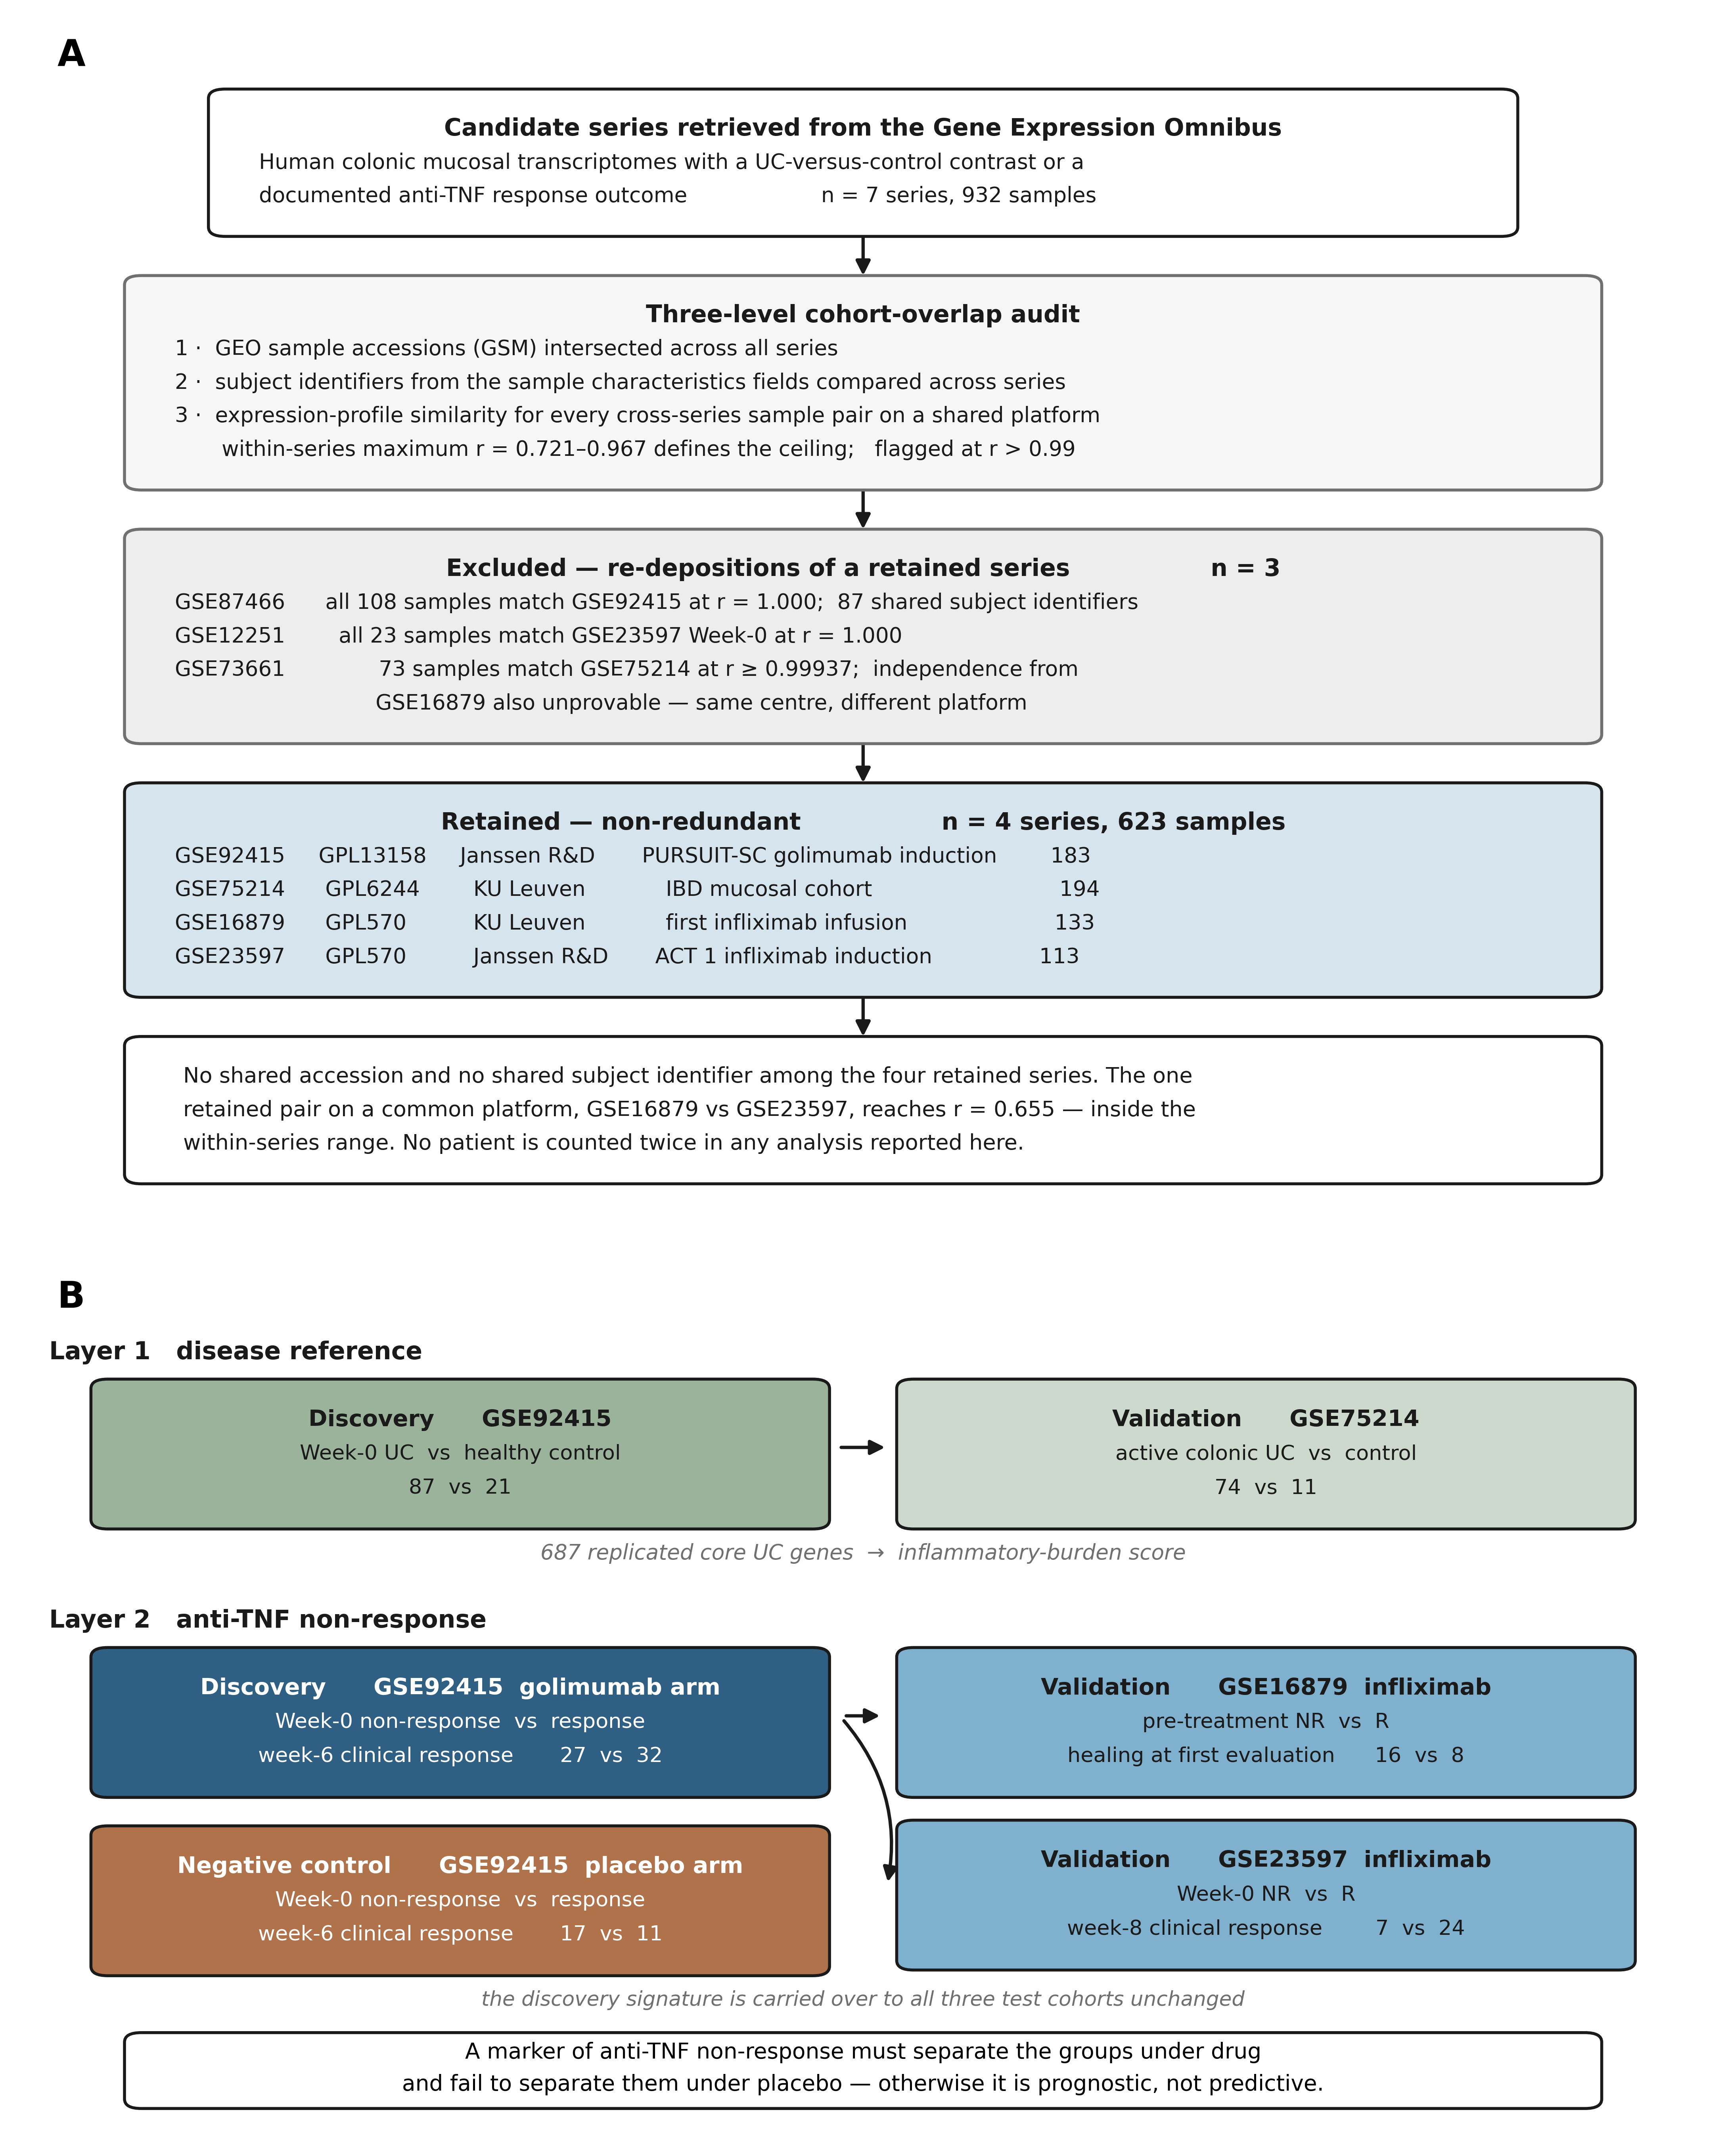

In [3]:
# ============================================================================
# Cell F1 — Figure 1: study design and cohort-overlap audit
#
# Panel A  CONSORT-style audit flow: 7 candidate series -> 3 excluded -> 4 retained
# Panel B  the six contrasts, and why the placebo arm is there
#
# Every number below is fixed text taken from the verified Part 0 and Part 1
# records; this cell draws, it does not recompute. Writes PNG (600 dpi) and PDF
# (vector, for the journal) into <project>/05_figures/.
# ============================================================================
import os
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

try:
    PROJECT_DIR
except NameError:
    from google.colab import drive
    drive.mount('/content/drive', force_remount=False)
    PROJECT_DIR = '/content/drive/MyDrive/UC_AntiTNF'

OUT = os.path.join(PROJECT_DIR, '05_figures')
os.makedirs(OUT, exist_ok=True)
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 7})
INK, MUTED = '#1a1a1a', '#707070'
KEEP, DROP, STEP = '#d6e4ee', '#ededed', '#f7f7f7'
GOL, IFX, PBO, CTL = '#2f5f82', '#7fb0cd', '#b0724a', '#9bb39b'

fig = plt.figure(figsize=(7.2, 9.0))
axA = fig.add_axes([0.01, 0.435, 0.98, 0.555])
axB = fig.add_axes([0.01, 0.005, 0.98, 0.405])

def box(ax, top, w, head, lines, fc='white', ec=INK, lw=.9, lh=3.6, pad=2.5, cx=50,
        hfs=7.2, lfs=6.4, indent=3.0, ljust=True):
    n = (1 if head else 0) + len(lines)
    h = n * lh + 2 * pad
    ax.add_patch(FancyBboxPatch((cx - w/2, top - h), w, h,
                 boxstyle='round,pad=0,rounding_size=1.0', fc=fc, ec=ec, lw=lw, zorder=2))
    y = top - pad - lh/2
    if head:
        ax.text(cx, y, head, ha='center', va='center', fontsize=hfs,
                fontweight='bold', color=INK, zorder=3); y -= lh
    for ln in lines:
        if ljust:
            ax.text(cx - w/2 + indent, y, ln, ha='left', va='center', fontsize=lfs, color=INK, zorder=3)
        else:
            ax.text(cx, y, ln, ha='center', va='center', fontsize=lfs, color=INK, zorder=3)
        y -= lh
    return top - h

def arr(ax, y1, y2, x=50, color=INK, lw=1.0, ls='-'):
    ax.add_patch(FancyArrowPatch((x, y1), (x, y2), arrowstyle='-|>', lw=lw, color=color,
                 linestyle=ls, mutation_scale=9, shrinkA=0, shrinkB=0, zorder=1))

# ----------------------------- PANEL A -----------------------------
y = 0
y = box(axA, y, 78, 'Candidate series retrieved from the Gene Expression Omnibus',
        ['Human colonic mucosal transcriptomes with a UC-versus-control contrast or a',
         'documented anti-TNF response outcome                    n = 7 series, 932 samples'])
arr(axA, y, y - 4.2); y -= 4.2
y = box(axA, y, 88, 'Three-level cohort-overlap audit',
        ['1 ·  GEO sample accessions (GSM) intersected across all series',
         '2 ·  subject identifiers from the sample characteristics fields compared across series',
         '3 ·  expression-profile similarity for every cross-series sample pair on a shared platform',
         '       within-series maximum r = 0.721–0.967 defines the ceiling;   flagged at r > 0.99'],
        fc=STEP, ec=MUTED)
arr(axA, y, y - 4.2); y -= 4.2
y = box(axA, y, 88, 'Excluded — re-depositions of a retained series                 n = 3',
        ['GSE87466      all 108 samples match GSE92415 at r = 1.000;  87 shared subject identifiers',
         'GSE12251        all 23 samples match GSE23597 Week-0 at r = 1.000',
         'GSE73661              73 samples match GSE75214 at r ≥ 0.99937;  independence from',
         '                              GSE16879 also unprovable — same centre, different platform'],
        fc=DROP, ec=MUTED)
arr(axA, y, y - 4.2); y -= 4.2
y = box(axA, y, 88, 'Retained — non-redundant                 n = 4 series, 623 samples',
        ['GSE92415     GPL13158     Janssen R&D       PURSUIT-SC golimumab induction        183',
         'GSE75214      GPL6244        KU Leuven            IBD mucosal cohort                            194',
         'GSE16879      GPL570          KU Leuven            first infliximab infusion                      133',
         'GSE23597      GPL570          Janssen R&D       ACT 1 infliximab induction                113'],
        fc=KEEP, ec=INK)
arr(axA, y, y - 4.2); y -= 4.2
y = box(axA, y, 88, None,
        ['No shared accession and no shared subject identifier among the four retained series. The one',
         'retained pair on a common platform, GSE16879 vs GSE23597, reaches r = 0.655 — inside the',
         'within-series range. No patient is counted twice in any analysis reported here.'],
        fc='white', ec=INK, lfs=6.5, indent=3.5)
axA.set_xlim(0, 100); axA.set_ylim(y - 3, 7); axA.axis('off')
axA.text(2, 5.5, 'A', fontsize=11, fontweight='bold', va='top', ha='left')

# ----------------------------- PANEL B -----------------------------
def cbox(ax, cx, top, w, title, lines, fc, ec=INK, lh=3.6, pad=2.5, tfs=6.9, lfs=6.3):
    n = 1 + len(lines); h = n * lh + 2 * pad
    ax.add_patch(FancyBboxPatch((cx - w/2, top - h), w, h,
                 boxstyle='round,pad=0,rounding_size=1.0', fc=fc, ec=ec, lw=.9, zorder=2))
    yy = top - pad - lh/2
    ax.text(cx, yy, title, ha='center', va='center', fontsize=tfs, fontweight='bold', color=INK, zorder=3); yy -= lh
    for ln in lines:
        ax.text(cx, yy, ln, ha='center', va='center', fontsize=lfs, color=INK, zorder=3); yy -= lh
    return top - h

TOP = 0
axB.text(2, 5.5, 'B', fontsize=11, fontweight='bold', va='top', ha='left')

# --- Layer 1 row
axB.text(1.5, TOP - 2.2, 'Layer 1   disease reference', fontsize=7.4, fontweight='bold',
         color=INK, ha='left', va='center')
y1 = TOP - 5.0
b1 = cbox(axB, 26, y1, 44, 'Discovery      GSE92415',
          ['Week-0 UC  vs  healthy control', '87  vs  21'], fc=CTL)
cbox(axB, 74, y1, 44, 'Validation      GSE75214',
     ['active colonic UC  vs  control', '74  vs  11'], fc='#ccd9cc')
axB.add_patch(FancyArrowPatch((48.3, y1 - 7.2), (51.7, y1 - 7.2), arrowstyle='-|>',
              lw=1.0, color=INK, mutation_scale=9, zorder=4))
axB.text(50, b1 - 2.6, '687 replicated core UC genes  →  inflammatory-burden score',
         fontsize=6.4, ha='center', va='center', style='italic', color=MUTED)

# --- Layer 2 block
y2 = b1 - 7.5
axB.text(1.5, y2 - 2.2, 'Layer 2   anti-TNF non-response', fontsize=7.4, fontweight='bold',
         color=INK, ha='left', va='center')
y2 -= 5.0
bd = cbox(axB, 26, y2, 44, 'Discovery      GSE92415  golimumab arm',
          ['Week-0 non-response  vs  response', 'week-6 clinical response       27  vs  32'], fc=GOL)
for t in axB.texts[-3:]: t.set_color('white')

bv1 = cbox(axB, 74, y2, 44, 'Validation      GSE16879  infliximab',
           ['pre-treatment NR  vs  R', 'healing at first evaluation      16  vs  8'], fc=IFX)
bv2 = cbox(axB, 74, bv1 - 2.4, 44, 'Validation      GSE23597  infliximab',
           ['Week-0 NR  vs  R', 'week-8 clinical response        7  vs  24'], fc=IFX)
# discovery -> each validation cohort; the signature is carried over unchanged
for ytip in (y2 - 7.2, bv1 - 2.4 - 7.2):
    axB.add_patch(FancyArrowPatch((48.6, y2 - 7.2), (51.4, ytip), arrowstyle='-|>',
                  lw=1.0, color=INK, mutation_scale=9,
                  connectionstyle='arc3,rad=0' if abs(ytip - (y2 - 7.2)) < .1 else 'arc3,rad=-0.25',
                  zorder=4))

bn = cbox(axB, 26, bd - 3.0, 44, 'Negative control      GSE92415  placebo arm',
          ['Week-0 non-response  vs  response', 'week-6 clinical response       17  vs  11'], fc=PBO)
for t in axB.texts[-3:]: t.set_color('white')


ybot = min(bv2, bn)
axB.text(50, ybot - 2.6, 'the discovery signature is carried over to all three test cohorts unchanged',
         fontsize=6.2, ha='center', va='center', style='italic', color=MUTED)
axB.add_patch(FancyBboxPatch((6, ybot - 14.0), 88, 8.0,
              boxstyle='round,pad=0,rounding_size=1.0', fc='white', ec=INK, lw=.9, zorder=2))
axB.text(50, ybot - 8.1, 'A marker of anti-TNF non-response must separate the groups under drug',
         fontsize=6.6, ha='center', va='center', zorder=3)
axB.text(50, ybot - 11.5, 'and fail to separate them under placebo — otherwise it is prognostic, not predictive.',
         fontsize=6.6, ha='center', va='center', zorder=3)
axB.set_xlim(0, 100); axB.set_ylim(ybot - 16.5, 7); axB.axis('off')

for ext, kw in (('png', dict(dpi=600)), ('pdf', {})):
    fig.savefig(f'{OUT}/Figure1_study_design.{ext}', bbox_inches='tight', **kw)
plt.close(fig)
for ext in ('png', 'pdf'):
    p = os.path.join(OUT, f'Figure1_study_design.{ext}')
    print(f'  {os.path.getsize(p)//1024:>5} KB   {p}')

# show it inline so you can check it without leaving the notebook
from IPython.display import Image as _Img, display as _disp
_disp(_Img(filename=os.path.join(OUT, 'Figure1_study_design.png'), width=760))

In [4]:
from google.colab import files
import os

# Path to the generated figure
fig_png = os.path.join(PROJECT_DIR, '05_figures', 'Figure1_study_design.png')
fig_pdf = os.path.join(PROJECT_DIR, '05_figures', 'Figure1_study_design.pdf')

if os.path.exists(fig_png):
    print('Downloading high-resolution PNG (600 DPI)...')
    files.download(fig_png)
else:
    print('Figure PNG not found in the project folder.')

if os.path.exists(fig_pdf):
    print('Downloading publication-ready vector PDF...')
    files.download(fig_pdf)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [6]:
from google.colab import files
import os

fig_png = os.path.join(PROJECT_DIR, '05_figures', 'Figure1_study_design.png')
fig_pdf = os.path.join(PROJECT_DIR, '05_figures', 'Figure1_study_design.pdf')

if os.path.exists(fig_png):
    print('PNG indiriliyor (600 DPI)...')
    files.download(fig_png)
else:
    print('PNG dosyası bulunamadı.')

if os.path.exists(fig_pdf):
    print('Vektörel PDF indiriliyor (Yayın kalitesi)...')
    files.download(fig_pdf)
else:
    print('PDF dosyası bulunamadı.')

PNG indiriliyor (600 DPI)...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Vektörel PDF indiriliyor (Yayın kalitesi)...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

   1315 KB   /content/drive/MyDrive/UC_AntiTNF/05_figures/Figure1_study_design.png
     52 KB   /content/drive/MyDrive/UC_AntiTNF/05_figures/Figure1_study_design.pdf


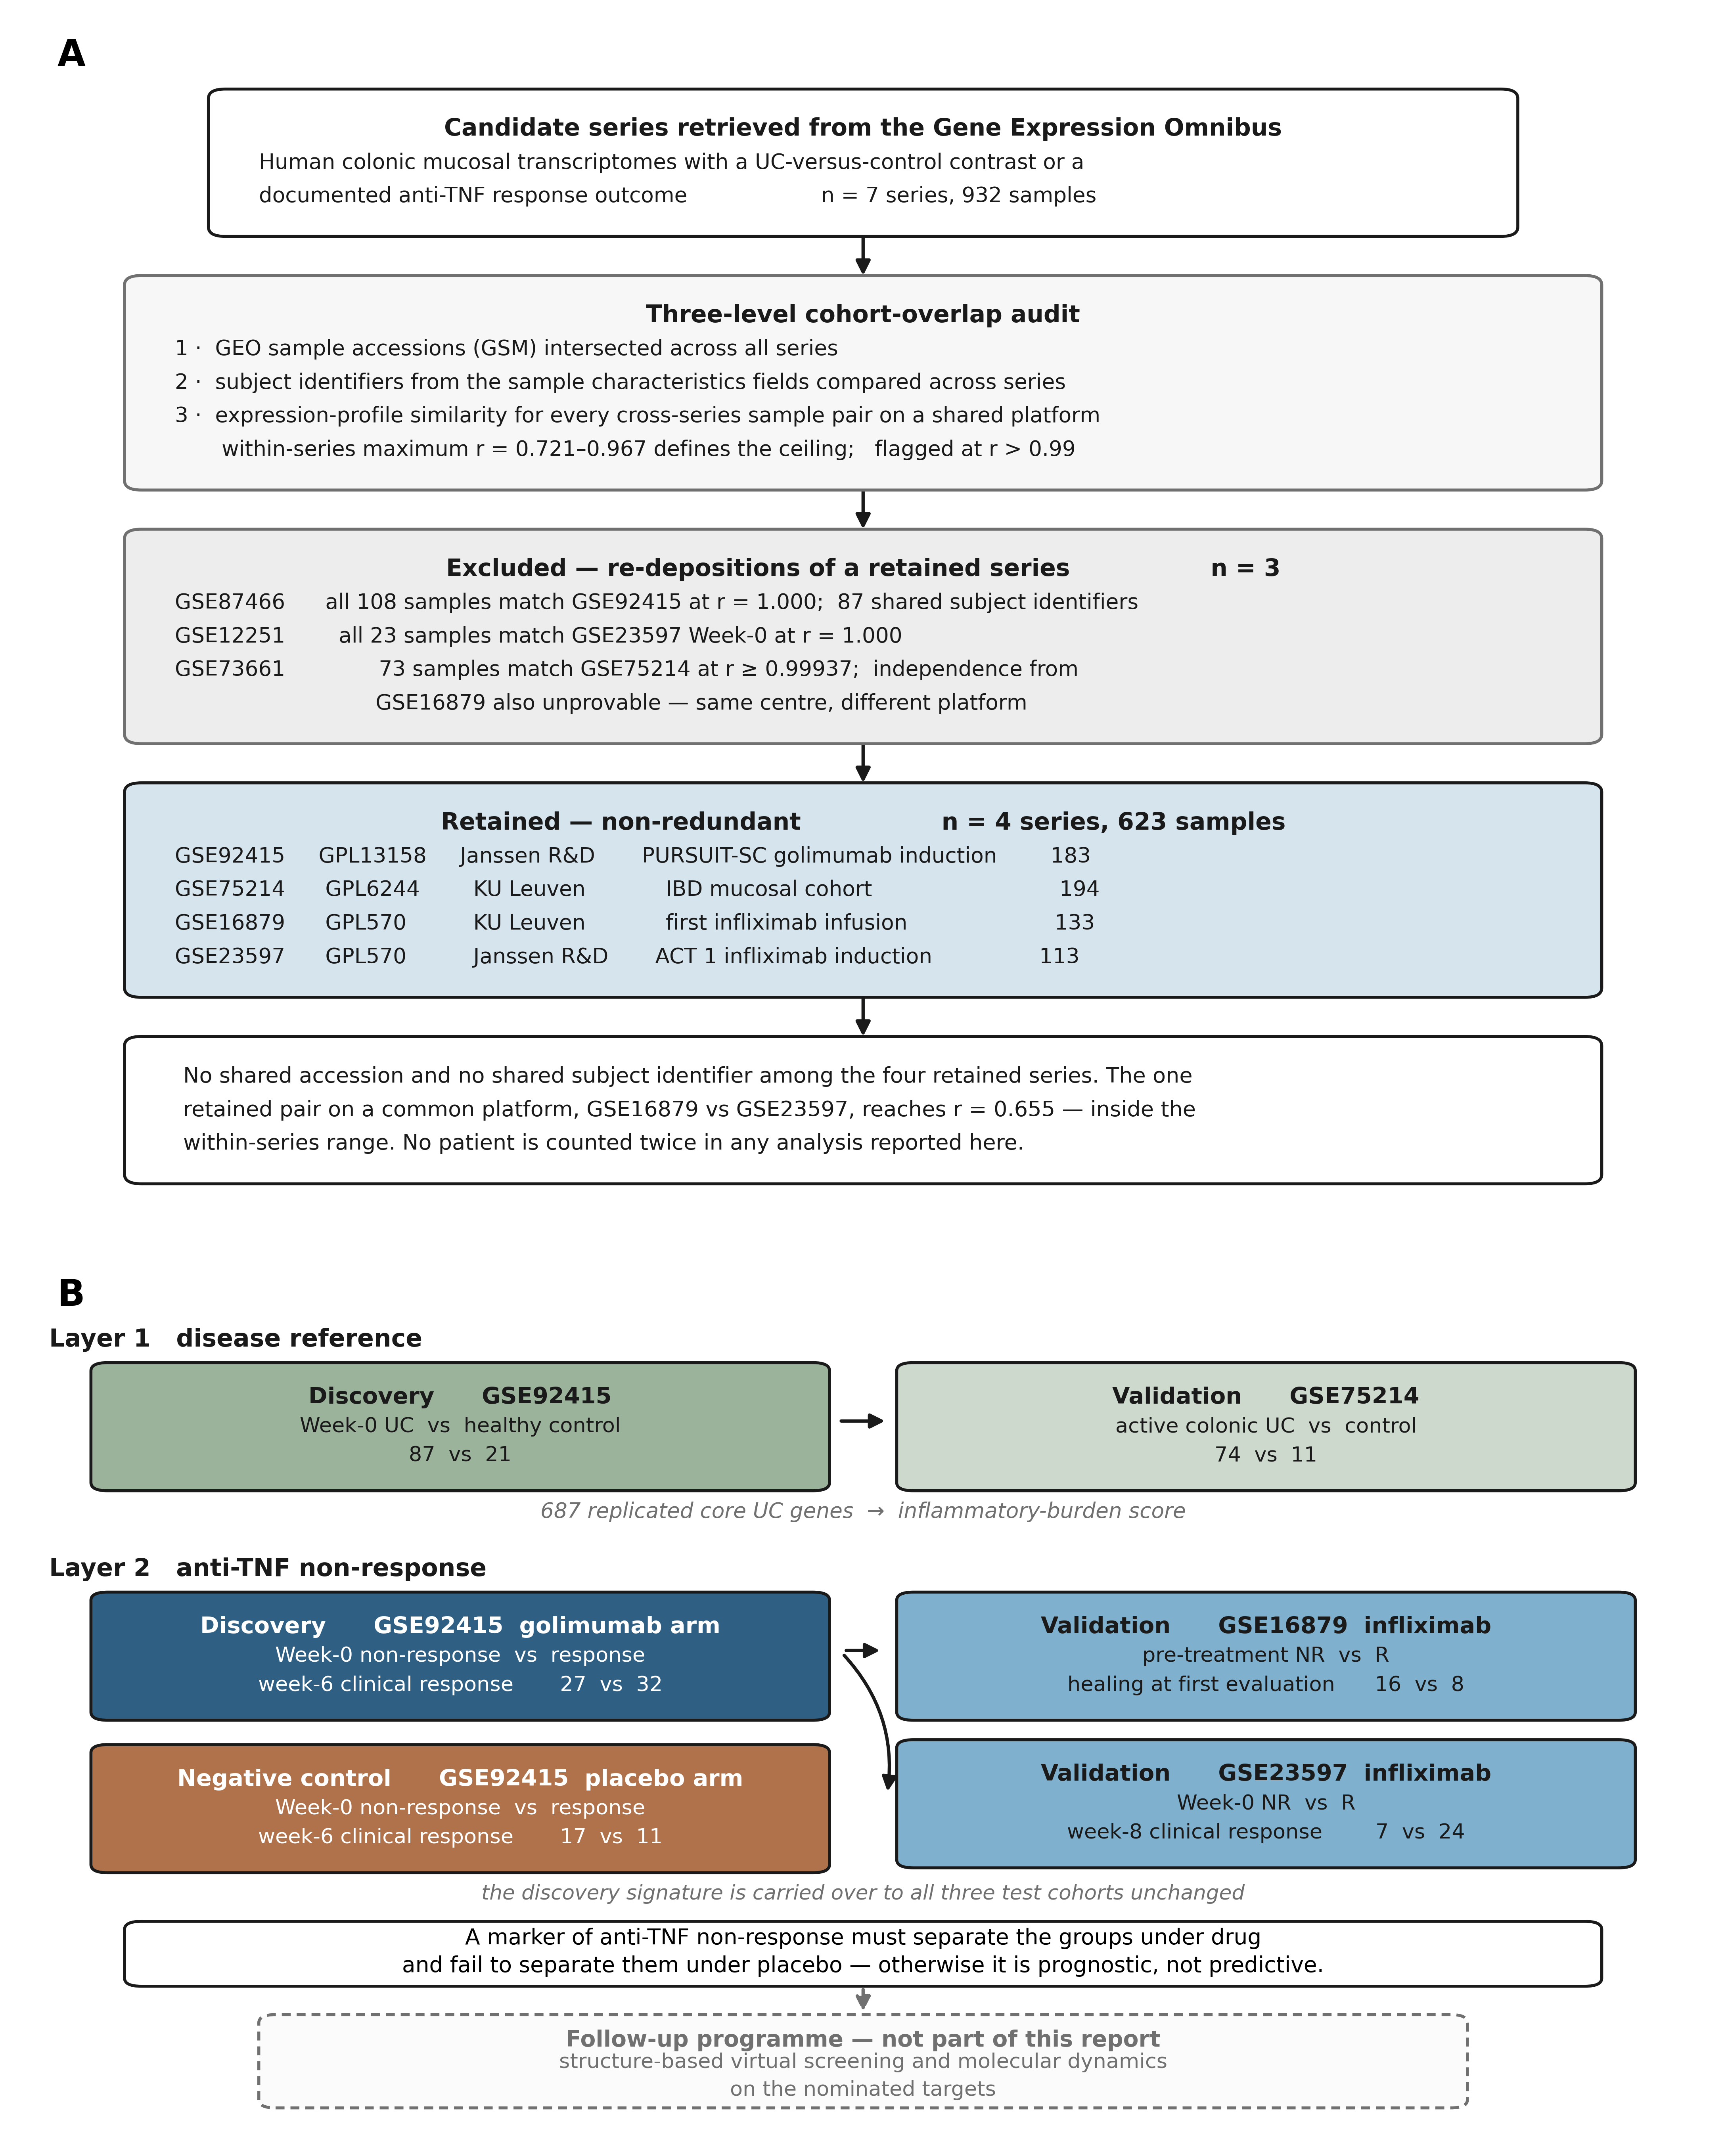

In [5]:
# ============================================================================
# Cell F1 — Figure 1: study design and cohort-overlap audit
#
# Panel A  CONSORT-style audit flow: 7 candidate series -> 3 excluded -> 4 retained
# Panel B  the six contrasts, and why the placebo arm is there
#
# Every number below is fixed text taken from the verified Part 0 and Part 1
# records; this cell draws, it does not recompute. Writes PNG (600 dpi) and PDF
# (vector, for the journal) into <project>/05_figures/.
# ============================================================================
import os
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

try:
    PROJECT_DIR
except NameError:
    from google.colab import drive
    drive.mount('/content/drive', force_remount=False)
    PROJECT_DIR = '/content/drive/MyDrive/UC_AntiTNF'

OUT = os.path.join(PROJECT_DIR, '05_figures')
os.makedirs(OUT, exist_ok=True)
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 7})
INK, MUTED = '#1a1a1a', '#707070'
KEEP, DROP, STEP = '#d6e4ee', '#ededed', '#f7f7f7'
GOL, IFX, PBO, CTL = '#2f5f82', '#7fb0cd', '#b0724a', '#9bb39b'

fig = plt.figure(figsize=(7.2, 9.0))
axA = fig.add_axes([0.01, 0.435, 0.98, 0.555])
axB = fig.add_axes([0.01, 0.005, 0.98, 0.405])

def box(ax, top, w, head, lines, fc='white', ec=INK, lw=.9, lh=3.6, pad=2.5, cx=50,
        hfs=7.2, lfs=6.4, indent=3.0, ljust=True):
    n = (1 if head else 0) + len(lines)
    h = n * lh + 2 * pad
    ax.add_patch(FancyBboxPatch((cx - w/2, top - h), w, h,
                 boxstyle='round,pad=0,rounding_size=1.0', fc=fc, ec=ec, lw=lw, zorder=2))
    y = top - pad - lh/2
    if head:
        ax.text(cx, y, head, ha='center', va='center', fontsize=hfs,
                fontweight='bold', color=INK, zorder=3); y -= lh
    for ln in lines:
        if ljust:
            ax.text(cx - w/2 + indent, y, ln, ha='left', va='center', fontsize=lfs, color=INK, zorder=3)
        else:
            ax.text(cx, y, ln, ha='center', va='center', fontsize=lfs, color=INK, zorder=3)
        y -= lh
    return top - h

def arr(ax, y1, y2, x=50, color=INK, lw=1.0, ls='-'):
    ax.add_patch(FancyArrowPatch((x, y1), (x, y2), arrowstyle='-|>', lw=lw, color=color,
                 linestyle=ls, mutation_scale=9, shrinkA=0, shrinkB=0, zorder=1))

# ----------------------------- PANEL A -----------------------------
y = 0
y = box(axA, y, 78, 'Candidate series retrieved from the Gene Expression Omnibus',
        ['Human colonic mucosal transcriptomes with a UC-versus-control contrast or a',
         'documented anti-TNF response outcome                    n = 7 series, 932 samples'])
arr(axA, y, y - 4.2); y -= 4.2
y = box(axA, y, 88, 'Three-level cohort-overlap audit',
        ['1 ·  GEO sample accessions (GSM) intersected across all series',
         '2 ·  subject identifiers from the sample characteristics fields compared across series',
         '3 ·  expression-profile similarity for every cross-series sample pair on a shared platform',
         '       within-series maximum r = 0.721–0.967 defines the ceiling;   flagged at r > 0.99'],
        fc=STEP, ec=MUTED)
arr(axA, y, y - 4.2); y -= 4.2
y = box(axA, y, 88, 'Excluded — re-depositions of a retained series                 n = 3',
        ['GSE87466      all 108 samples match GSE92415 at r = 1.000;  87 shared subject identifiers',
         'GSE12251        all 23 samples match GSE23597 Week-0 at r = 1.000',
         'GSE73661              73 samples match GSE75214 at r ≥ 0.99937;  independence from',
         '                              GSE16879 also unprovable — same centre, different platform'],
        fc=DROP, ec=MUTED)
arr(axA, y, y - 4.2); y -= 4.2
y = box(axA, y, 88, 'Retained — non-redundant                 n = 4 series, 623 samples',
        ['GSE92415     GPL13158     Janssen R&D       PURSUIT-SC golimumab induction        183',
         'GSE75214      GPL6244        KU Leuven            IBD mucosal cohort                            194',
         'GSE16879      GPL570          KU Leuven            first infliximab infusion                      133',
         'GSE23597      GPL570          Janssen R&D       ACT 1 infliximab induction                113'],
        fc=KEEP, ec=INK)
arr(axA, y, y - 4.2); y -= 4.2
y = box(axA, y, 88, None,
        ['No shared accession and no shared subject identifier among the four retained series. The one',
         'retained pair on a common platform, GSE16879 vs GSE23597, reaches r = 0.655 — inside the',
         'within-series range. No patient is counted twice in any analysis reported here.'],
        fc='white', ec=INK, lfs=6.5, indent=3.5)
axA.set_xlim(0, 100); axA.set_ylim(y - 3, 7); axA.axis('off')
axA.text(2, 5.5, 'A', fontsize=11, fontweight='bold', va='top', ha='left')

# ----------------------------- PANEL B -----------------------------
def cbox(ax, cx, top, w, title, lines, fc, ec=INK, lh=3.6, pad=2.5, tfs=6.9, lfs=6.3):
    n = 1 + len(lines); h = n * lh + 2 * pad
    ax.add_patch(FancyBboxPatch((cx - w/2, top - h), w, h,
                 boxstyle='round,pad=0,rounding_size=1.0', fc=fc, ec=ec, lw=.9, zorder=2))
    yy = top - pad - lh/2
    ax.text(cx, yy, title, ha='center', va='center', fontsize=tfs, fontweight='bold', color=INK, zorder=3); yy -= lh
    for ln in lines:
        ax.text(cx, yy, ln, ha='center', va='center', fontsize=lfs, color=INK, zorder=3); yy -= lh
    return top - h

TOP = 0
axB.text(2, 5.5, 'B', fontsize=11, fontweight='bold', va='top', ha='left')

# --- Layer 1 row
axB.text(1.5, TOP - 2.2, 'Layer 1   disease reference', fontsize=7.4, fontweight='bold',
         color=INK, ha='left', va='center')
y1 = TOP - 5.0
b1 = cbox(axB, 26, y1, 44, 'Discovery      GSE92415',
          ['Week-0 UC  vs  healthy control', '87  vs  21'], fc=CTL)
cbox(axB, 74, y1, 44, 'Validation      GSE75214',
     ['active colonic UC  vs  control', '74  vs  11'], fc='#ccd9cc')
axB.add_patch(FancyArrowPatch((48.3, y1 - 7.2), (51.7, y1 - 7.2), arrowstyle='-|>',
              lw=1.0, color=INK, mutation_scale=9, zorder=4))
axB.text(50, b1 - 2.6, '687 replicated core UC genes  →  inflammatory-burden score',
         fontsize=6.4, ha='center', va='center', style='italic', color=MUTED)

# --- Layer 2 block
y2 = b1 - 7.5
axB.text(1.5, y2 - 2.2, 'Layer 2   anti-TNF non-response', fontsize=7.4, fontweight='bold',
         color=INK, ha='left', va='center')
y2 -= 5.0
bd = cbox(axB, 26, y2, 44, 'Discovery      GSE92415  golimumab arm',
          ['Week-0 non-response  vs  response', 'week-6 clinical response       27  vs  32'], fc=GOL)
for t in axB.texts[-3:]: t.set_color('white')

bv1 = cbox(axB, 74, y2, 44, 'Validation      GSE16879  infliximab',
           ['pre-treatment NR  vs  R', 'healing at first evaluation      16  vs  8'], fc=IFX)
bv2 = cbox(axB, 74, bv1 - 2.4, 44, 'Validation      GSE23597  infliximab',
           ['Week-0 NR  vs  R', 'week-8 clinical response        7  vs  24'], fc=IFX)
# discovery -> each validation cohort; the signature is carried over unchanged
for ytip in (y2 - 7.2, bv1 - 2.4 - 7.2):
    axB.add_patch(FancyArrowPatch((48.6, y2 - 7.2), (51.4, ytip), arrowstyle='-|>',
                  lw=1.0, color=INK, mutation_scale=9,
                  connectionstyle='arc3,rad=0' if abs(ytip - (y2 - 7.2)) < .1 else 'arc3,rad=-0.25',
                  zorder=4))

bn = cbox(axB, 26, bd - 3.0, 44, 'Negative control      GSE92415  placebo arm',
          ['Week-0 non-response  vs  response', 'week-6 clinical response       17  vs  11'], fc=PBO)
for t in axB.texts[-3:]: t.set_color('white')


ybot = min(bv2, bn)
axB.text(50, ybot - 2.6, 'the discovery signature is carried over to all three test cohorts unchanged',
         fontsize=6.2, ha='center', va='center', style='italic', color=MUTED)
axB.add_patch(FancyBboxPatch((6, ybot - 14.0), 88, 8.0,
              boxstyle='round,pad=0,rounding_size=1.0', fc='white', ec=INK, lw=.9, zorder=2))
_OUTLOOK = True
axB.text(50, ybot - 8.1, 'A marker of anti-TNF non-response must separate the groups under drug',
         fontsize=6.6, ha='center', va='center', zorder=3)
axB.text(50, ybot - 11.5, 'and fail to separate them under placebo — otherwise it is prognostic, not predictive.',
         fontsize=6.6, ha='center', va='center', zorder=3)
# ---- handover to the structure-based arm: outside the scope of this report ----
_oy = ybot - 17.5
axB.add_patch(FancyArrowPatch((50, ybot - 14.4), (50, _oy + 0.4), arrowstyle='-|>', lw=1.0,
              color=MUTED, linestyle=(0, (3, 2)), mutation_scale=9, shrinkA=0, shrinkB=0, zorder=1))
_h = 11.5
axB.add_patch(FancyBboxPatch((14, _oy - _h), 72, _h, boxstyle='round,pad=0,rounding_size=1.0',
              fc='#fbfbfb', ec=MUTED, lw=.9, linestyle=(0, (3, 2)), zorder=2))
axB.text(50, _oy - 3.2, 'Follow-up programme — not part of this report',
         fontsize=6.8, fontweight='bold', ha='center', va='center', color=MUTED, zorder=3)
axB.text(50, _oy - 7.6, 'structure-based virtual screening and molecular dynamics\non the nominated targets',
         fontsize=6.3, ha='center', va='center', color=MUTED, zorder=3, linespacing=1.5)

axB.set_xlim(0, 100); axB.set_ylim(_oy - _h - 3.0, 7); axB.axis('off')

for ext, kw in (('png', dict(dpi=600)), ('pdf', {})):
    fig.savefig(f'{OUT}/Figure1_study_design.{ext}', bbox_inches='tight', **kw)
plt.close(fig)
for ext in ('png', 'pdf'):
    p = os.path.join(OUT, f'Figure1_study_design.{ext}')
    print(f'  {os.path.getsize(p)//1024:>5} KB   {p}')

# show it inline so you can check it without leaving the notebook
from IPython.display import Image as _Img, display as _disp
_disp(_Img(filename=os.path.join(OUT, 'Figure1_study_design.png'), width=760))